# Part 1: 원자료 정리와 근월물(near-month) 데이터셋 구축

1. 옵션 ROW 데이터 하나의 데이터셋으로 만들기

In [ ]:
import pandas as pd
import glob
import os

# 1. 코스피 200 데이터 파일들이 있는 경로와 파일 패턴을 지정하세요.
#    예: 'data/KOSPI200_*.csv' 또는 'C:/Users/YourName/Documents/KOSPI200_*.csv'
#    만약 모든 파일이 같은 폴더에 있고 이름 패턴이 'KOSPI200_날짜.csv' 형태라면 아래와 같이 설정할 수 있습니다.
# 현재 커널에 있는 파일명을 바탕으로 패턴을 수정했습니다.
file_pattern = '/content/코스피200 옵션(*).csv' # 실제 파일 패턴에 맞게 수정해주세요. 예: 'kospi_data/*.csv'

# 2. 지정된 패턴과 일치하는 모든 파일의 경로를 가져옵니다.
#    glob.glob() 함수는 패턴과 일치하는 파일 경로 리스트를 반환합니다.
all_files = glob.glob(file_pattern)

# 3. 각 파일을 읽어 DataFrame 리스트에 저장합니다.
df_list = []
for file in all_files:
    try:
        # 파일 형식에 따라 encoding, sep(구분자), header 등 옵션을 조정해야 할 수 있습니다.
        # 예를 들어, 한글 인코딩 문제 발생 시 encoding='cp949' 또는 'euc-kr' 시도
        df = pd.read_csv(file, encoding='cp949') # 인코딩을 'cp949'로 변경했습니다.
        df_list.append(df)
        print(f"Read file: {file}")
    except Exception as e:
        print(f"Error reading {file}: {e}")

# 4. 모든 DataFrame을 하나로 합칩니다.
#    ignore_index=True를 설정하여 합쳐진 DataFrame의 인덱스를 새로 생성합니다.
if df_list:
    merged_df = pd.concat(df_list, ignore_index=True)
    print("\n--- Merged DataFrame Head ---")
    print(merged_df.head())
    print(f"\nTotal rows in merged DataFrame: {len(merged_df)}")

    # 5. 합쳐진 데이터를 새로운 CSV 파일로 저장할 수 있습니다.
    #    저장 경로와 파일명을 필요에 따라 수정해주세요.
    output_file_name = 'KOSPI200_merged_data.csv'
    merged_df.to_csv(output_file_name, index=False, encoding='utf-8')
    print(f"\nMerged data saved to {output_file_name}")
else:
    print("No files found or processed. Please check the 'file_pattern'.")


Read file: /content/코스피200 옵션(20010101~20021231).csv
Read file: /content/코스피200 옵션(20110101~20121231).csv
Read file: /content/코스피200 옵션(20210101~20221231).csv
Read file: /content/코스피200 옵션(20030101~20041231).csv
Read file: /content/코스피200 옵션(20250101~20251231).csv
Read file: /content/코스피200 옵션(19970101~19981231).csv
Read file: /content/코스피200 옵션(19990101~20001231).csv
Read file: /content/코스피200 옵션(20090101~20101231).csv
Read file: /content/코스피200 옵션(20130101~20141231).csv
Read file: /content/코스피200 옵션(20230101~20241231).csv
Read file: /content/코스피200 옵션(20190101~20201231).csv
Read file: /content/코스피200 옵션(20150101~20161231).csv
Read file: /content/코스피200 옵션(20050101~20061231).csv
Read file: /content/코스피200 옵션(20070101~20081231).csv
Read file: /content/코스피200 옵션(20170101~20181231).csv

--- Merged DataFrame Head ---
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)

2. 최종거래일 식별(LTD)

In [ ]:
# Install pandas_market_calendars if not already installed
!pip install pandas_market_calendars

import pandas as pd
import re
import pandas_market_calendars as mcal
from datetime import datetime, timedelta


# --- 0. 기존 kospi200_df (KOSPI200_merged_data) 불러오기 ---
# 이전에 로드된 kospi200_df를 사용합니다. (만약 없다면 pd.read_csv('KOSPI200_merged_data.csv', encoding='utf-8')로 로드 필요)
# 작업을 위해 복사본을 생성합니다.
base_df = merged_df.copy()

# --- 1단계: 상품명이나 종목코드에서 '결제월' 추출하기 ---
def extract_settlement_month(name):
    # '코스피200 C YYYYMM STRIKE' 또는 'KOSPI200 옵션 YYYY년 MM월' 형식 처리
    name_str = str(name)

    # 첫 번째 패턴: 'YYYY년 MM월' (예: 'KOSPI200 옵션 2026년 06월 콜 350.0')
    match_kr_format = re.search(r'(\d{4})년\s*(\d{2})월', name_str)
    if match_kr_format:
        return f"{match_kr_format.group(1)}-{match_kr_format.group(2)}"

    # 두 번째 패턴: 'C YYYYMM' (예: '코스피200 C 201301 227.5')
    match_en_format = re.search(r'[C|P]\s*(\d{4})(\d{2})', name_str)
    if match_en_format:
        return f"{match_en_format.group(1)}-{match_en_format.group(2)}"

    # 세 번째 패턴: '콜옵션 YYMM' 또는 '풋옵션 YYMM' (예: 'KOSPI 200 콜옵션 0301')
    # 여기서 YY는 00-25 범위에 있을 가능성이 높으므로 20YY로 가정
    match_yymm_suffix = re.search(r'(콜옵션|풋옵션)\s*(\d{2})(\d{2})$', name_str)
    if match_yymm_suffix:
        year_suffix = int(match_yymm_suffix.group(2))
        # Assuming years are in 2000s for YY < 90, otherwise 19YY (less likely for this data)
        # For options from 1997-2025 range, YY is typically 00-25.
        year = f"20{year_suffix:02d}"
        month = match_yymm_suffix.group(3)
        if 1 <= int(month) <= 12:
            return f"{year}-{month}"

    return None

base_df['결제월'] = base_df['종목명'].apply(extract_settlement_month)

# --- KRX 거래일 달력 재구성 (1997-01-01 ~ 2025-12-31) ---
print("pandas_market_calendars를 통해 1997~2025 KRX 달력을 빌드합니다...")
xkrx = mcal.get_calendar('XKRX')
valid_days = xkrx.valid_days(start_date='1997-01-01', end_date='2025-12-31')
krx_trading_days = set(d.date() for d in valid_days)
print(f"▶ 달력 생성 완료: 총 {len(krx_trading_days)}일의 실제 영업일 반영.\n")

# --- 2단계: 달력(Calendar) 라이브러리를 이용해 '두 번째 목요일' 계산하기 ---
def get_second_thursday(settlement_month_str):
    if not settlement_month_str:
        return None
    year, month = map(int, settlement_month_str.split('-'))

    first_day_of_month = datetime(year, month, 1)
    days_until_first_thursday = (3 - first_day_of_month.weekday() + 7) % 7
    first_thursday = first_day_of_month + timedelta(days=days_until_first_thursday)
    second_thursday = first_thursday + timedelta(days=7)

    return second_thursday.date()

# --- 3단계: 거래소 휴장일 데이터와 매칭하여 최종 보정하기 ---
def calculate_final_ltd(row):
    settlement_month = row['결제월']
    if not settlement_month:
        return pd.Series([None, None])

    calculated_ltd = get_second_thursday(settlement_month)
    if calculated_ltd is None:
        return pd.Series([None, None])

    final_ltd = calculated_ltd

    # 주말 또는 휴일인 경우 직전 거래일로 이동
    while True:
        if final_ltd.weekday() >= 5: # 토요일=5, 일요일=6
            final_ltd -= timedelta(days=1)
        elif final_ltd in krx_trading_days:
            break # 거래일이면 루프 종료
        else:
            final_ltd -= timedelta(days=1) # 휴일이면 하루 전으로

    return pd.Series([calculated_ltd, final_ltd], index=['Calculated_LTD', 'Final_LTD'])

# --- 전체 기간 (1997년 1월 ~ 2025년 12월)에 대한 LTD 데이터 생성 ---
print("전체 기간에 대한 LTD 데이터를 생성 중입니다 (1997-01 ~ 2025-12)...")
all_settlement_months_range = []
current_date = datetime(1997, 1, 1)
end_date_limit = datetime(2025, 12, 31)

while current_date <= end_date_limit:
    all_settlement_months_range.append(current_date.strftime('%Y-%m'))
    if current_date.month == 12:
        current_date = current_date.replace(year=current_date.year + 1, month=1)
    else:
        current_date = current_date.replace(month=current_date.month + 1)

unique_settlement_months_range = sorted(list(set(all_settlement_months_range)))

ltd_map_df = pd.DataFrame({'결제월': unique_settlement_months_range})
ltd_map_df[['Calculated_LTD', 'Final_LTD']] = ltd_map_df.apply(calculate_final_ltd, axis=1)
ltd_map_df['Final_LTD'] = pd.to_datetime(ltd_map_df['Final_LTD'])
print("LTD 데이터 맵 생성 완료.\n")

# --- KOSPI200 데이터와 LTD 데이터 병합 ---
print("KOSPI200 데이터와 LTD 데이터를 병합 중입니다...")
kospi200_final_with_ltd_df = pd.merge(
    base_df,
    ltd_map_df,
    on='결제월',
    how='left'
)

# '일자' 컬럼을 datetime으로 변환하고 ' (주간)' 제거
kospi200_final_with_ltd_df['일자_clean'] = kospi200_final_with_ltd_df['일자'].str.replace(r'\s\(주간\)', '', regex=True) # SyntaxWarning 수정
kospi200_final_with_ltd_df['일자_clean'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_clean'])

# 요청된 날짜 범위로 필터링 (1997-01-01 ~ 2025-12-31)
start_date_filter = datetime(1997, 1, 1).date()
end_date_filter = datetime(2025, 12, 31).date()

kospi200_final_with_ltd_df = kospi200_final_with_ltd_df[
    (kospi200_final_with_ltd_df['일자_clean'].dt.date >= start_date_filter) &
    (kospi200_final_with_ltd_df['일자_clean'].dt.date <= end_date_filter)
].copy()

# 불필요한 '일자_clean' 컬럼 제거
kospi200_final_with_ltd_df = kospi200_final_with_ltd_df.drop(columns=['일자_clean'])

print("병합 및 날짜 필터링 완료.")

# --- 결과 확인 ---
print("\n--- kospi200_final_with_ltd_df Head ---")
print(kospi200_final_with_ltd_df.head())
print(f"\nTotal rows in kospi200_final_with_ltd_df: {len(kospi200_final_with_ltd_df)}")
print(f"Min '일자': {kospi200_final_with_ltd_df['일자'].min()}")
print(f"Max '일자': {kospi200_final_with_ltd_df['일자'].max()}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.3/213.3 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.8 MB/s eta 0:00:00
  Attempting uninstall: toolz
    Found existing installation: toolz 0.12.1
    Uninstalling toolz-0.12.1:
      Successfully uninstalled toolz-0.12.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ibis-framework 9.5.0 requires toolz<1,>=0.11, but you have toolz 1.1.0 which is incompatible.
pandas_market_calendars를 통해 1997~2025 KRX 달력을 빌드합니다...


/usr/local/lib/python3.12/dist-packages/pandas_market_calendars/market_calendar.py:122: UserWarning: ['break_start', 'break_end'] are discontinued, the dictionary `.discontinued_market_times` has the dates on which these were discontinued. The times as of those dates are incorrect, use .remove_time(market_time) to ignore a market_time.
  self._prepare_regular_market_times()


▶ 달력 생성 완료: 총 7148일의 실제 영업일 반영.

전체 기간에 대한 LTD 데이터를 생성 중입니다 (1997-01 ~ 2025-12)...
LTD 데이터 맵 생성 완료.

KOSPI200 데이터와 LTD 데이터를 병합 중입니다...
병합 및 날짜 필터링 완료.

--- kospi200_final_with_ltd_df Head ---
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)  20131065  KOSPI 200 콜옵션 0301  65.0  16.00 -3.10  17.00   
2  2002/12/30 (주간)  20131067  KOSPI 200 콜옵션 0301  67.5  12.30 -4.30  12.30   
3  2002/12/30 (주간)  20131070  KOSPI 200 콜옵션 0301  70.0   9.85 -3.75  11.50   
4  2002/12/30 (주간)  20131072  KOSPI 200 콜옵션 0301  72.5   7.45 -4.30   9.95   

      고가     저가  내재변동성  익일기준가  거래량   거래대금  미결제약정   결제월 Calculated_LTD  \
0  19.55  16.55   64.0  17.30  159  276.0   1725  None            NaN   
1  17.00  16.00   32.0  16.00    2    3.0    116  None            NaN   
2  12.30  12.30    3.0  12.30    1    1.0    222  None            NaN   
3  11.65   9.65    3.0   9.85   70   75.0    89

In [ ]:
from google.colab import files

output_ltd_file_name = 'KOSPI200_final_with_LTD.csv'
kospi200_final_with_ltd_df.to_csv(output_ltd_file_name, index=False, encoding='utf-8-sig')
print(f"Merged data with LTD saved to {output_ltd_file_name}")

files.download(output_ltd_file_name)

Merged data with LTD saved to KOSPI200_final_with_LTD.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

3. 거래일($t$)별로 $\mathcal{M}_{t}$

In [ ]:
import pandas as pd

# kospi200_final_with_ltd_df가 전역 변수로 존재한다고 가정합니다.
# 이 데이터프레임은 이미 '일자'와 '결제월'을 포함하고 있습니다.
base_df_for_mt = kospi200_final_with_ltd_df.copy()

print("거래일별 M_t 집합을 정의합니다...")

# 1. '일자' 컬럼을 datetime으로 변환 (주간 표시 제거)
# 이전에 '일자_clean'을 사용했으므로, 여기서는 '일자_datetime'으로 통일하여 사용합니다.
base_df_for_mt['일자_datetime'] = base_df_for_mt['일자'].str.replace(r'\s\(주간\)', '', regex=True)
base_df_for_mt['일자_datetime'] = pd.to_datetime(base_df_for_mt['일자_datetime'])

# 2. 각 거래일(t)에 대해 고유한 '결제월' 목록(M_t) 생성
# '일자_datetime'을 기준으로 그룹화하고 '결제월'의 고유 값을 리스트로 취합
# NaN 값은 제외하고 유니크한 결제월을 찾습니다.
m_t_series = base_df_for_mt.groupby('일자_datetime')['결제월'].apply(lambda x: sorted(list(x.dropna().unique())))

# 결과를 데이터프레임으로 변환하여 병합 준비
m_t_df = m_t_series.reset_index(name='M_t')

# 3. 원본 데이터프레임에 M_t 열 추가
# '일자_datetime'으로 병합하여 각 행에 해당하는 M_t 리스트를 추가합니다.

# kospi200_final_with_ltd_df에 'M_t'를 추가하기 위해 '일자_datetime' 컬럼을 먼저 추가합니다.
# (이 컬럼은 이전 단계에서 base_df_for_mt에만 추가되었으므로, 원본 DF에도 추가해야 합니다.)
kospi200_final_with_ltd_df['일자_datetime'] = kospi200_final_with_ltd_df['일자'].str.replace(r'\s\(주간\)', '', regex=True)
kospi200_final_with_ltd_df['일자_datetime'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_datetime'])

# 기존 'M_t' 컬럼이 있다면 삭제하여 이름 충돌을 방지하고 새로운 'M_t'로 대체합니다.
if 'M_t' in kospi200_final_with_ltd_df.columns:
    kospi200_final_with_ltd_df = kospi200_final_with_ltd_df.drop(columns=['M_t'])

kospi200_final_with_ltd_df = pd.merge(
    kospi200_final_with_ltd_df,
    m_t_df,
    on='일자_datetime',
    how='left'
)

# '일자_datetime'은 병합 키로 사용되었으므로 필요에 따라 제거하거나 유지할 수 있습니다.
# 여기서는 일단 유지합니다.

print("M_t 집합 정의 및 데이터프레임에 추가 완료.")

print("\n--- 'M_t' 열이 추가된 데이터프레임 Head ---")
print(kospi200_final_with_ltd_df.head())
print(f"\n총 행 수: {len(kospi200_final_with_ltd_df)}")
print(f"'M_t' 열의 첫 5개 값: {kospi200_final_with_ltd_df['M_t'].head().tolist()}")

# M_t가 잘 들어갔는지 확인하기 위한 추가 출력
print("\n--- 특정 거래일의 M_t 확인 예시 ---")
# 예시: 2026-05-12 (프롬프트에서 주어진 예시일자와 유사한 날짜로 확인)
# 데이터에 해당 날짜가 없을 수 있으므로, 실제 데이터에 있는 날짜를 찾아 예시로 사용합니다.
# kospi200_final_with_ltd_df['일자_datetime'].dt.date.unique() 등 활용하여 적절한 날짜를 찾을 수 있습니다.

sample_date = kospi200_final_with_ltd_df['일자_datetime'].dt.date.min() # 가장 오래된 날짜
if not kospi200_final_with_ltd_df['M_t'].dropna().empty:
    sample_m_t = kospi200_final_with_ltd_df[kospi200_final_with_ltd_df['일자_datetime'].dt.date == sample_date]['M_t'].iloc[0]
    print(f"가장 오래된 거래일 ({sample_date})의 M_t: {sample_m_t}")
else:
    print(f"데이터프레임에 유효한 M_t 값이 없습니다.")

거래일별 M_t 집합을 정의합니다...
M_t 집합 정의 및 데이터프레임에 추가 완료.

--- 'M_t' 열이 추가된 데이터프레임 Head ---
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)  20131065  KOSPI 200 콜옵션 0301  65.0  16.00 -3.10  17.00   
2  2002/12/30 (주간)  20131067  KOSPI 200 콜옵션 0301  67.5  12.30 -4.30  12.30   
3  2002/12/30 (주간)  20131070  KOSPI 200 콜옵션 0301  70.0   9.85 -3.75  11.50   
4  2002/12/30 (주간)  20131072  KOSPI 200 콜옵션 0301  72.5   7.45 -4.30   9.95   

      고가     저가  내재변동성  익일기준가  거래량   거래대금  미결제약정   결제월 Calculated_LTD  \
0  19.55  16.55   64.0  17.30  159  276.0   1725  None            NaN   
1  17.00  16.00   32.0  16.00    2    3.0    116  None            NaN   
2  12.30  12.30    3.0  12.30    1    1.0    222  None            NaN   
3  11.65   9.65    3.0   9.85   70   75.0    891  None            NaN   
4   9.95   6.70   16.0   7.45  457  378.0   1498  None            NaN   

  Final_L

4. 롤오버 적용

In [ ]:
import pandas as pd
import numpy as np

print("Calculating m_t^near for each trading day...")

# Create a lookup for Final_LTD from ltd_map_df for efficient access
# ltd_map_df is assumed to be available from previous steps and contains '결제월' (string) and 'Final_LTD' (datetime).
ltd_lookup = ltd_map_df.set_index('결제월')['Final_LTD']

# Prepare a DataFrame of unique trading days and their M_t sets.
# M_t contains a list of settlement months available on that trading day.
# The 'm_t_df' DataFrame, generated in the previous cell, already contains unique
# '일자_datetime' and their corresponding 'M_t' lists. We can use it directly.
unique_trading_days_data = m_t_df.set_index('일자_datetime')

# List to store the results of m_t^near calculation for each unique trading day
near_month_results = []

# Iterate through each unique trading day (t)
for trading_day, row_data in unique_trading_days_data.iterrows():
    t = pd.to_datetime(trading_day) # Current trading day (t) as datetime
    M_t = row_data['M_t'] # Set of settlement months for day t

    # Step 1: 대상 집합 확보 (M_t is already available here)
    if not M_t: # If M_t is empty, no near month can be found
        near_month_results.append({'일자_datetime': t, 'm_t_near': None})
        continue

    # Step 2: 잔존 만기 조건 필터링 (LTD(m) >= t)
    eligible_months = []
    eligible_ltds = []

    for m in M_t:
        ltd_m = ltd_lookup.get(m) # Get LTD for settlement month m

        if ltd_m is not None and ltd_m >= t: # Check if LTD(m) exists and is >= current trading day (t)
            eligible_months.append(m)
            eligible_ltds.append(ltd_m)

    # Step 3: 최소 만기월 매핑 (arg min of LTD(m))
    if eligible_months: # If there are eligible months
        # Find the index of the minimum LTD among eligible months
        min_ltd_idx = np.argmin(eligible_ltds)
        # The m_t^near is the settlement month corresponding to this minimum LTD
        m_t_near = eligible_months[min_ltd_idx]
    else:
        m_t_near = None # No eligible near month found for this trading day

    near_month_results.append({'일자_datetime': t, 'm_t_near': m_t_near})

# Convert the results list to a DataFrame
near_month_df = pd.DataFrame(near_month_results)

# Merge the calculated m_t^near values back into the main kospi200_final_with_ltd_df
# First, drop 'm_t_near' if it exists to ensure a clean merge
if 'm_t_near' in kospi200_final_with_ltd_df.columns:
    kospi200_final_with_ltd_df = kospi200_final_with_ltd_df.drop(columns=['m_t_near'])

kospi200_final_with_ltd_df = pd.merge(
    kospi200_final_with_ltd_df,
    near_month_df,
    on='일자_datetime',
    how='left'
)

print("m_t^near calculation complete and merged into kospi200_final_with_ltd_df.")

print("\n--- kospi200_final_with_ltd_df Head with m_t^near ---_n")
print(kospi200_final_with_ltd_df.head())
print(f"\nTotal rows in kospi200_final_with_ltd_df: {len(kospi200_final_with_ltd_df)}")

# Display some unique values or a sample to verify the new column
print("\n--- Sample 'm_t_near' values ---")
if not kospi200_final_with_ltd_df['m_t_near'].dropna().empty:
    sample_rows = kospi200_final_with_ltd_df.dropna(subset=['m_t_near']).sample(min(5, len(kospi200_final_with_ltd_df['m_t_near'].dropna())), random_state=42)
    for idx, row in sample_rows.iterrows():
        print(f"Trading Day (t): {row['일자_datetime'].date()}, M_t: {row['M_t']}, m_t^near: {row['m_t_near']}")
else:
    print("No valid m_t^near values found in the DataFrame for sampling.")

Calculating m_t^near for each trading day...
m_t^near calculation complete and merged into kospi200_final_with_ltd_df.

--- kospi200_final_with_ltd_df Head with m_t^near ---_n
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)  20131065  KOSPI 200 콜옵션 0301  65.0  16.00 -3.10  17.00   
2  2002/12/30 (주간)  20131067  KOSPI 200 콜옵션 0301  67.5  12.30 -4.30  12.30   
3  2002/12/30 (주간)  20131070  KOSPI 200 콜옵션 0301  70.0   9.85 -3.75  11.50   
4  2002/12/30 (주간)  20131072  KOSPI 200 콜옵션 0301  72.5   7.45 -4.30   9.95   

      고가     저가  내재변동성  익일기준가  거래량   거래대금  미결제약정   결제월 Calculated_LTD  \
0  19.55  16.55   64.0  17.30  159  276.0   1725  None            NaN   
1  17.00  16.00   32.0  16.00    2    3.0    116  None            NaN   
2  12.30  12.30    3.0  12.30    1    1.0    222  None            NaN   
3  11.65   9.65    3.0   9.85   70   75.0    891  None         

In [ ]:
from google.colab import files

output_final_file_name = 'KOSPI200_final_with_LTD_and_m_t_near.csv'
kospi200_final_with_ltd_df.to_csv(output_final_file_name, index=False, encoding='utf-8-sig')
print(f"Final merged data with LTD and m_t^near saved to {output_final_file_name}")

files.download(output_final_file_name)

Final merged data with LTD and m_t^near saved to KOSPI200_final_with_LTD_and_m_t_near.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

5. 현물데이터($S_t$)합치기

In [ ]:
import pandas as pd

print("현물 데이터 파일을 불러와 메인 데이터프레임과 병합합니다...")

# 1. 현물 데이터 파일 로드 (가정: 현물_kospi200_data.csv 파일이 존재함)
#    파일이 없는 경우, files.upload() 등을 통해 업로드해야 합니다.
#    커널 상태에 이미 `spot_kospi_df`가 있는 것을 확인했습니다.
# UnicodeDecodeError: 'cp949' codec can't decode byte 0xec in position 6: illegal multibyte sequence 오류 해결을 위해 encoding을 'utf-8'로 변경
spot_kospi_df = pd.read_csv('현물_kospi200_data.csv', encoding='utf-8')

# 2. 현물 데이터프레임 전처리
#    `spot_kospi_df`에는 '일자_clean' 컬럼이 아닌 '일자' 컬럼이 있습니다.
#    '일자' 컬럼을 datetime으로 변환하고 '일자_datetime'으로 이름 변경
spot_data_for_merge = spot_kospi_df[['일자', '종가']].copy()
spot_data_for_merge['일자_datetime'] = pd.to_datetime(spot_data_for_merge['일자'])
spot_data_for_merge.rename(columns={'종가': 'S_t'}, inplace=True)
spot_data_for_merge.drop(columns=['일자'], inplace=True) # 기존 '일자' 컬럼 삭제

# 일자_datetime 컬럼의 데이터 타입이 통일되어 있는지 확인 (병합 오류 방지)
kospi200_final_with_ltd_df['일자_datetime'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_datetime'])
spot_data_for_merge['일자_datetime'] = pd.to_datetime(spot_data_for_merge['일자_datetime'])

# 3. 메인 데이터프레임에 현물 '종가' (S_t) 병합
#    메인 파일의 행 구조와 데이터 순서 유지를 위해 left merge 사용
#    새로 추가되는 열의 이름은 'S_t'

# 기존에 'S_t' 컬럼이 있다면 삭제하여 충돌 방지
if 'S_t' in kospi200_final_with_ltd_df.columns:
    kospi200_final_with_ltd_df = kospi200_final_with_ltd_df.drop(columns=['S_t'])

kospi200_final_with_ltd_df = pd.merge(
    kospi200_final_with_ltd_df,
    spot_data_for_merge,
    on='일자_datetime',
    how='left'
)

print("현물 데이터(S_t) 병합 완료.")

# 4. 결과 확인
print("\n--- 'S_t' 열이 추가된 kospi200_final_with_ltd_df Head ---")
print(kospi200_final_with_ltd_df.head())
print(f"\n총 행 수: {len(kospi200_final_with_ltd_df)}")
print(f"새로운 'S_t' 열의 결측치 개수: {kospi200_final_with_ltd_df['S_t'].isnull().sum()}")

현물 데이터 파일을 불러와 메인 데이터프레임과 병합합니다...
현물 데이터(S_t) 병합 완료.

--- 'S_t' 열이 추가된 kospi200_final_with_ltd_df Head ---
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)  20131065  KOSPI 200 콜옵션 0301  65.0  16.00 -3.10  17.00   
2  2002/12/30 (주간)  20131067  KOSPI 200 콜옵션 0301  67.5  12.30 -4.30  12.30   
3  2002/12/30 (주간)  20131070  KOSPI 200 콜옵션 0301  70.0   9.85 -3.75  11.50   
4  2002/12/30 (주간)  20131072  KOSPI 200 콜옵션 0301  72.5   7.45 -4.30   9.95   

      고가     저가  내재변동성  익일기준가  거래량   거래대금  미결제약정   결제월 Calculated_LTD  \
0  19.55  16.55   64.0  17.30  159  276.0   1725  None            NaN   
1  17.00  16.00   32.0  16.00    2    3.0    116  None            NaN   
2  12.30  12.30    3.0  12.30    1    1.0    222  None            NaN   
3  11.65   9.65    3.0   9.85   70   75.0    891  None            NaN   
4   9.95   6.70   16.0   7.45  457  378.0   1498  None    

In [ ]:
from google.colab import files

output_final_merged_file_name = 'KOSPI200_final_merged_with_spot_and_NearMaturity.csv'
kospi200_final_with_ltd_df.to_csv(output_final_merged_file_name, index=False, encoding='utf-8-sig')
print(f"Final merged data saved to {output_final_merged_file_name}")

files.download(output_final_merged_file_name)

Final merged data saved to KOSPI200_final_merged_with_spot_and_NearMaturity.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

6. 무위험이자율(rf) 데이터 합치기

In [ ]:
import pandas as pd

print("CD 금리 데이터를 불러와 메인 데이터프레임과 병합합니다...")

# 1. CD 금리 데이터 파일 로드
# `NameError: name 'cd_rate_for_merge_df' is not defined` 오류 해결을 위해 추가
cd_rate_for_merge_df = pd.read_csv('CD_금리_정리된_데이터.csv', encoding='utf-8')

# 2. CD 금리 데이터프레임 전처리
# '일자' 컬럼을 datetime으로 변환하고 '일자_datetime'으로 이름 변경
cd_rate_for_merge_df['일자_datetime'] = pd.to_datetime(cd_rate_for_merge_df['일자'])
cd_rate_for_merge_df.rename(columns={'금리': 'rf'}, inplace=True) # CD 금리의 컬럼명이 '금리'라고 가정하고 'rf'로 변경
cd_rate_for_merge_df.drop(columns=['일자'], inplace=True) # 기존 '일자' 컬럼 삭제

# cd_rate_for_merge_df는 이미 준비된 CD 금리 데이터프레임입니다.
# 이 DataFrame은 '일자_datetime'과 'rf' 컬럼을 포함하고 있습니다.

# 일자_datetime 컬럼의 데이터 타입이 통일되어 있는지 확인 (병합 오류 방지)
kospi200_final_with_ltd_df['일자_datetime'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_datetime'])
cd_rate_for_merge_df['일자_datetime'] = pd.to_datetime(cd_rate_for_merge_df['일자_datetime'])

# 기존에 'rf' 컬럼이 있다면 삭제하여 충돌 방지 (이전 작업에서 병합되었을 경우)
if 'rf' in kospi200_final_with_ltd_df.columns:
    kospi200_final_with_ltd_df = kospi200_final_with_ltd_df.drop(columns=['rf'])

# 메인 데이터프레임에 CD 금리 데이터(rf) 병합
kospi200_final_with_ltd_df = pd.merge(
    kospi200_final_with_ltd_df,
    cd_rate_for_merge_df,
    on='일자_datetime',
    how='left'
)

print("CD 금리 데이터(rf) 병합 완료.")

# 결과 확인
print("\n--- 'rf' 열이 추가된 kospi200_final_with_ltd_df Head ---")
print(kospi200_final_with_ltd_df.head())
print(f"\n총 행 수: {len(kospi200_final_with_ltd_df)}")
print(f"새로운 'rf' 열의 결측치 개수: {kospi200_final_with_ltd_df['rf'].isnull().sum()}")

CD 금리 데이터를 불러와 메인 데이터프레임과 병합합니다...
CD 금리 데이터(rf) 병합 완료.

--- 'rf' 열이 추가된 kospi200_final_with_ltd_df Head ---
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)  20131065  KOSPI 200 콜옵션 0301  65.0  16.00 -3.10  17.00   
2  2002/12/30 (주간)  20131067  KOSPI 200 콜옵션 0301  67.5  12.30 -4.30  12.30   
3  2002/12/30 (주간)  20131070  KOSPI 200 콜옵션 0301  70.0   9.85 -3.75  11.50   
4  2002/12/30 (주간)  20131072  KOSPI 200 콜옵션 0301  72.5   7.45 -4.30   9.95   

      고가     저가  내재변동성  익일기준가  ...   거래대금  미결제약정   결제월 Calculated_LTD  \
0  19.55  16.55   64.0  17.30  ...  276.0   1725  None            NaN   
1  17.00  16.00   32.0  16.00  ...    3.0    116  None            NaN   
2  12.30  12.30    3.0  12.30  ...    1.0    222  None            NaN   
3  11.65   9.65    3.0   9.85  ...   75.0    891  None            NaN   
4   9.95   6.70   16.0   7.45  ...  378.0   1498  None   

In [ ]:
from google.colab import files

output_final_merged_file_name_with_cd = 'KOSPI200_final_merged_with_spot_rf_and_NearMaturity.csv'
kospi200_final_with_ltd_df.to_csv(output_final_merged_file_name_with_cd, index=False, encoding='utf-8-sig')
print(f"Final merged data (including CD rates) saved to {output_final_merged_file_name_with_cd}")

files.download(output_final_merged_file_name_with_cd)

Final merged data (including CD rates) saved to KOSPI200_final_merged_with_spot_rf_and_NearMaturity.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

7. Moneyness 계산

In [ ]:
import pandas as pd
import re
import numpy as np

# Ensure working_df is a copy to avoid SettingWithCopyWarning
# kospi200_final_with_ltd_df is the DataFrame from the previous steps
# and it already contains 'S_t'.
working_df = kospi200_final_with_ltd_df.copy()

# 1. Extract Strike Price (K) and Option Type
# Extract 'K' (Strike Price) using regex
def extract_strike_price(종목명):
    match = re.search(r'([\d\.]+)$', str(종목명))
    if match:
        try:
            return float(match.group(1))
        except ValueError:
            return np.nan
    return np.nan

# Extract Option Type (Call/Put)
def extract_option_type(종목명):
    if ' C ' in str(종목명):
        return 'Call'
    elif ' P ' in str(종목명):
        return 'Put'
    return None

print("옵션 정보 추출 (행사가격(K), 옵션 종류)...")
working_df['K'] = working_df['종목명'].apply(extract_strike_price)
working_df['옵션 종류'] = working_df['종목명'].apply(extract_option_type)
print("옵션 정보 추출 완료.")

# 2. Calculate Moneyness (M = K / S)
print("Moneyness (M) 계산...")
# Handle potential division by zero or NaN values in S_t or K
working_df['Moneyness (M)'] = np.where(
    (working_df['S_t'].notna()) & (working_df['S_t'] != 0) & (working_df['K'].notna()),
    (working_df['K'] / working_df['S_t']).round(3),
    np.nan
)
print("Moneyness (M) 계산 완료.")

# Remove '상태 분류' calculation as requested
working_df['상태 분류'] = None # Explicitly set to None or remove the column if preferred

# Update the original kospi200_final_with_ltd_df with the new columns
kospi200_final_with_ltd_df = working_df.copy()

print("\n### Moneyness (M) 결과 예시\n")
print("| 옵션 ID | 옵션 종류 | 기초자산 가격 (S) | 행사가격 (K) | Moneyness (M) |")
print("| :--- | :--- | :--- | :--- | :--- |")

# Select a few rows for demonstration, focusing on rows where S_t and K are not NaN
# First, filter out rows with NaN in critical columns
display_df = kospi200_final_with_ltd_df[
    kospi200_final_with_ltd_df['Moneyness (M)'].notna() &
    kospi200_final_with_ltd_df['옵션 종류'].notna() &
    kospi200_final_with_ltd_df['S_t'].notna() &
    kospi200_final_with_ltd_df['K'].notna()
].copy() # Add .copy() to avoid SettingWithCopyWarning if further modifications are made

# Get a few random samples, up to 5
sample_rows = display_df.sample(min(5, len(display_df)), random_state=42)

# Ensure unique rows in case of overlapping samples and drop unhashable columns for this operation
# The 'M_t' column contains lists which are unhashable.
if 'M_t' in sample_rows.columns:
    sample_rows_for_dedup = sample_rows.drop(columns=['M_t'])
else:
    sample_rows_for_dedup = sample_rows.copy()

sample_rows = sample_rows_for_dedup.drop_duplicates().head(5)

for index, row in sample_rows.iterrows():
    option_id = row['종목코드']
    option_type = row['옵션 종류']
    s_t = f"{row['S_t']:.2f}" if pd.notna(row['S_t']) else ''
    k = f"{row['K']:.1f}" if pd.notna(row['K']) else ''
    moneyness_m = f"{row['Moneyness (M)']:.3f}" if pd.notna(row['Moneyness (M)']) else ''
    print(f"| {option_id} | {option_type} | {s_t} | {k} | {moneyness_m} |")

print(f"\n총 {len(kospi200_final_with_ltd_df)}개 행이 업데이트되었습니다.")
print(f"'K' 열의 결측치 개수: {kospi200_final_with_ltd_df['K'].isnull().sum()}")
print(f"'옵션 종류' 열의 결측치 개수: {kospi200_final_with_ltd_df['옵션 종류'].isnull().sum()}")
print(f"'Moneyness (M)' 열의 결측치 개수: {kospi200_final_with_ltd_df['Moneyness (M)'].isnull().sum()}")
print(f"'상태 분류' 열의 결측치 개수: {kospi200_final_with_ltd_df['상태 분류'].isnull().sum()}")

옵션 정보 추출 (행사가격(K), 옵션 종류)...
옵션 정보 추출 완료.
Moneyness (M) 계산...
Moneyness (M) 계산 완료.

### Moneyness (M) 결과 예시

| 옵션 ID | 옵션 종류 | 기초자산 가격 (S) | 행사가격 (K) | Moneyness (M) |
| :--- | :--- | :--- | :--- | :--- |
| 201SC182 | Call | 317.30 | 182.5 | 0.575 |
| 301S1420 | Put | 395.66 | 420.0 | 1.062 |
| 301R8410 | Put | 433.57 | 410.0 | 0.946 |
| 301S6382 | Put | 345.67 | 382.5 | 1.107 |
| 201CC137 | Call | 142.26 | 137.5 | 0.967 |

총 622044개 행이 업데이트되었습니다.
'K' 열의 결측치 개수: 0
'옵션 종류' 열의 결측치 개수: 88330
'Moneyness (M)' 열의 결측치 개수: 0
'상태 분류' 열의 결측치 개수: 622044


In [ ]:
from google.colab import files

output_final_moneyness_file_name = 'KOSPI200_final_with_moneyness.csv'
kospi200_final_with_ltd_df.to_csv(output_final_moneyness_file_name, index=False, encoding='utf-8-sig')
print(f"Final merged data (including moneyness and classification) saved to {output_final_moneyness_file_name}")

files.download(output_final_moneyness_file_name)

Final merged data (including moneyness and classification) saved to KOSPI200_final_with_moneyness.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

8. 유동성 필터 적용

In [ ]:
# 원본 DataFrame의 복사본을 만들어 필터링을 적용합니다. (SettingWithCopyWarning 방지)
# 사용자의 요청에 따라 `kospi200_final_with_ltd_df`를 `df`로 지칭하여 필터링합니다.
# 실제 변수명은 `kospi200_final_with_ltd_df` 입니다.
df_filtered = kospi200_final_with_ltd_df[
    (kospi200_final_with_ltd_df['거래량'] > 0) | \
    (kospi200_final_with_ltd_df['미결제약정'] > 0)
].copy()

# 필터링된 결과를 원본 DataFrame 변수에 다시 할당합니다.
kospi200_final_with_ltd_df = df_filtered.copy()

# 필터링 결과 확인
print(f"원래 데이터프레임의 행 수: {len(kospi200_final_with_ltd_df)}")
print(f"유동성 필터링 후 데이터프레임의 행 수: {len(df_filtered)}")

print("\n--- 유동성 필터링 후 데이터프레임 Head ---")
print(df_filtered.head())

원래 데이터프레임의 행 수: 539522
유동성 필터링 후 데이터프레임의 행 수: 539522

--- 유동성 필터링 후 데이터프레임 Head ---
                일자      종목코드                       종목명     종가    대비     시가  \
0  2002/12/30 (주간)  20131062  KOSPI 200 콜옵션 0301  62.5  17.30 -4.25  19.55   
1  2002/12/30 (주간)  20131065  KOSPI 200 콜옵션 0301  65.0  16.00 -3.10  17.00   
2  2002/12/30 (주간)  20131067  KOSPI 200 콜옵션 0301  67.5  12.30 -4.30  12.30   
3  2002/12/30 (주간)  20131070  KOSPI 200 콜옵션 0301  70.0   9.85 -3.75  11.50   
4  2002/12/30 (주간)  20131072  KOSPI 200 콜옵션 0301  72.5   7.45 -4.30   9.95   

      고가     저가  내재변동성  익일기준가  ...  Final_LTD  일자_datetime  M_t m_t_near  \
0  19.55  16.55   64.0  17.30  ...        NaT   2002-12-30   []     None   
1  17.00  16.00   32.0  16.00  ...        NaT   2002-12-30   []     None   
2  12.30  12.30    3.0  12.30  ...        NaT   2002-12-30   []     None   
3  11.65   9.65    3.0   9.85  ...        NaT   2002-12-30   []     None   
4   9.95   6.70   16.0   7.45  ...        NaT   2002-12-30   []    

In [ ]:
from google.colab import files

output_liquid_filtered_file_name = 'KOSPI200_final_liquid_filtered.csv'
kospi200_final_with_ltd_df.to_csv(output_liquid_filtered_file_name, index=False, encoding='utf-8-sig')
print(f"유동성 필터링이 적용된 최종 데이터가 {output_liquid_filtered_file_name} 파일로 저장되었습니다.")

files.download(output_liquid_filtered_file_name)

유동성 필터링이 적용된 최종 데이터가 KOSPI200_final_liquid_filtered.csv 파일로 저장되었습니다.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

9. 표 작성

In [ ]:
import pandas as pd

# kospi200_final_with_ltd_df DataFrame의 구조 정의를 위해 dtypes를 가져옵니다.
# 이 DataFrame은 모든 필터링과 계산이 완료된 최종 데이터셋입니다.
column_dtypes = kospi200_final_with_ltd_df.dtypes.apply(lambda x: str(x)).to_dict()

column_info = [
    {
        "변수명 (영어)": "Date",
        "변수명 (한글)": "일자",
        "데이터 타입": column_dtypes.get('일자', 'object'),
        "변수 정의 및 설명": "옵션 거래가 발생한 날짜 (주간 포함).",
        "비고 / 계산 방식": "원자료에서 가져옴. `YYYY/MM/DD (주간)` 형식."
    },
    {
        "변수명 (영어)": "Item Code",
        "변수명 (한글)": "종목코드",
        "데이터 타입": column_dtypes.get('종목코드', 'object'),
        "변수 정의 및 설명": "옵션 상품의 고유 코드.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Item Name",
        "변수명 (한글)": "종목명",
        "데이터 타입": column_dtypes.get('종목명', 'object'),
        "변수 정의 및 설명": "옵션 상품의 전체 이름 (예: 코스피200 C 201301 227.5).",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Closing Price",
        "변수명 (한글)": "종가",
        "데이터 타입": column_dtypes.get('종가', 'float64'),
        "변수 정의 및 설명": "해당 옵션 상품의 마감 가격.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Change",
        "변수명 (한글)": "대비",
        "데이터 타입": column_dtypes.get('대비', 'float64'),
        "변수 정의 및 설명": "전일 대비 가격 변동분.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Opening Price",
        "변수명 (한글)": "시가",
        "데이터 타입": column_dtypes.get('시가', 'float64'),
        "변수 정의 및 설명": "해당 옵션 상품의 시가.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "High Price",
        "변수명 (한글)": "고가",
        "데이터 타입": column_dtypes.get('고가', 'float64'),
        "변수 정의 및 설명": "해당 옵션 상품의 장중 최고 가격.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Low Price",
        "변수명 (한글)": "저가",
        "데이터 타입": column_dtypes.get('저가', 'float64'),
        "변수 정의 및 설명": "해당 옵션 상품의 장중 최저 가격.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Implied Volatility",
        "변수명 (한글)": "내재변동성",
        "데이터 타입": column_dtypes.get('내재변동성', 'float64'),
        "변수 정의 및 설명": "옵션 가격에 내재된 변동성.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Reference Price (Next Day)",
        "변수명 (한글)": "익일기준가",
        "데이터 타입": column_dtypes.get('익일기준가', 'float64'),
        "변수 정의 및 설명": "다음 거래일의 기준 가격.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Volume",
        "변수명 (한글)": "거래량",
        "데이터 타입": column_dtypes.get('거래량', 'int64'),
        "변수 정의 및 설명": "해당 옵션 상품의 일별 거래량.",
        "비고 / 계산 방식": "원자료에서 가져옴. 유동성 필터링 조건 중 하나."
    },
    {
        "변수명 (영어)": "Trading Value",
        "변수명 (한글)": "거래대금",
        "데이터 타입": column_dtypes.get('거래대금', 'float64'),
        "변수 정의 및 설명": "해당 옵션 상품의 일별 거래대금.",
        "비고 / 계산 방식": "원자료에서 가져옴."
    },
    {
        "변수명 (영어)": "Open Interest",
        "변수명 (한글)": "미결제약정",
        "데이터 타입": column_dtypes.get('미결제약정', 'int64'),
        "변수 정의 및 설명": "해당 옵션 상품의 미결제약정 수량.",
        "비고 / 계산 방식": "원자료에서 가져옴. 유동성 필터링 조건 중 하나."
    },
    {
        "변수명 (영어)": "Settlement Month",
        "변수명 (한글)": "결제월",
        "데이터 타입": column_dtypes.get('결제월', 'object'),
        "변수 정의 및 설명": "옵션의 결제월 (YYYY-MM 형식).",
        "비고 / 계산 방식": "'종목명'에서 정규표현식을 통해 추출."
    },
    {
        "변수명 (영어)": "Calculated LTD",
        "변수명 (한글)": "Calculated_LTD",
        "데이터 타입": column_dtypes.get('Calculated_LTD', 'datetime64[ns]'),
        "변수 정의 및 설명": "월의 두 번째 목요일로 계산된 최종 거래일 (주말/휴일 미반영).",
        "비고 / 계산 방식": "`pandas_market_calendars`를 이용하여 2번째 목요일로 계산."
    },
    {
        "변수명 (영어)": "Final LTD",
        "변수명 (한글)": "Final_LTD",
        "데이터 타입": column_dtypes.get('Final_LTD', 'datetime64[ns]'),
        "변수 정의 및 설명": "실제 거래일을 반영하여 보정된 최종 거래일.",
        "비고 / 계산 방식": "`Calculated_LTD`가 주말 또는 공휴일인 경우 직전 거래일로 보정."
    },
    {
        "변수명 (영어)": "Date Datetime",
        "변수명 (한글)": "일자_datetime",
        "데이터 타입": column_dtypes.get('일자_datetime', 'datetime64[ns]'),
        "변수 정의 및 설명": "'일자' 컬럼에서 주간 정보를 제거하고 datetime 형식으로 변환한 날짜.",
        "비고 / 계산 방식": "'일자' 컬럼(`str`)을 `datetime`으로 변환."
    },
    {
        "변수명 (영어)": "M_t",
        "변수명 (한글)": "M_t",
        "데이터 타입": column_dtypes.get('M_t', 'object'),
        "변수 정의 및 설명": "각 거래일(t)에 해당하는 모든 결제월(m)의 집합.",
        "비고 / 계산 방식": "각 `일자_datetime` 별 `결제월`의 고유 리스트."
    },
    {
        "변수명 (영어)": "Nearest Maturity Instrument",
        "변수명 (한글)": "m_t_near",
        "데이터 타입": column_dtypes.get('m_t_near', 'object'),
        "변수 정의 및 설명": "각 거래일(t)에 대해 가장 가까운 잔존 만기를 가지는 결제월.",
        "비고 / 계산 방식": "`Final_LTD(m) >= t` 조건을 만족하는 `결제월` 중 `Final_LTD(m)`이 가장 작은 `결제월`."
    },
    {
        "변수명 (영어)": "Spot Price",
        "변수명 (한글)": "S_t",
        "데이터 타입": column_dtypes.get('S_t', 'float64'),
        "변수 정의 및 설명": "KOSPI200 지수의 현물 종가.",
        "비고 / 계산 방식": "`현물_kospi200_data.csv`에서 병합."
    },
    {
        "변수명 (영어)": "Risk-Free Rate",
        "변수명 (한글)": "rf",
        "데이터 타입": column_dtypes.get('rf', 'float64'),
        "변수 정의 및 설명": "무위험이자율 (CD 91일물 금리).",
        "비고 / 계산 방식": "`CD_금리_정리된_데이터.csv`에서 병합."
    },
    {
        "변수명 (영어)": "Strike Price",
        "변수명 (한글)": "K",
        "데이터 타입": column_dtypes.get('K', 'float64'),
        "변수 정의 및 설명": "옵션의 행사가격.",
        "비고 / 계산 방식": "'종목명'에서 정규표현식을 통해 추출."
    },
    {
        "변수명 (영어)": "Option Type",
        "변수명 (한글)": "옵션 종류",
        "데이터 타입": column_dtypes.get('옵션 종류', 'object'),
        "변수 정의 및 설명": "옵션의 종류 (Call 또는 Put).",
        "비고 / 계산 방식": "'종목명'에서 ' C ' 또는 ' P ' 포함 여부로 추출."
    },
    {
        "변수명 (영어)": "Moneyness (M)",
        "변수명 (한글)": "Moneyness (M)",
        "데이터 타입": column_dtypes.get('Moneyness (M)', 'float64'),
        "변수 정의 및 설명": "옵션의 행사가격과 기초자산 가격의 비율 (K/S).",
        "비고 / 계산 방식": "`K / S_t`로 계산 후 소수점 3자리까지 반올림."
    },
    {
        "변수명 (영어)": "State Classification",
        "변수명 (한글)": "상태 분류",
        "데이터 타입": column_dtypes.get('상태 분류', 'object'),
        "변수 정의 및 설명": "옵션의 등가격(ATM), 외가격(OTM), 내가격(ITM) 분류.",
        "비고 / 계산 방식": "`Moneyness (M)`과 `옵션 종류`를 기반으로 분류 (epsilon 포함).\nATM: `M` \u2248 1.0\nCall OTM: `M` > 1.0, Call ITM: `M` < 1.0\nPut ITM: `M` > 1.0, Put OTM: `M` < 1.0"
    }
]

# Markdown 테이블 헤더 생성
# 요청에 따라 '변수명 (영어 및 한글)'과 '변수 정의 및 설명' 열만 포함
headers = ["변수명 (영어)", "변수명 (한글)", "변수 정의 및 설명"]
markdown_table = " | " + " | ".join(headers) + " |\n"
markdown_table += " |-" + "-|- ".join(["-" * len(h.replace(' (영어)', '').replace(' (한글)', '')) for h in headers]) + " -|"

# Markdown 테이블 내용 추가
for col in column_info:
    # '변수명 (영어)'와 '변수명 (한글)'을 합친 새 열을 만들지 않고,
    # 각기 다른 열로 표시하도록 조정합니다.
    row_data = [
        col["변수명 (영어)"], # 변수명 (영어)
        col["변수명 (한글)"], # 변수명 (한글)
        str(col["변수 정의 및 설명"]).replace('\n', '<br>') # 변수 정의 및 설명
    ]
    markdown_table += "\n | " + " | ".join(row_data) + " |"

print(markdown_table)

# Generate the table as a DataFrame for potential later export as PNG
variable_list_df = pd.DataFrame(column_info)


 | 변수명 (영어) | 변수명 (한글) | 변수 정의 및 설명 |
 |-----|- ----|- ---------- -|
 | Date | 일자 | 옵션 거래가 발생한 날짜 (주간 포함). |
 | Item Code | 종목코드 | 옵션 상품의 고유 코드. |
 | Item Name | 종목명 | 옵션 상품의 전체 이름 (예: 코스피200 C 201301 227.5). |
 | Closing Price | 종가 | 해당 옵션 상품의 마감 가격. |
 | Change | 대비 | 전일 대비 가격 변동분. |
 | Opening Price | 시가 | 해당 옵션 상품의 시가. |
 | High Price | 고가 | 해당 옵션 상품의 장중 최고 가격. |
 | Low Price | 저가 | 해당 옵션 상품의 장중 최저 가격. |
 | Implied Volatility | 내재변동성 | 옵션 가격에 내재된 변동성. |
 | Reference Price (Next Day) | 익일기준가 | 다음 거래일의 기준 가격. |
 | Volume | 거래량 | 해당 옵션 상품의 일별 거래량. |
 | Trading Value | 거래대금 | 해당 옵션 상품의 일별 거래대금. |
 | Open Interest | 미결제약정 | 해당 옵션 상품의 미결제약정 수량. |
 | Settlement Month | 결제월 | 옵션의 결제월 (YYYY-MM 형식). |
 | Calculated LTD | Calculated_LTD | 월의 두 번째 목요일로 계산된 최종 거래일 (주말/휴일 미반영). |
 | Final LTD | Final_LTD | 실제 거래일을 반영하여 보정된 최종 거래일. |
 | Date Datetime | 일자_datetime | '일자' 컬럼에서 주간 정보를 제거하고 datetime 형식으로 변환한 날짜. |
 | M_t | M_t | 각 거래일(t)에 해당하는 모든 결제월(m)의 집합. |
 | Nearest Maturity Instrument | m_t_ne

In [ ]:
pip install dataframe_image matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.5/47.5 MB 14.4 MB/s eta 0:00:00


In [ ]:
# Install necessary libraries. This is kept for reproducibility.
!pip install dataframe_image matplotlib

import dataframe_image as dfi
from google.colab import files
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# --- Install and configure Korean font for matplotlib to fix text issues ---
# Update apt-get package list silently
!sudo apt-get update -qq
# Install Nanum fonts (a common set of Korean fonts)
!sudo apt-get install -y fonts-nanum
# Rebuild matplotlib's font cache
!fc-cache -fv

# Add the installed font to Matplotlib's font manager
# Using NanumBarunGothic, but other Nanum fonts can be used as well.
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
# Set the default font family for matplotlib
plt.rcParams['font.family'] = 'NanumBarunGothic'
# Ensure minus signs are displayed correctly with the new font
plt.rcParams['axes.unicode_minus'] = False

# Ensure the variable_list_df is clean and ready for display
# We will only display the requested columns for the PNG as well.
variable_list_for_export = variable_list_df[['변수명 (영어)', '변수명 (한글)', '변수 정의 및 설명']].copy()

# Replace <br> with actual newlines for better rendering in the image if necessary,
# but dataframe_image typically handles string values directly.
variable_list_for_export['변수 정의 및 설명'] = variable_list_for_export['변수 정의 및 설명'].str.replace('<br>', '\n')

output_png_file_name = 'KOSPI200_Variable_List_Table_filtered.png'

# Export the DataFrame as a PNG image using matplotlib for conversion.
# To remove the DataFrame index (numbers on the left), use .style.hide(axis='index').
# The font configuration above will ensure Korean characters are rendered correctly.
dfi.export(
    variable_list_for_export.style.hide(axis='index'), # Corrected: hide index using .style.hide()
    output_png_file_name,
    table_conversion="matplotlib"
)
print(f"Variable list table (PNG) saved to {output_png_file_name}")

files.download(output_png_file_name)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 15 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (106 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 2: 특정 거래일의 옵션 체인(option chain) 분석

1. 가격 그래프

분석할 거래일: 2023-11-09
선택한 만기월: 2023-11

--- 선택된 거래일 및 만기월 옵션 데이터 (상위 10개 행) ---
                  종목명 옵션 종류     K     종가    S_t  Moneyness (M)  Final_LTD
코스피200 C 202311 207.5  Call 207.5 118.85 325.29          0.638 2023-11-09
코스피200 C 202311 220.0  Call 220.0 106.25 325.29          0.676 2023-11-09
코스피200 C 202311 225.0  Call 225.0 101.40 325.29          0.692 2023-11-09
코스피200 P 202311 230.0   Put 230.0   0.01 325.29          0.707 2023-11-09
코스피200 P 202311 237.5   Put 237.5   0.01 325.29          0.730 2023-11-09
코스피200 C 202311 245.0  Call 245.0  79.50 325.29          0.753 2023-11-09
코스피200 C 202311 250.0  Call 250.0  76.40 325.29          0.769 2023-11-09
코스피200 P 202311 257.5   Put 257.5   0.01 325.29          0.792 2023-11-09
코스피200 P 202311 260.0   Put 260.0   0.01 325.29          0.799 2023-11-09
코스피200 P 202311 262.5   Put 262.5   0.01 325.29          0.807 2023-11-09

총 68개의 옵션이 추출되었습니다.


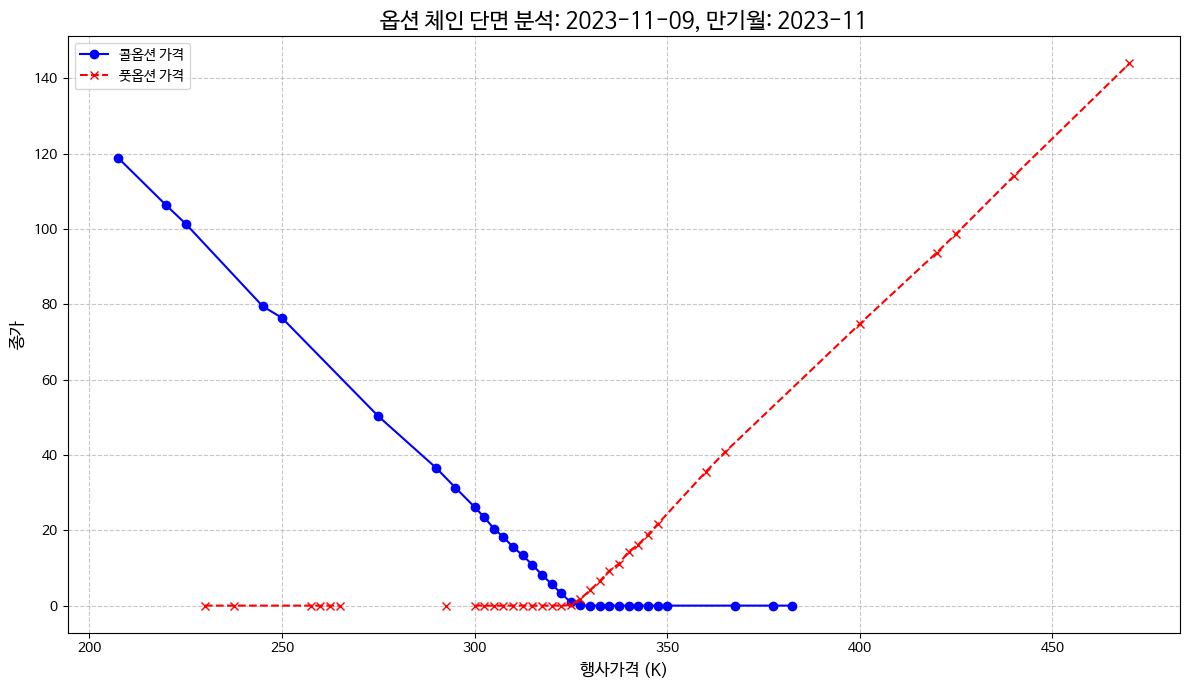

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# --- 0. Matplotlib 한글 폰트 설정 (이전 셀에서 이미 설치되었다고 가정) ---
# 이전에 NanumBarunGothic 폰트가 설치 및 설정되었다고 가정합니다.
# 만약 설정이 안 되어 있다면 아래 주석 처리된 코드를 활성화하여 실행해 주세요.
# !sudo apt-get update -qq
# !sudo apt-get install -y fonts-nanum
# !fc-cache -fv
# fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
plt.rcParams['font.family'] = 'NanumBarunGothic'
plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display

# --- 1. 표본기간 내에서 임의의 특정 거래일 t를 하나 지정하여 데이터를 필터링 ---
# 사용자가 요청한 DataFrame 이름은 'df'이나, 현재 노트북 상태에서는 'kospi200_final_with_ltd_df'입니다.
# 'kospi200_final_with_ltd_df'가 비어있는 경우를 대비하여 처리 로직을 추가합니다.

# kospi200_final_with_ltd_df가 존재하지 않거나 비어있는 경우,
# 이전에 저장된 'KOSPI200_final_liquid_filtered.csv' 파일에서 로드 시도
if 'kospi200_final_with_ltd_df' not in locals() or kospi200_final_with_ltd_df.empty:
    try:
        kospi200_final_with_ltd_df = pd.read_csv('KOSPI200_final_liquid_filtered.csv')
        kospi200_final_with_ltd_df['일자_datetime'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_datetime'])
        print("kospi200_final_with_ltd_df를 'KOSPI200_final_liquid_filtered.csv'에서 로드했습니다.")
    except FileNotFoundError:
        print("오류: 'KOSPI200_final_liquid_filtered.csv' 파일을 찾을 수 없습니다.\n'Part 1: 원자료 정리와 근월물(near-month) 데이터셋 구축)'의 모든 셀을 실행하여 해당 파일을 생성해야 합니다.")
        # 임시로 빈 데이터프레임을 생성하여 이후 코드에서 오류가 발생하지 않도록 합니다.
        kospi200_final_with_ltd_df = pd.DataFrame(columns=[
            '일자_datetime', '결제월', '옵션 종류', 'K', '종가', 'm_t_near' # 필요한 컬럼 추가
        ])
    except Exception as e:
        print(f"데이터 로드 중 오류 발생: {e}")
        kospi200_final_with_ltd_df = pd.DataFrame(columns=[
            '일자_datetime', '결제월', '옵션 종류', 'K', '종가', 'm_t_near' # 필요한 컬럼 추가
        ])

# 최종적으로 사용할 데이터프레임 변수명 (사용자 요청에 따라 'df' 대신 원본 변수명 사용)
df = kospi200_final_with_ltd_df.copy()

# '일자_datetime' 컬럼이 datetime 형식인지 확인
if not pd.api.types.is_datetime64_any_dtype(df['일자_datetime']):
    df['일자_datetime'] = pd.to_datetime(df['일자_datetime'])

# 분석할 특정 거래일 설정 (예시: '2026-05-22')
selected_trading_day = '2023-11-09' # 예시 날짜를 실제 데이터에 있을 법한 날짜로 변경 (2026-05-22 데이터는 없을 가능성 높음)
# 선택한 거래일을 datetime 객체로 변환 (시간 정보 없이 날짜만 비교하기 위해 normalize() 사용)
selected_trading_day_dt = pd.to_datetime(selected_trading_day).normalize()

print(f"분석할 거래일: {selected_trading_day_dt.strftime('%Y-%m-%d')}")

# 해당 거래일에 해당하는 데이터 필터링
daily_options_df = df[df['일자_datetime'].dt.normalize() == selected_trading_day_dt].copy()

if daily_options_df.empty:
    print(f"오류: {selected_trading_day_dt.strftime('%Y-%m-%d')} 날짜에 해당하는 옵션 데이터가 없습니다. 다른 날짜를 선택하거나 데이터를 확인하세요.")
else:
    # --- 2. 선택한 거래일에 거래된 옵션 중, 동일한 결제월(monthly maturity)을 가지는 옵션만 추출 ---
    # 이전에 계산된 m_t_near 컬럼을 사용하여 근월물 만기월을 가져옵니다.
    # 해당 날짜의 모든 옵션이 동일한 m_t_near를 가질 것이라고 가정합니다.
    selected_maturity_month = daily_options_df['m_t_near'].iloc[0]

    if pd.isna(selected_maturity_month) or selected_maturity_month is None:
        print(f"오류: {selected_trading_day_dt.strftime('%Y-%m-%d')} 날짜에 해당하는 근월물(m_t_near) 데이터가 없습니다.\n'Part 1'의 롤오버 계산이 올바르게 수행되었는지 확인하거나 다른 날짜를 선택하세요.")
    else:
        print(f"선택한 만기월: {selected_maturity_month}")

        # 근월물 만기월을 가지는 콜옵션과 풋옵션 모두 추출
        filtered_options_chain = daily_options_df[
            (daily_options_df['결제월'] == selected_maturity_month) &
            (daily_options_df['옵션 종류'].isin(['Call', 'Put']))
        ].copy()

        # --- 3. 추출된 만기월 옵션 데이터를 행사가격(K) 기준으로 오름차순 정렬 ---
        if not filtered_options_chain.empty:
            filtered_options_chain.sort_values(by=['K', '옵션 종류'], ascending=[True, True], inplace=True)

            print("\n--- 선택된 거래일 및 만기월 옵션 데이터 (상위 10개 행) ---")
            display_columns = ['종목명', '옵션 종류', 'K', '종가', 'S_t', 'Moneyness (M)', 'Final_LTD']
            # 실제 컬럼명과 요청된 컬럼명을 맞춰서 출력
            available_display_columns = [col for col in display_columns if col in filtered_options_chain.columns]
            print(filtered_options_chain[available_display_columns].head(10).to_string(index=False))
            print(f"\n총 {len(filtered_options_chain)}개의 옵션이 추출되었습니다.")

            # --- 4. 행사가격(K)을 가로축(X축)으로 하고, 옵션 종가를 세로축(Y축)으로 하여 'Call 가격 곡선'과 'Put 가격 곡선'을 한 그래프 위에 함께 시각화 ---
            plt.figure(figsize=(12, 7))

            # 콜옵션 데이터 필터링
            call_options = filtered_options_chain[filtered_options_chain['옵션 종류'] == 'Call']
            # 풋옵션 데이터 필터링
            put_options = filtered_options_chain[filtered_options_chain['옵션 종류'] == 'Put']

            # Call 가격 곡선 시각화
            plt.plot(call_options['K'], call_options['종가'], label='콜옵션 가격', marker='o', linestyle='-', color='blue')
            # Put 가격 곡선 시각화
            plt.plot(put_options['K'], put_options['종가'], label='풋옵션 가격', marker='x', linestyle='--', color='red')

            # 그래프 설정
            plt.title(f'옵션 체인 단면 분석: {selected_trading_day_dt.strftime("%Y-%m-%d")}, 만기월: {selected_maturity_month}', fontsize=16)
            plt.xlabel('행사가격 (K)', fontsize=12)
            plt.ylabel('종가', fontsize=12)
            plt.legend(fontsize=10) # 범례
            plt.grid(True, linestyle='--', alpha=0.7)
            plt.tight_layout()
            plt.show()
        else:
            print("해당 조건에 맞는 옵션 데이터가 없습니다.")

2. ATM, ITM, OTM 분류

In [ ]:
import pandas as pd

# Assuming filtered_options_chain and selected_trading_day_dt are available from the previous cell
# If not, for standalone execution, uncomment and run the following lines:
# # --- FOR STANDALONE EXECUTION IF previous cell is not run or variable is lost ---
# # Load the filtered data (this should ideally be passed from the previous step)
# # This part is commented out because filtered_options_chain is expected to be in scope.
# # try:
# #     df = pd.read_csv('KOSPI200_final_liquid_filtered.csv') # Or the final dataframe with all columns
# #     df['일자_datetime'] = pd.to_datetime(df['일자_datetime'])
# # except FileNotFoundError:
# #     print("Error: 'KOSPI200_final_liquid_filtered.csv' not found. Please run Part 1 and Part 2.1 cells.")
# #     df = pd.DataFrame() # Create empty DataFrame to prevent errors

# # selected_trading_day = '2023-11-09' # Example day, ensure it exists in your data
# # selected_trading_day_dt = pd.to_datetime(selected_trading_day).normalize()
# # daily_options_df = df[df['일자_datetime'].dt.normalize() == selected_trading_day_dt].copy()
# # selected_maturity_month = daily_options_df['m_t_near'].iloc[0] if not daily_options_df.empty else None

# # if not daily_options_df.empty and selected_maturity_month:
# #     filtered_options_chain = daily_options_df[
# #         (daily_options_df['결제월'] == selected_maturity_month) &
# #         (daily_options_df['옵션 종류'].isin(['Call', 'Put']))
# #     ].copy()
# #     # Ensure K and S_t are numeric and available
# #     filtered_options_chain['K'] = pd.to_numeric(filtered_options_chain['K'], errors='coerce')
# #     filtered_options_chain['S_t'] = pd.to_numeric(filtered_options_chain['S_t'], errors='coerce')
# #     filtered_options_chain.dropna(subset=['K', 'S_t', '옵션 종류'], inplace=True)
# # else:
# #     print("Error: No data available for the selected trading day or maturity month.")
# #     filtered_options_chain = pd.DataFrame(columns=['옵션 종류', 'K', 'S_t', '종목명', '종가'])


# --- 1. 선택한 날짜의 KOSPI200 현물지수 종가(St) 가져오기 ---
if 'filtered_options_chain' in locals() and not filtered_options_chain.empty:
    S_t = filtered_options_chain['S_t'].iloc[0]  # St는 해당 거래일의 모든 옵션에 대해 동일
    print(f"분석 날짜: {selected_trading_day_dt.strftime('%Y-%m-%d')}")
    print(f"KOSPI200 현물지수 종가 (St): {S_t:.2f}\n")

    # ATM 정의를 위한 허용 오차(epsilon) 설정
    # 일반적으로 S_t의 일정 비율 또는 고정 값 사용
    epsilon = 1.0 # 예를 들어, St 기준 상하 1.0 포인트 이내

    # --- 2. ATM, ITM, OTM 분류 함수 정의 ---
    def classify_option(row, S_t, epsilon):
        option_type = row['옵션 종류']
        K = row['K']

        if option_type == 'Call':
            if abs(K - S_t) <= epsilon:  # ATM 조건: K와 St가 epsilon 범위 내
                return 'ATM'
            elif S_t > K:  # ITM 조건: St가 K보다 높음
                return 'ITM'
            else:  # OTM 조건: St가 K보다 낮음
                return 'OTM'
        elif option_type == 'Put':
            if abs(K - S_t) <= epsilon:  # ATM 조건: K와 St가 epsilon 범위 내
                return 'ATM'
            elif S_t < K:  # ITM 조건: St가 K보다 낮음
                return 'ITM'
            else:  # OTM 조건: St가 K보다 높음
                return 'OTM'
        return None # 옵션 종류가 Call/Put이 아닌 경우

    # --- 3. 분류 적용 및 결과 출력 ---
    # 'filtered_options_chain' 복사본에 분류 결과를 추가합니다.
    classified_options_df = filtered_options_chain.copy()
    classified_options_df['ATM_ITM_OTM'] = classified_options_df.apply(lambda row: classify_option(row, S_t, epsilon), axis=1)

    # 결과를 옵션 종류 및 분류별로 정렬하여 표시
    classified_options_df.sort_values(by=['옵션 종류', 'ATM_ITM_OTM', 'K'], inplace=True)

    print("--- 콜옵션 분류 결과 ---")
    call_options_classified = classified_options_df[classified_options_df['옵션 종류'] == 'Call']
    if not call_options_classified.empty:
        display_cols = ['종목명', '옵션 종류', 'K', 'S_t', '종가', 'ATM_ITM_OTM']
        print(call_options_classified[display_cols].to_string(index=False))
    else:
        print("해당하는 콜옵션 데이터가 없습니다.")

    print("\n--- 풋옵션 분류 결과 ---")
    put_options_classified = classified_options_df[classified_options_df['옵션 종류'] == 'Put']
    if not put_options_classified.empty:
        display_cols = ['종목명', '옵션 종류', 'K', 'S_t', '종가', 'ATM_ITM_OTM']
        print(put_options_classified[display_cols].to_string(index=False))
    else:
        print("해당하는 풋옵션 데이터가 없습니다.")

    print("\n--- 분류별 요약 ---")
    print(classified_options_df.groupby(['옵션 종류', 'ATM_ITM_OTM']).size().unstack(fill_value=0))

else:
    print("분류할 옵션 데이터가 없습니다. 이전 셀을 실행하여 'filtered_options_chain'을 생성했는지 확인하세요.")

분석 날짜: 2023-11-09
KOSPI200 현물지수 종가 (St): 325.29

--- 콜옵션 분류 결과 ---
                  종목명 옵션 종류     K    S_t     종가 ATM_ITM_OTM
코스피200 C 202311 325.0  Call 325.0 325.29   0.88         ATM
코스피200 C 202311 207.5  Call 207.5 325.29 118.85         ITM
코스피200 C 202311 220.0  Call 220.0 325.29 106.25         ITM
코스피200 C 202311 225.0  Call 225.0 325.29 101.40         ITM
코스피200 C 202311 245.0  Call 245.0 325.29  79.50         ITM
코스피200 C 202311 250.0  Call 250.0 325.29  76.40         ITM
코스피200 C 202311 275.0  Call 275.0 325.29  50.30         ITM
코스피200 C 202311 290.0  Call 290.0 325.29  36.60         ITM
코스피200 C 202311 295.0  Call 295.0 325.29  31.35         ITM
코스피200 C 202311 300.0  Call 300.0 325.29  26.20         ITM
코스피200 C 202311 302.5  Call 302.5 325.29  23.50         ITM
코스피200 C 202311 305.0  Call 305.0 325.29  20.45         ITM
코스피200 C 202311 307.5  Call 307.5 325.29  18.20         ITM
코스피200 C 202311 310.0  Call 310.0 325.29  15.55         ITM
코스피200 C 202311 312.5  Call 312.5

선택한 만기월 옵션 중 거래량 기준 상위 5개 옵션을 식별


In [ ]:
import pandas as pd

# Assuming `classified_options_df` is available from the previous cell
# and contains options for the selected trading day and maturity month.

if 'classified_options_df' in locals() and not classified_options_df.empty:
    print(f"\n--- 거래량 기준 상위 5개 옵션 (거래일: {selected_trading_day_dt.strftime('%Y-%m-%d')}, 만기월: {selected_maturity_month}) ---")

    # Sort by '거래량' (Volume) in descending order and select the top 5
    top_5_by_volume = classified_options_df.sort_values(by='거래량', ascending=False).head(5)

    # Define the columns to display as requested by the user
    display_cols = [
        '옵션 종류',
        'K',          # 행사가격
        '종가',       # 종가
        '거래량',     # 거래량
        '미결제약정'  # 미결제약정
    ]

    # Display the results
    print(top_5_by_volume[display_cols].to_string(index=False))

else:
    print("오류: 'classified_options_df'를 찾을 수 없거나 비어 있습니다. 이전 옵션 분류 셀을 실행했는지 확인하세요.")


--- 거래량 기준 상위 5개 옵션 (거래일: 2023-11-09, 만기월: 2023-11) ---
옵션 종류     K   종가     거래량  미결제약정
 Call 327.5 0.06 1126691      0
  Put 325.0 0.19  725780      0
 Call 325.0 0.88  677250      0
  Put 322.5 0.02  675731      0
 Call 330.0 0.01  408563      0


선택한 만기월 옵션 중 미결제약정 기준 상위 5개 옵션을 식별

In [ ]:
import pandas as pd

# Assuming `classified_options_df` is available from the previous cell
# and contains options for the selected trading day and maturity month.

if 'classified_options_df' in locals() and not classified_options_df.empty:
    print(f"\n--- 미결제약정 기준 상위 5개 옵션 (거래일: {selected_trading_day_dt.strftime('%Y-%m-%d')}, 만기월: {selected_maturity_month}) ---")

    # Sort by '미결제약정' (Open Interest) in descending order and select the top 5
    top_5_by_open_interest = classified_options_df.sort_values(by='미결제약정', ascending=False).head(5)

    # Define the columns to display as requested by the user
    display_cols = [
        '옵션 종류',
        'K',          # 행사가격
        '종가',       # 종가
        '거래량',     # 거래량
        '미결제약정'  # 미결제약정
    ]

    # Display the results
    print(top_5_by_open_interest[display_cols].to_string(index=False))

else:
    print("오류: 'classified_options_df'를 찾을 수 없거나 비어 있습니다. 이전 옵션 분류 셀을 실행했는지 확인하세요.")


--- 미결제약정 기준 상위 5개 옵션 (거래일: 2023-11-09, 만기월: 2023-11) ---
옵션 종류     K     종가    거래량  미결제약정
 Call 325.0   0.88 677250      0
 Call 207.5 118.85     17      0
 Call 220.0 106.25      2      0
 Call 225.0 101.40      1      0
 Call 245.0  79.50      4      0


# Part 3:  Near-Month rollover를 반영한 고정 moneyness 시계열 구축

In [ ]:
import pandas as pd
import numpy as np

# Assuming kospi200_final_with_ltd_df is the latest filtered dataframe
# from previous steps. Let's rename it to 'df' as requested for this task.
df = kospi200_final_with_ltd_df.copy()

print("Starting fixed moneyness rollover strategy implementation...")

# Ensure necessary columns are in correct format
df['일자_datetime'] = pd.to_datetime(df['일자_datetime'])
df['Final_LTD'] = pd.to_datetime(df['Final_LTD'])

# Filter out rows where essential data is missing (e.g., strike, S_t, moneyness, option type, m_t_near)
# The liquidity filter has already removed options with 0 volume and 0 open interest.
df_clean = df.dropna(subset=['일자_datetime', 'K', 'S_t', 'Moneyness (M)', '옵션 종류', '거래량', '미결제약정', 'Final_LTD', 'm_t_near']).copy()

# Define the target moneyness values
target_moneyness_values = [0.9, 1.0, 1.1]

# List to store the final selected options for all trading days and target moneyness values
all_selected_options = []

# Process each unique trading day
unique_trading_days = df_clean['일자_datetime'].dt.normalize().unique()
unique_trading_days = np.sort(unique_trading_days)

# Progress tracking
print(f"Processing {len(unique_trading_days)} unique trading days...")
progress_counter = 0
total_days = len(unique_trading_days)

for current_date_dt in unique_trading_days:
    progress_counter += 1
    if progress_counter % 1000 == 0:
        print(f"  Processed {progress_counter}/{total_days} days...")

    # Filter data for the current trading day and its near-month options
    # We must explicitly filter by m_t_near, not just current_date_dt
    # A single day could theoretically have multiple m_t_near values if there's an error in logic,
    # but based on previous steps, each day should have one m_t_near.
    current_day_data = df_clean[df_clean['일자_datetime'].dt.normalize() == current_date_dt].copy()

    if current_day_data.empty:
        continue

    # Get the near-month for this specific trading day
    # Assuming m_t_near is consistent for a given 일자_datetime
    current_m_t_near = current_day_data['m_t_near'].iloc[0]

    # Filter options that belong to the near-month for this trading day
    near_month_options = current_day_data[current_day_data['결제월'] == current_m_t_near].copy()

    if near_month_options.empty:
        # No near-month options for this day, skip to next
        continue

    # Get the underlying price for the current day
    # Assuming S_t is consistent for a given 일자_datetime
    current_S_t = near_month_options['S_t'].iloc[0]

    for g in target_moneyness_values:
        # Calculate the absolute difference from the target moneyness for all near-month options
        near_month_options['Abs_Diff_Moneyness'] = abs(near_month_options['Moneyness (M)'] - g)

        # Find the minimum absolute difference for this target moneyness (g) across all option types
        min_abs_diff = near_month_options['Abs_Diff_Moneyness'].min()

        # Select all options that have this minimum absolute difference
        candidate_options_for_strike = near_month_options[
            near_month_options['Abs_Diff_Moneyness'] == min_abs_diff
        ].copy()

        if candidate_options_for_strike.empty:
            continue

        # Apply tie-breaking rules to determine the *optimal strike price* for this target moneyness (g)
        # We need to consider both Call and Put options to find the single best strike
        sorted_candidates = candidate_options_for_strike.sort_values(
            by=['거래량', '미결제약정', 'K'],
            ascending=[False, False, True] # Descending volume, Descending open interest, Ascending strike price
        )

        # Select the top option based on tie-breaking.
        # This gives us the characteristics of the *strike* we want to use for pairing.
        optimal_option_info = sorted_candidates.iloc[0]

        optimal_K = optimal_option_info['K']
        optimal_maturity_date = optimal_option_info['Final_LTD']

        # Now, select both Call and Put options that have this optimal_K and optimal_maturity_date
        # from the original near_month_options (before calculating Abs_Diff_Moneyness to avoid re-computing)
        paired_options = near_month_options[
            (near_month_options['K'] == optimal_K) &
            (near_month_options['Final_LTD'] == optimal_maturity_date)
        ].copy()

        # Add the target moneyness to these selected options
        paired_options['target_moneyness'] = g

        # Append selected options to the list
        for idx, row in paired_options.iterrows():
            all_selected_options.append({
                'date': row['일자_datetime'].date(),
                'target_moneyness': g,
                'strike_price': row['K'],
                'underlying_price': row['S_t'],
                'maturity_date': row['Final_LTD'].date(),
                'option_type': row['옵션 종류'],
                'volume': row['거래량'],
                'open_interest': row['미결제약정'],
                'price': row['종가'],
                'moneyness': row['Moneyness (M)'],
                'option_name': row['종목명'], # Added for more complete information
                'settlement_month_near': row['m_t_near'] # Added for more complete information
            })

# Create the final DataFrame
final_df = pd.DataFrame(all_selected_options)

# Sort the final DataFrame as requested
final_df.sort_values(by=['date', 'target_moneyness'], inplace=True)

print("\nFixed moneyness rollover strategy implementation complete.")
print("\n--- Resulting DataFrame Head ---")
print(final_df.head())
print(f"\nTotal rows in final DataFrame: {len(final_df)}")
print(f"Unique dates in final DataFrame: {final_df['date'].nunique()}")

# Optionally, save the result
output_file_name = 'KOSPI200_fixed_moneyness_rollover.csv'
final_df.to_csv(output_file_name, index=False, encoding='utf-8-sig')
print(f"\nFinal data saved to {output_file_name}")

Starting fixed moneyness rollover strategy implementation...
Processing 4512 unique trading days...
  Processed 1000/4512 days...
  Processed 2000/4512 days...
  Processed 3000/4512 days...
  Processed 4000/4512 days...

Fixed moneyness rollover strategy implementation complete.

--- Resulting DataFrame Head ---
         date  target_moneyness  strike_price  underlying_price maturity_date  \
0  2007-08-27               0.9         205.0            228.65    2007-09-13   
1  2007-08-27               0.9         205.0            228.65    2007-09-13   
2  2007-08-27               1.0         227.5            228.65    2007-09-13   
3  2007-08-27               1.0         227.5            228.65    2007-09-13   
4  2007-08-27               1.1         252.5            228.65    2007-09-13   

  option_type  volume  open_interest  price  moneyness            option_name  \
0        Call      18          12223  25.00      0.897  코스피200 C 200709 205.0   
1         Put  302764          69297 

In [ ]:
from google.colab import files

output_file_name = 'KOSPI200_fixed_moneyness_rollover.csv'
files.download(output_file_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

# 1. Load the generated KOSPI200_fixed_moneyness_rollover.csv
print("Loading KOSPI200_fixed_moneyness_rollover.csv...")
final_strategy_df = pd.read_csv('KOSPI200_fixed_moneyness_rollover.csv')

# Convert date columns to datetime objects
final_strategy_df['date'] = pd.to_datetime(final_strategy_df['date'])
final_strategy_df['maturity_date'] = pd.to_datetime(final_strategy_df['maturity_date'])

# 2. Calculate TTM (Time to Maturity)
# TTM in years (assuming 365.25 days for simplicity)
final_strategy_df['TTM_years'] = (final_strategy_df['maturity_date'] - final_strategy_df['date']).dt.days / 365.25
final_strategy_df['TTM_days'] = (final_strategy_df['maturity_date'] - final_strategy_df['date']).dt.days

# 3. Merge with kospi200_final_with_ltd_df to get '내재변동성' (Implied Volatility)
# Ensure '일자_datetime' in kospi200_final_with_ltd_df is datetime
kospi200_final_with_ltd_df['일자_datetime'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_datetime'])

# Prepare kospi200_final_with_ltd_df for merge (select only necessary columns)
iv_source_df = kospi200_final_with_ltd_df[[
    '일자_datetime', '종목명', '옵션 종류', 'K', '내재변동성'
]].copy()

# Rename columns in iv_source_df to match final_strategy_df for merge keys
iv_source_df.rename(columns={
    '일자_datetime': 'date',
    '종목명': 'option_name',
    '옵션 종류': 'option_type',
    'K': 'strike_price',
    '내재변동성': 'implied_volatility'
}, inplace=True)

# Before merging, drop existing 'implied_volatility' if it was loaded from CSV (it won't be, but for safety)
if 'implied_volatility' in final_strategy_df.columns:
    final_strategy_df = final_strategy_df.drop(columns=['implied_volatility'])

# Perform the merge using multiple keys for robust matching
final_strategy_df = pd.merge(
    final_strategy_df,
    iv_source_df,
    on=['date', 'option_name', 'option_type', 'strike_price'],
    how='left'
)
print("Implied volatility (내재변동성) merged.")
print(f"Nulls in implied_volatility after merge: {final_strategy_df['implied_volatility'].isnull().sum()}")


# 4. Reshape the DataFrame into the desired time-series format
print("Reshaping to time-series format...")

# Columns to extract for each option type and target moneyness
# 'price' corresponds to C/P_0.9,t, C/P_1.0,t, C/P_1.1,t
# 'strike_price' corresponds to K_t for each moneyness
value_cols = ['price', 'strike_price', 'TTM_years', 'volume', 'open_interest', 'implied_volatility']
target_moneyness_values = sorted(final_strategy_df['target_moneyness'].unique())

# Prepare a list to collect data for the final time-series DataFrame
ts_data_rows = []

# Process each unique date
unique_dates = final_strategy_df['date'].unique()
unique_dates = np.sort(unique_dates) # Ensure chronological order

for current_date in unique_dates:
    daily_data = final_strategy_df[final_strategy_df['date'] == current_date].copy()
    if daily_data.empty:
        continue

    row_dict = {'date': current_date}

    for tm in target_moneyness_values:
        # Filter for the current target moneyness
        tm_data = daily_data[daily_data['target_moneyness'] == tm]

        call_data = tm_data[tm_data['option_type'] == 'Call']
        put_data = tm_data[tm_data['option_type'] == 'Put']

        for col in value_cols:
            # Extract value for Call option. Use np.nan if no data found.
            call_val = call_data[col].iloc[0] if not call_data.empty else np.nan
            # Extract value for Put option. Use np.nan if no data found.
            put_val = put_data[col].iloc[0] if not put_data.empty else np.nan

            # Append to row_dict with appropriate column names
            row_dict[f'C_{tm}_{col}'] = call_val
            row_dict[f'P_{tm}_{col}'] = put_val
    ts_data_rows.append(row_dict)

# Create the final time-series DataFrame
final_ts_df = pd.DataFrame(ts_data_rows)

# Set 'date' as index as requested implicitly or as first column
final_ts_df.set_index('date', inplace=True)
final_ts_df.sort_index(inplace=True) # Ensure index is sorted chronologically

print("Time-series DataFrame created.")
print("\n--- Final Time-series DataFrame Head ---")
print(final_ts_df.head())
print(f"\nTotal rows in final time-series DataFrame: {len(final_ts_df)}")
print(f"Total columns: {len(final_ts_df.columns)}")

# Save the final time-series DataFrame to CSV
output_ts_file_name = 'KOSPI200_fixed_moneyness_time_series.csv'
final_ts_df.to_csv(output_ts_file_name, encoding='utf-8-sig')
print(f"\nFinal time-series data saved to {output_ts_file_name}")

# Display some information about the output columns
print("\n--- Sample of output columns (first 10) ---")
print(final_ts_df.columns.tolist()[:10])
print("\n--- Sample of output columns (last 10) ---")
print(final_ts_df.columns.tolist()[-10:])

# Download the generated CSV file
files.download(output_ts_file_name)


Loading KOSPI200_fixed_moneyness_rollover.csv...
Implied volatility (내재변동성) merged.
Nulls in implied_volatility after merge: 0
Reshaping to time-series format...
Time-series DataFrame created.

--- Final Time-series DataFrame Head ---
            C_0.9_price  P_0.9_price  C_0.9_strike_price  P_0.9_strike_price  \
date                                                                           
2007-08-27        25.00         0.91               205.0               205.0   
2007-08-28        24.15         1.02               210.0               210.0   
2007-08-29        24.00         1.00               210.0               210.0   
2007-08-30        25.90         0.70               210.0               210.0   
2007-08-31        25.05         0.63               215.0               215.0   

            C_0.9_TTM_years  P_0.9_TTM_years  C_0.9_volume  P_0.9_volume  \
date                                                                       
2007-08-27         0.046543         0.046543        

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 4. 시계열 그래프 작성

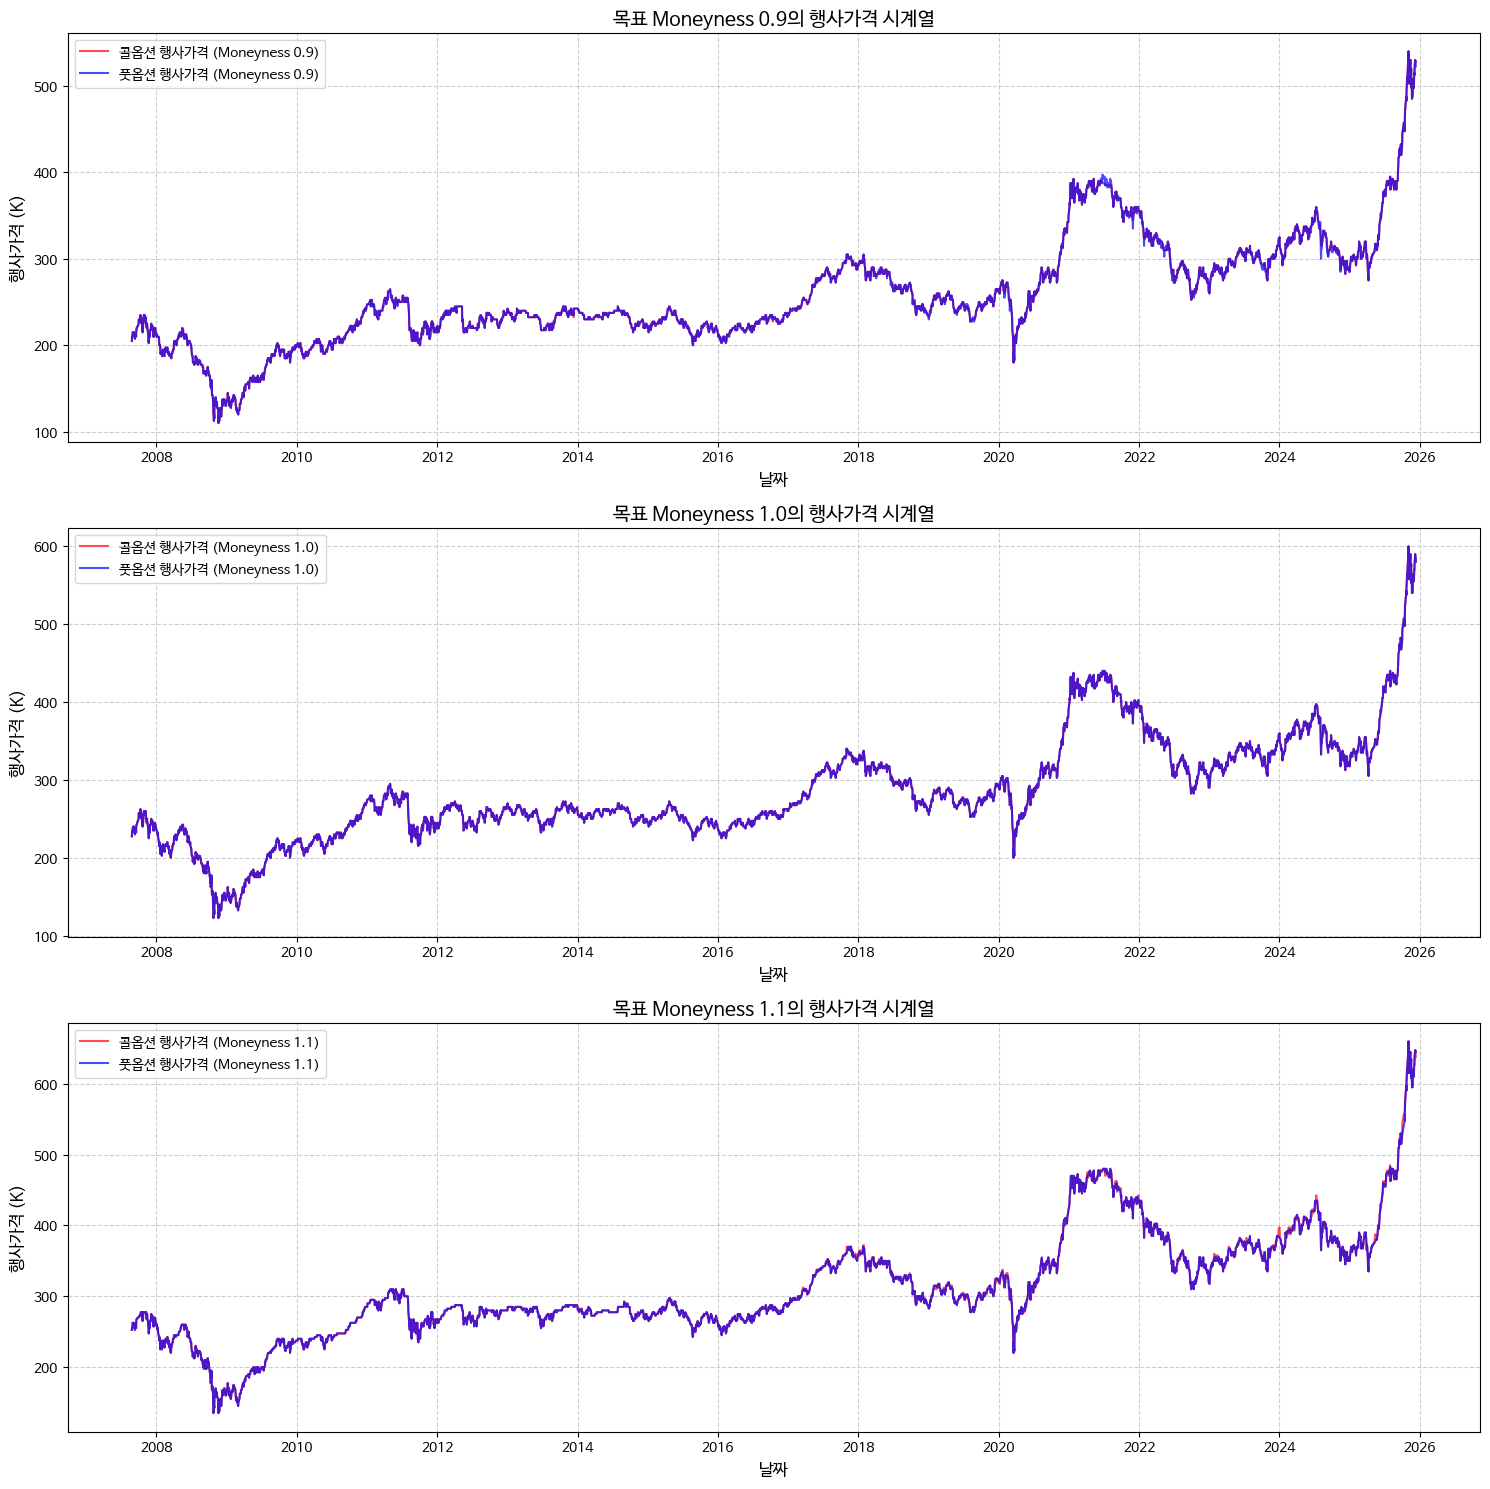

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Load the time series data if not already in memory
# Assuming final_ts_df is already loaded from previous steps as KOSPI200_fixed_moneyness_time_series.csv
# If not, uncomment the following line:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

target_moneyness_values = [0.9, 1.0, 1.1]

plt.figure(figsize=(15, 15))

for i, tm in enumerate(target_moneyness_values):
    plt.subplot(len(target_moneyness_values), 1, i + 1)

    call_strike_col = f'C_{tm}_strike_price'
    put_strike_col = f'P_{tm}_strike_price'

    # Plot Call option strike price
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=call_strike_col, label=f'콜옵션 행사가격 (Moneyness {tm})', color='red', alpha=0.7)
    # Plot Put option strike price
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=put_strike_col, label=f'풋옵션 행사가격 (Moneyness {tm})', color='blue', alpha=0.7)

    plt.title(f'목표 Moneyness {tm}의 행사가격 시계열', fontsize=14)
    plt.xlabel('날짜', fontsize=12)
    plt.ylabel('행사가격 (K)', fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Save the plot to a PNG file
plot_filename = 'KOSPI200_Strike_Price_TimeSeries_Moneyness.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
plt.show() # Display the plot

# Download the generated plot
files.download(plot_filename)


각 목표 moneyness에 대해, 선택된 call 옵션 종가와 그 변화율의 시계열

/tmp/ipykernel_2542/4148261570.py:46: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  call_price_change = final_ts_df[call_price_col].pct_change() * 100 # Convert to percentage
/tmp/ipykernel_2542/4148261570.py:46: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  call_price_change = final_ts_df[call_price_col].pct_change() * 100 # Convert to percentage


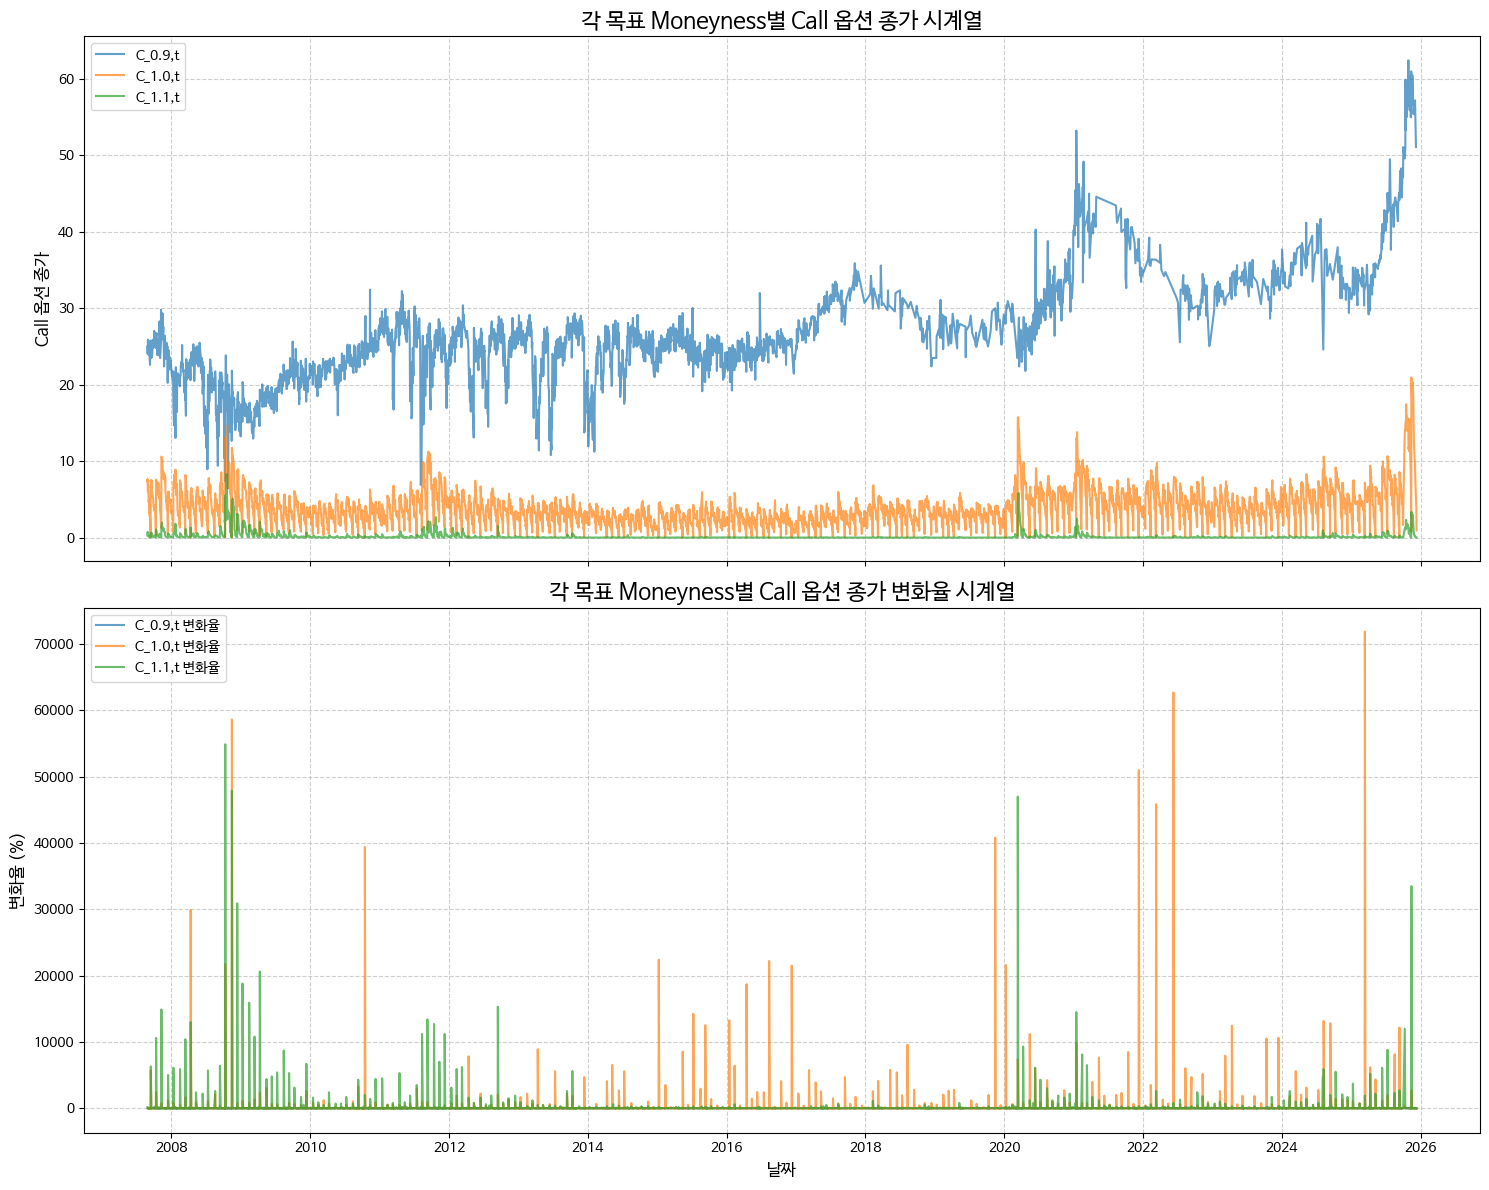

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Load the time series data if final_ts_df is not already in memory
# (Assuming final_ts_df is already loaded from previous steps as KOSPI200_fixed_moneyness_time_series.csv)
# If not, uncomment the following line:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

target_moneyness_values = [0.9, 1.0, 1.1]

# Create a figure with two subplots
fig, axes = plt.subplots(2, 1, figsize=(15, 12), sharex=True)

# --- Subplot 1: Call Option Prices Time Series ---
ax1 = axes[0]
for tm in target_moneyness_values:
    call_price_col = f'C_{tm}_price'
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=call_price_col, label=f'C_{tm},t', ax=ax1, alpha=0.7)

ax1.set_title('각 목표 Moneyness별 Call 옵션 종가 시계열', fontsize=16)
ax1.set_ylabel('Call 옵션 종가', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# --- Subplot 2: Call Option Price Rate of Change Time Series ---
ax2 = axes[1]
for tm in target_moneyness_values:
    call_price_col = f'C_{tm}_price'
    # Calculate the percentage change (rate of change)
    call_price_change = final_ts_df[call_price_col].pct_change() * 100 # Convert to percentage
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=call_price_change, label=f'C_{tm},t 변화율', ax=ax2, alpha=0.7)

ax2.set_title('각 목표 Moneyness별 Call 옵션 종가 변화율 시계열', fontsize=16)
ax2.set_xlabel('날짜', fontsize=12)
ax2.set_ylabel('변화율 (%)', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Save the plot to a PNG file
plot_filename = 'KOSPI200_Call_Price_and_Change_TimeSeries_Moneyness.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
plt.show() # Display the plot

# Download the generated plot
files.download(plot_filename)

각 목표 moneyness에 대해, 선택된 put 옵션 종가와 그 변화율의 시계열

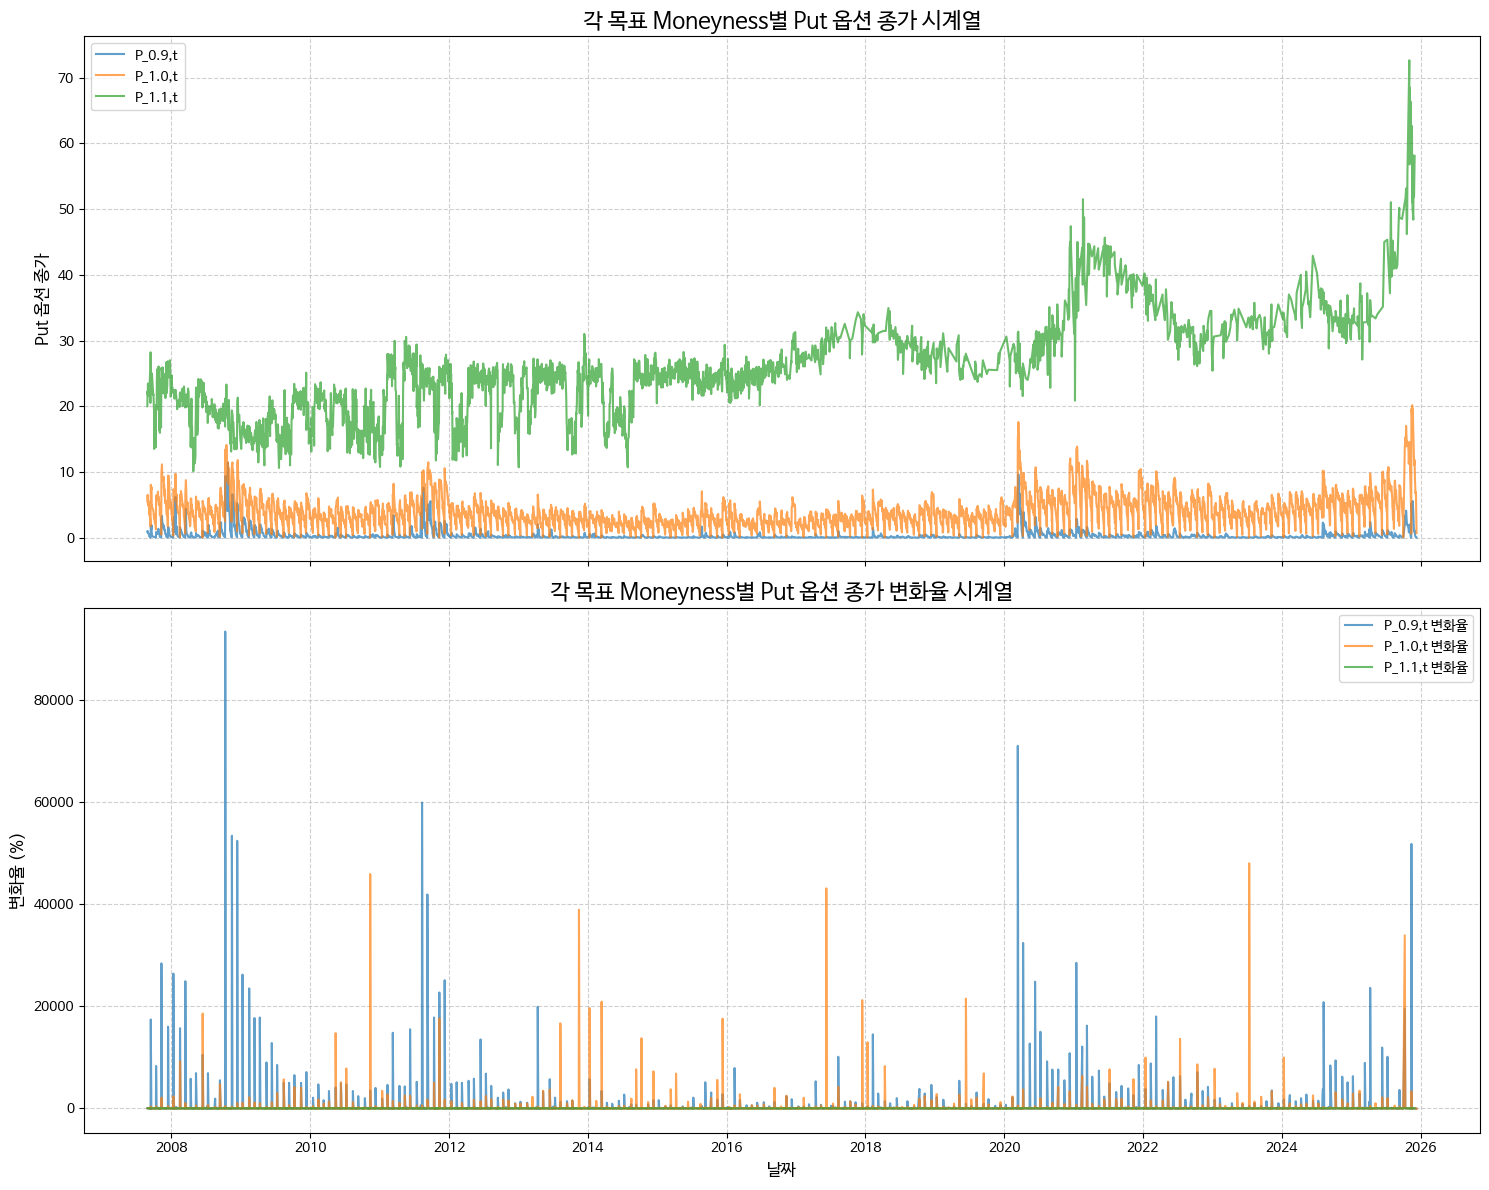

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Load the time series data if final_ts_df is not already in memory
# (Assuming final_ts_df is already loaded from previous steps as KOSPI200_fixed_moneyness_time_series.csv)
# If not, uncomment the following line:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

target_moneyness_values = [0.9, 1.0, 1.1]

# Create a figure with two subplots for put options
fig, axes = plt.subplots(2, 1, figsize=(15, 12), sharex=True)

# --- Subplot 1: Put Option Prices Time Series ---
ax1 = axes[0]
for tm in target_moneyness_values:
    put_price_col = f'P_{tm}_price'
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=put_price_col, label=f'P_{tm},t', ax=ax1, alpha=0.7)

ax1.set_title('각 목표 Moneyness별 Put 옵션 종가 시계열', fontsize=16)
ax1.set_ylabel('Put 옵션 종가', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# --- Subplot 2: Put Option Price Rate of Change Time Series ---
ax2 = axes[1]
for tm in target_moneyness_values:
    put_price_col = f'P_{tm}_price'
    # Calculate the percentage change (rate of change)
    # The default fill_method='pad' in Series.pct_change is deprecated, explicitly set to None.
    put_price_change = final_ts_df[put_price_col].pct_change(fill_method=None) * 100 # Convert to percentage
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=put_price_change, label=f'P_{tm},t 변화율', ax=ax2, alpha=0.7)

ax2.set_title('각 목표 Moneyness별 Put 옵션 종가 변화율 시계열', fontsize=16)
ax2.set_xlabel('날짜', fontsize=12)
ax2.set_ylabel('변화율 (%)', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Save the plot to a PNG file
plot_filename = 'KOSPI200_Put_Price_and_Change_TimeSeries_Moneyness.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
plt.show() # Display the plot

# Download the generated plot
files.download(plot_filename)


ATM 근처 옵션에 대해 풋콜 함께 표시

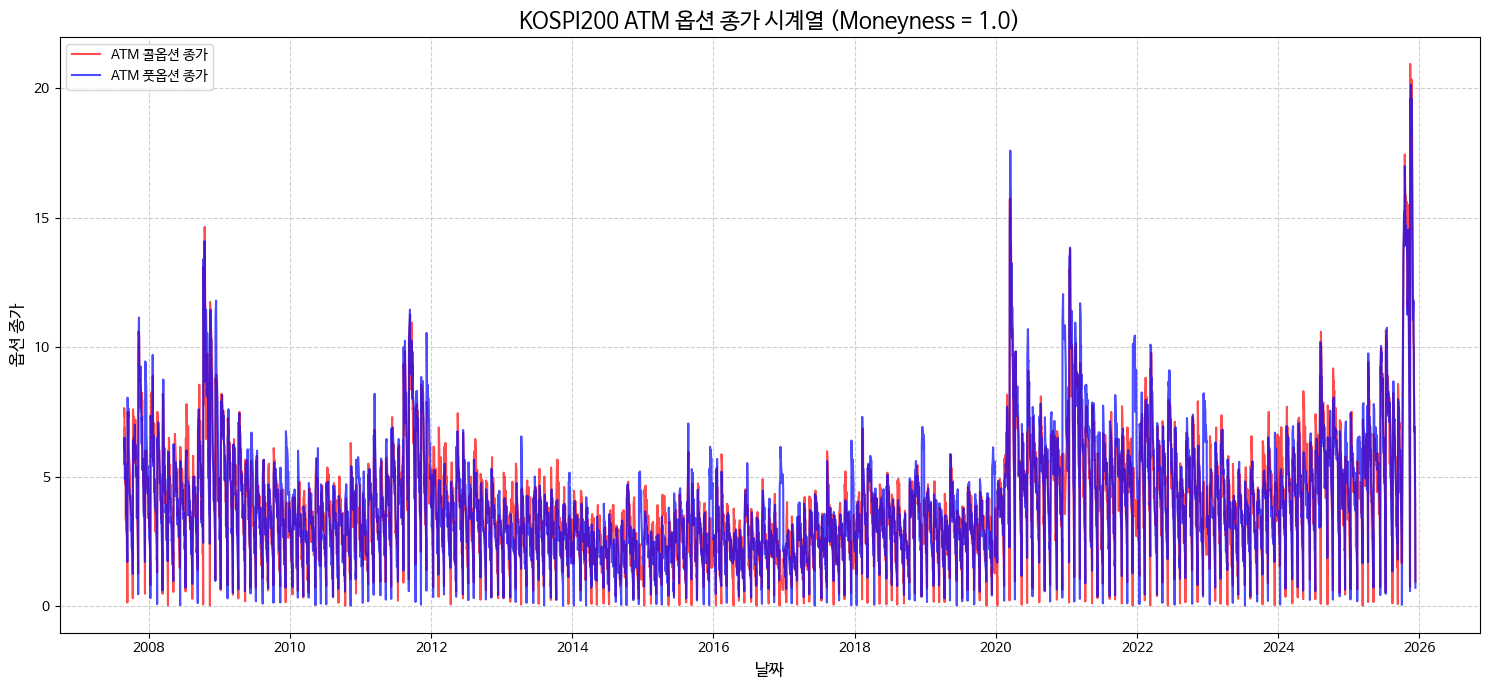

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Assuming final_ts_df is already loaded and available from previous steps
# If not, load it:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

# Filter for ATM (Moneyness 1.0) Call and Put options
atm_call_price_col = 'C_1.0_price'
atm_put_price_col = 'P_1.0_price'

# Create the plot
plt.figure(figsize=(15, 7))

sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=atm_call_price_col, label='ATM 콜옵션 종가', color='red', alpha=0.7)
sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=atm_put_price_col, label='ATM 풋옵션 종가', color='blue', alpha=0.7)

plt.title('KOSPI200 ATM 옵션 종가 시계열 (Moneyness = 1.0)', fontsize=16)
plt.xlabel('날짜', fontsize=12)
plt.ylabel('옵션 종가', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Save the plot to a PNG file
plot_filename = 'KOSPI200_ATM_Price_TimeSeries.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
plt.show() # Display the plot

# Download the generated plot
files.download(plot_filename)


$$Straddle_t = C_{ATM,t} + P_{ATM,t}$$

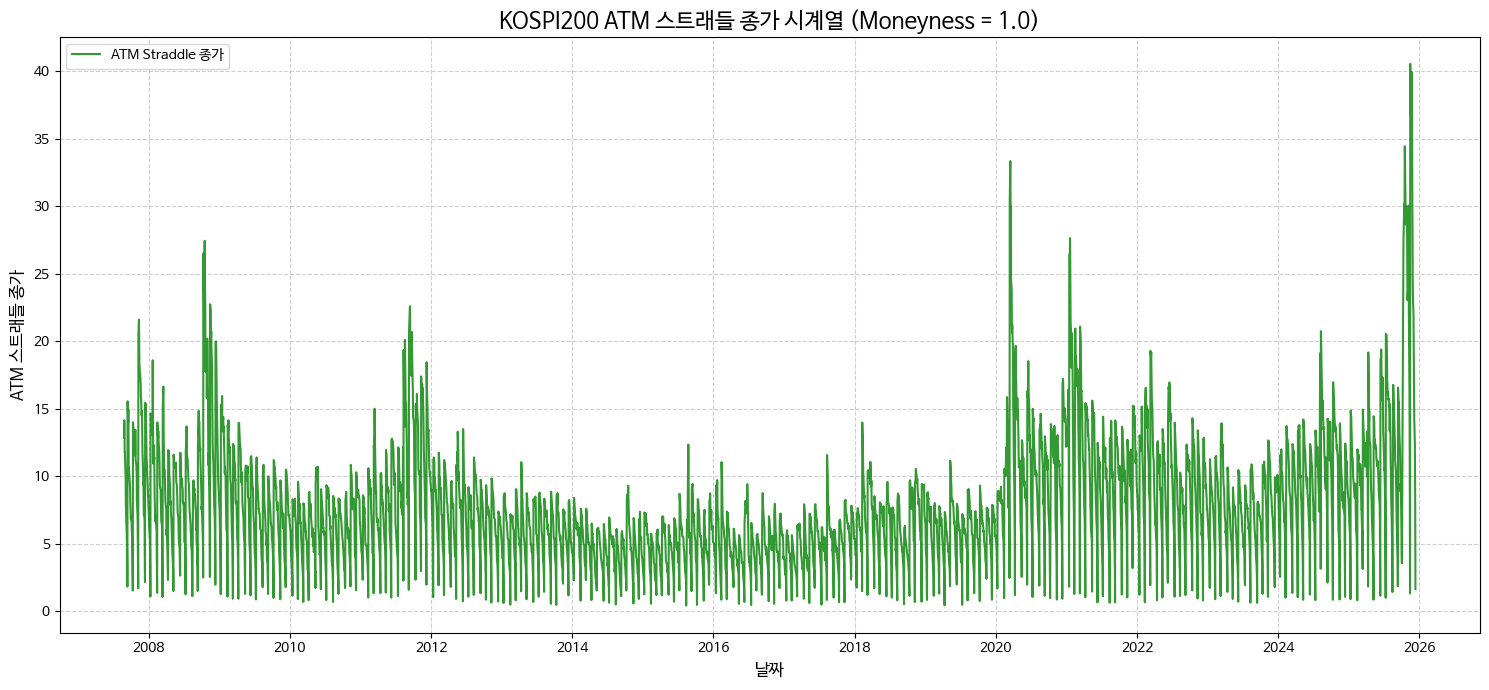

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Assuming final_ts_df is already loaded and available from previous steps
# If not, load it:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

# Calculate Straddle_t = C_ATM,t + P_ATM,t
# C_1.0_price and P_1.0_price represent ATM Call and Put prices respectively.
final_ts_df['Straddle_t'] = final_ts_df['C_1.0_price'] + final_ts_df['P_1.0_price']

# Create the plot
plt.figure(figsize=(15, 7))

sns.lineplot(data=final_ts_df, x=final_ts_df.index, y='Straddle_t', label='ATM Straddle 종가', color='green', alpha=0.8)

plt.title('KOSPI200 ATM 스트래들 종가 시계열 (Moneyness = 1.0)', fontsize=16)
plt.xlabel('날짜', fontsize=12)
plt.ylabel('ATM 스트래들 종가', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

# Save the plot to a PNG file
plot_filename = 'KOSPI200_ATM_Straddle_Price_TimeSeries.png'
plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
plt.show() # Display the plot

# Download the generated plot
files.download(plot_filename)


각 목표 moneyness에 대해 call과 put 거래량, 미결제약정 시계열

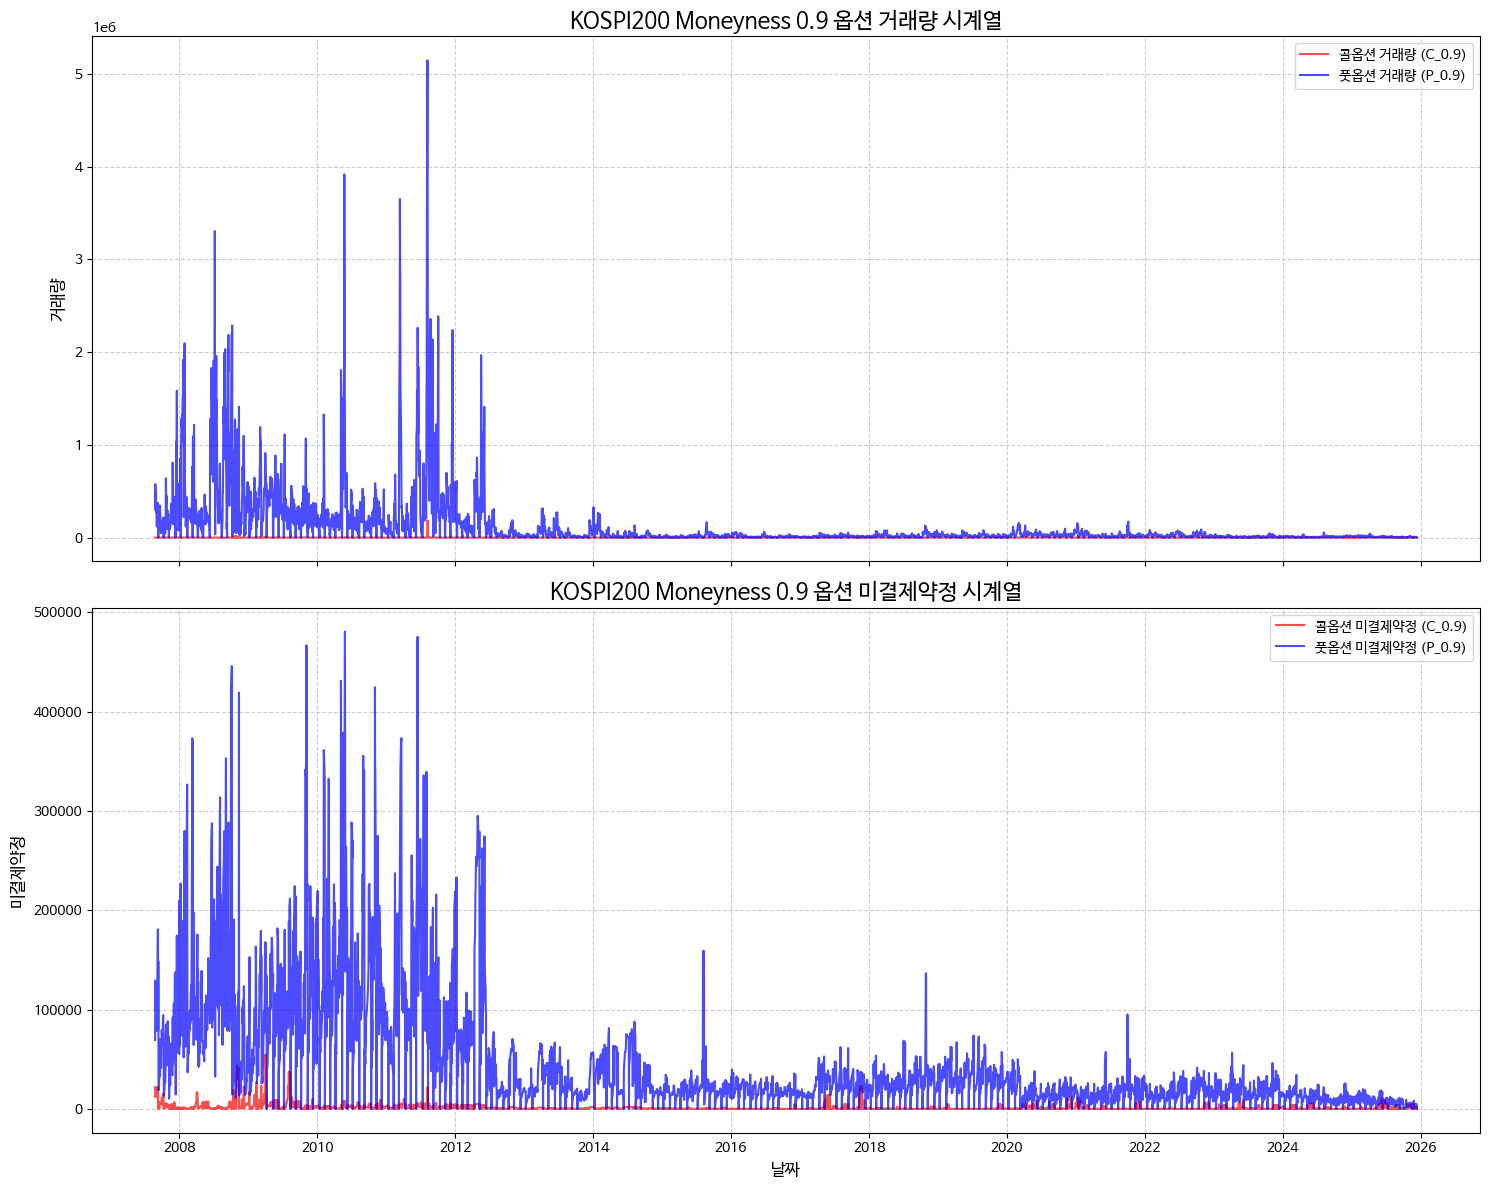

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

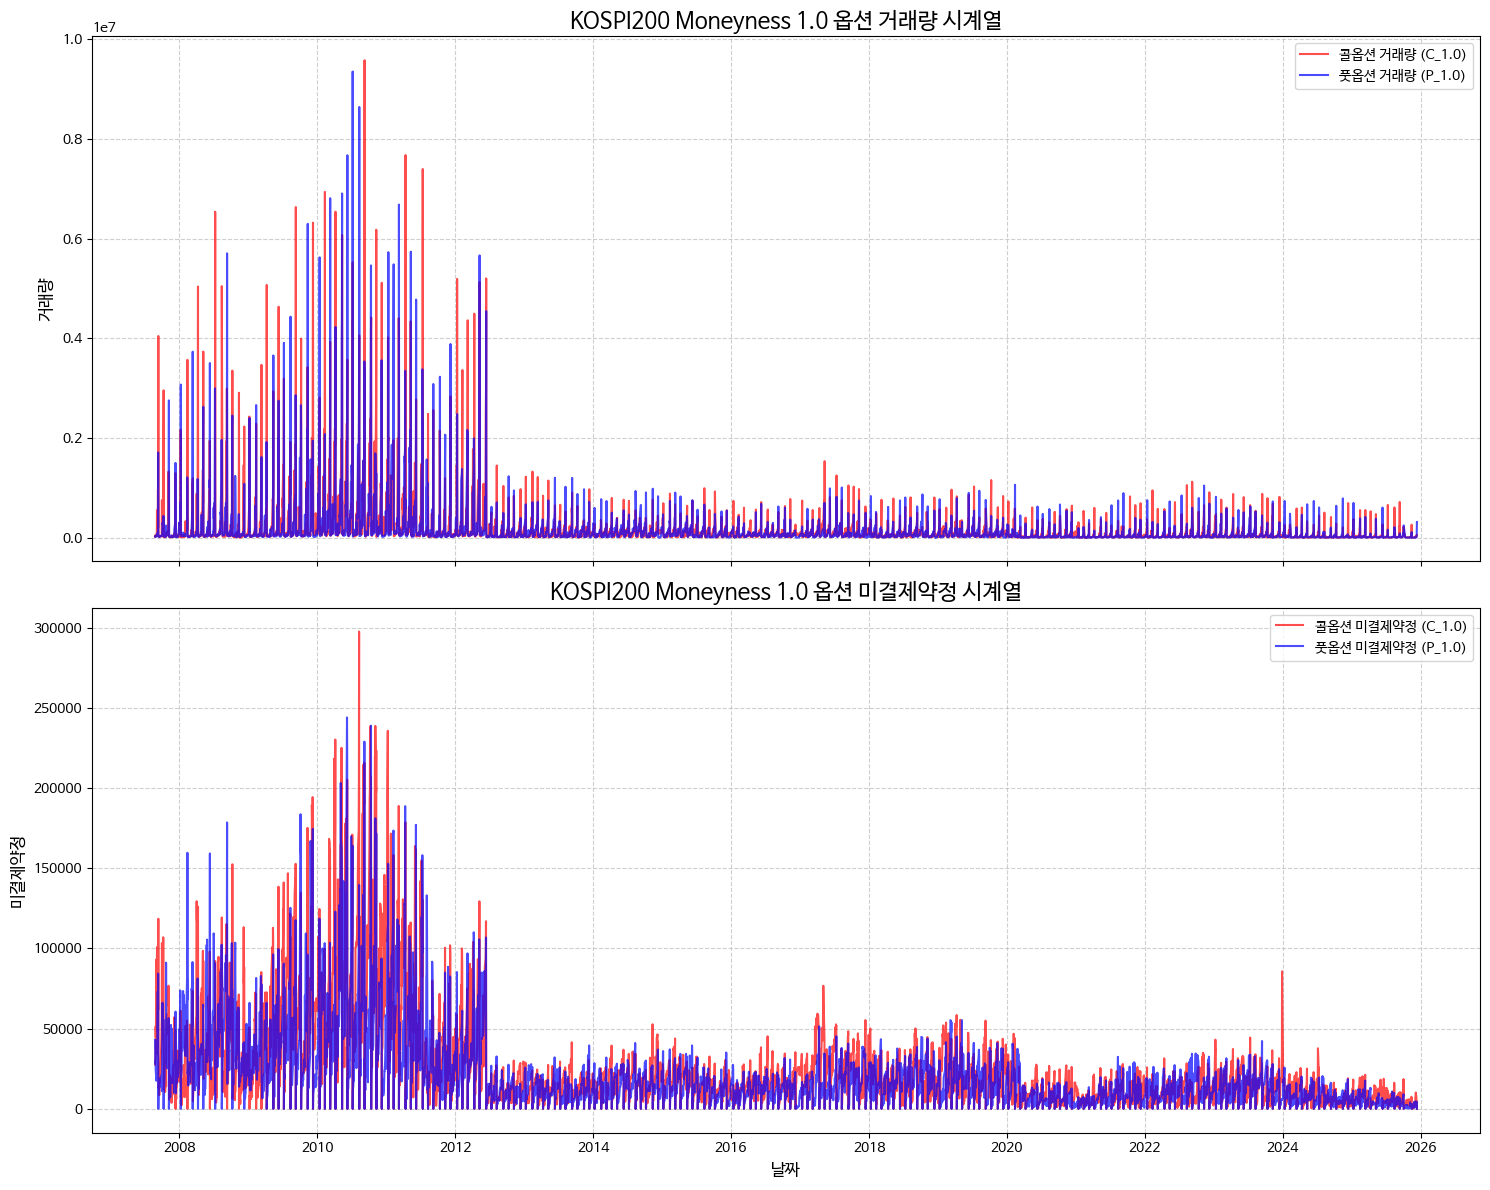

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

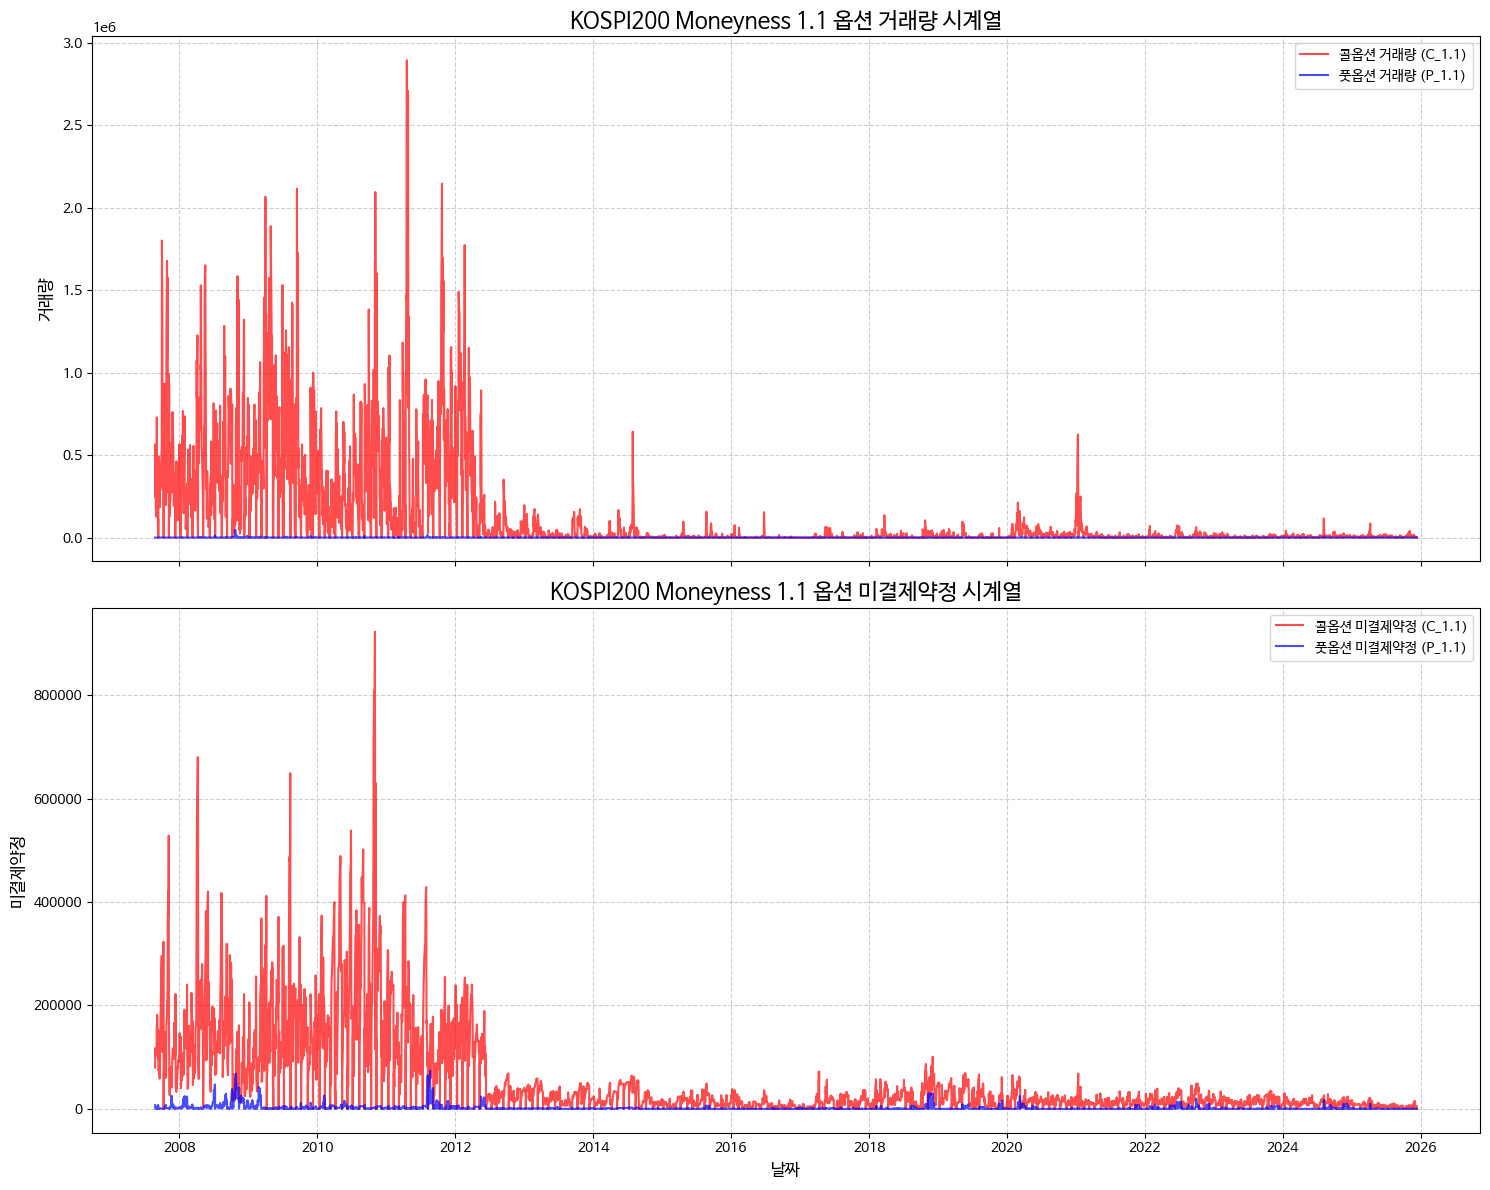

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Assuming final_ts_df is already loaded and available from previous steps
# If not, load it:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

target_moneyness_values = [0.9, 1.0, 1.1]

for tm in target_moneyness_values:
    fig, axes = plt.subplots(2, 1, figsize=(15, 12), sharex=True)

    # --- Subplot 1: Volume Time Series ---
    ax1 = axes[0]
    call_volume_col = f'C_{tm}_volume'
    put_volume_col = f'P_{tm}_volume'

    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=call_volume_col, label=f'콜옵션 거래량 (C_{tm})', ax=ax1, alpha=0.7, color='red')
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=put_volume_col, label=f'풋옵션 거래량 (P_{tm})', ax=ax1, alpha=0.7, color='blue')

    ax1.set_title(f'KOSPI200 Moneyness {tm} 옵션 거래량 시계열', fontsize=16)
    ax1.set_ylabel('거래량', fontsize=12)
    ax1.legend(fontsize=10)
    ax1.grid(True, linestyle='--', alpha=0.6)

    # --- Subplot 2: Open Interest Time Series ---
    ax2 = axes[1]
    call_oi_col = f'C_{tm}_open_interest'
    put_oi_col = f'P_{tm}_open_interest'

    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=call_oi_col, label=f'콜옵션 미결제약정 (C_{tm})', ax=ax2, alpha=0.7, color='red')
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=put_oi_col, label=f'풋옵션 미결제약정 (P_{tm})', ax=ax2, alpha=0.7, color='blue')

    ax2.set_title(f'KOSPI200 Moneyness {tm} 옵션 미결제약정 시계열', fontsize=16)
    ax2.set_xlabel('날짜', fontsize=12)
    ax2.set_ylabel('미결제약정', fontsize=12)
    ax2.legend(fontsize=10)
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # Save the plot to a PNG file
    plot_filename = f'KOSPI200_Moneyness_{tm}_Volume_Open_Interest_TimeSeries.png'
    plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
    plt.show() # Display the plot

    # Download the generated plot
    files.download(plot_filename)


각 목표 moneyness에 대해 내재변동(IV) 시계열

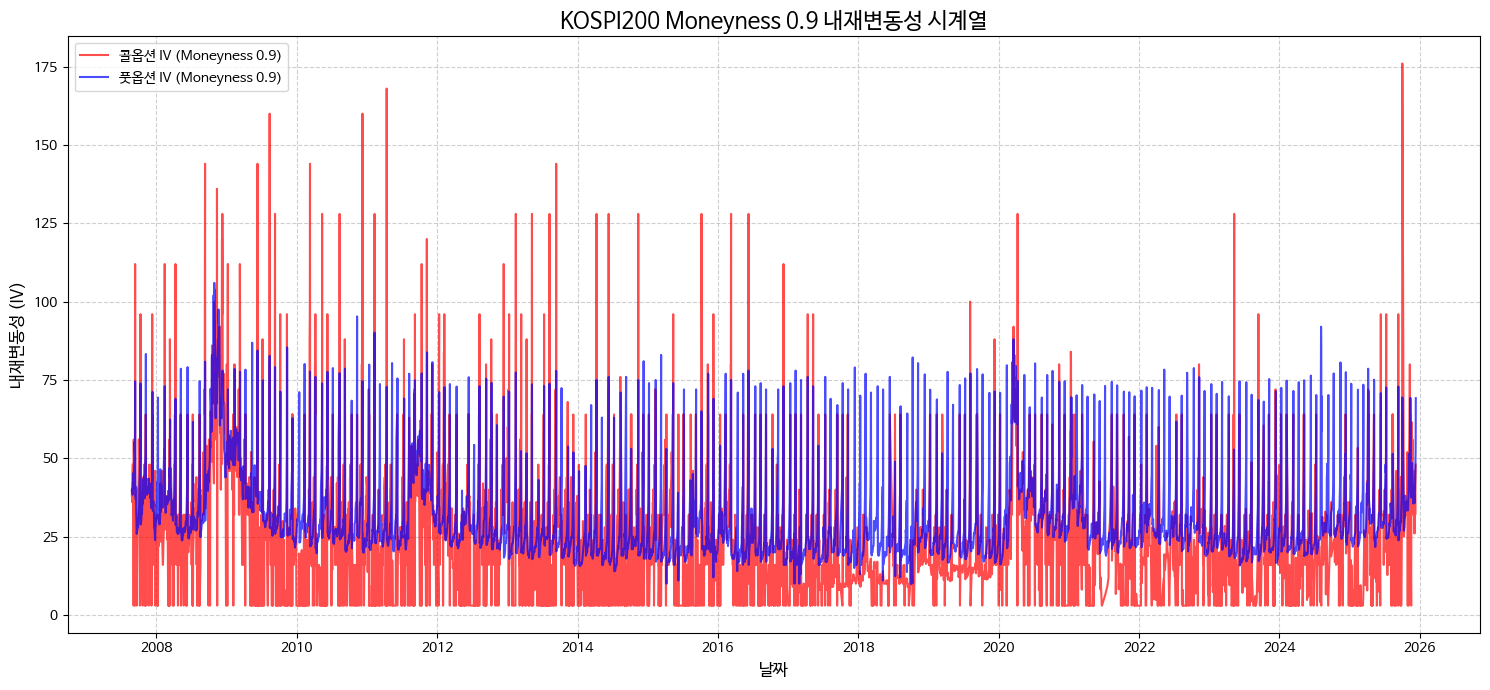

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

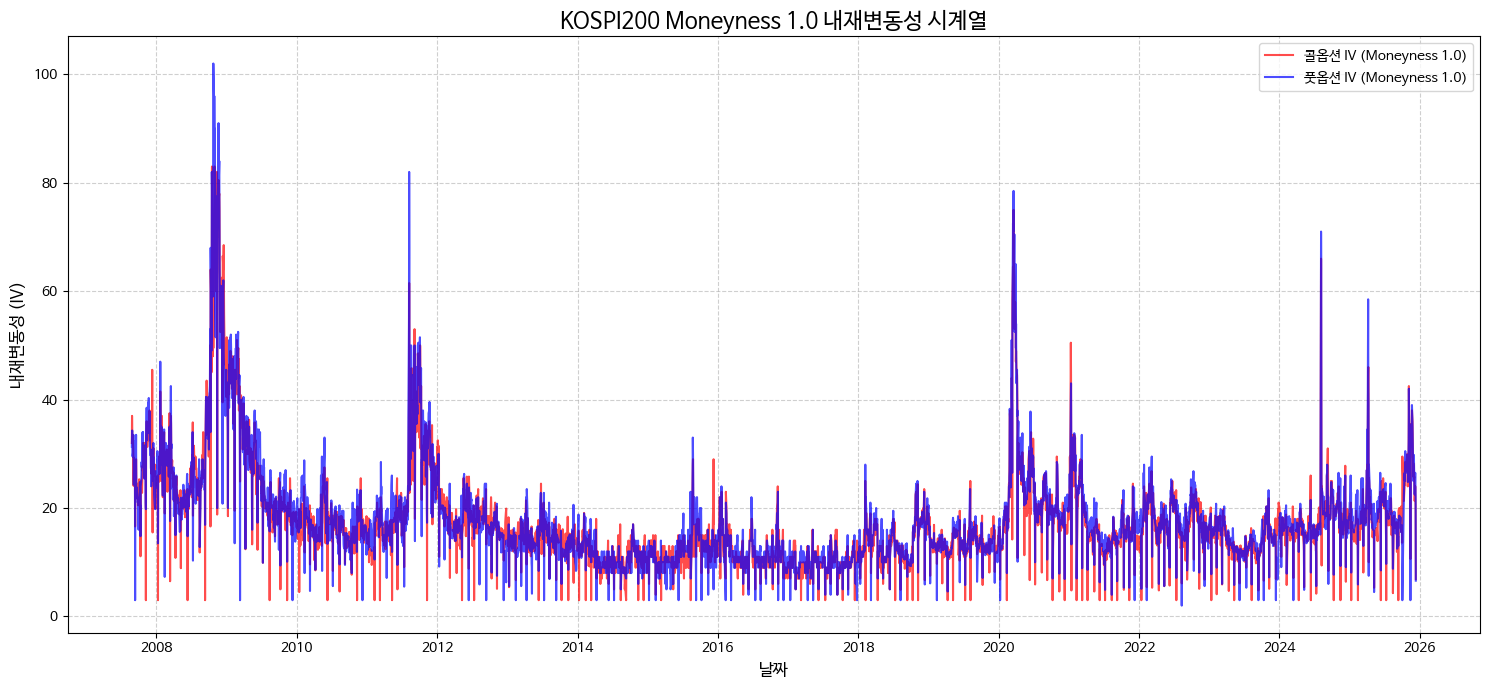

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

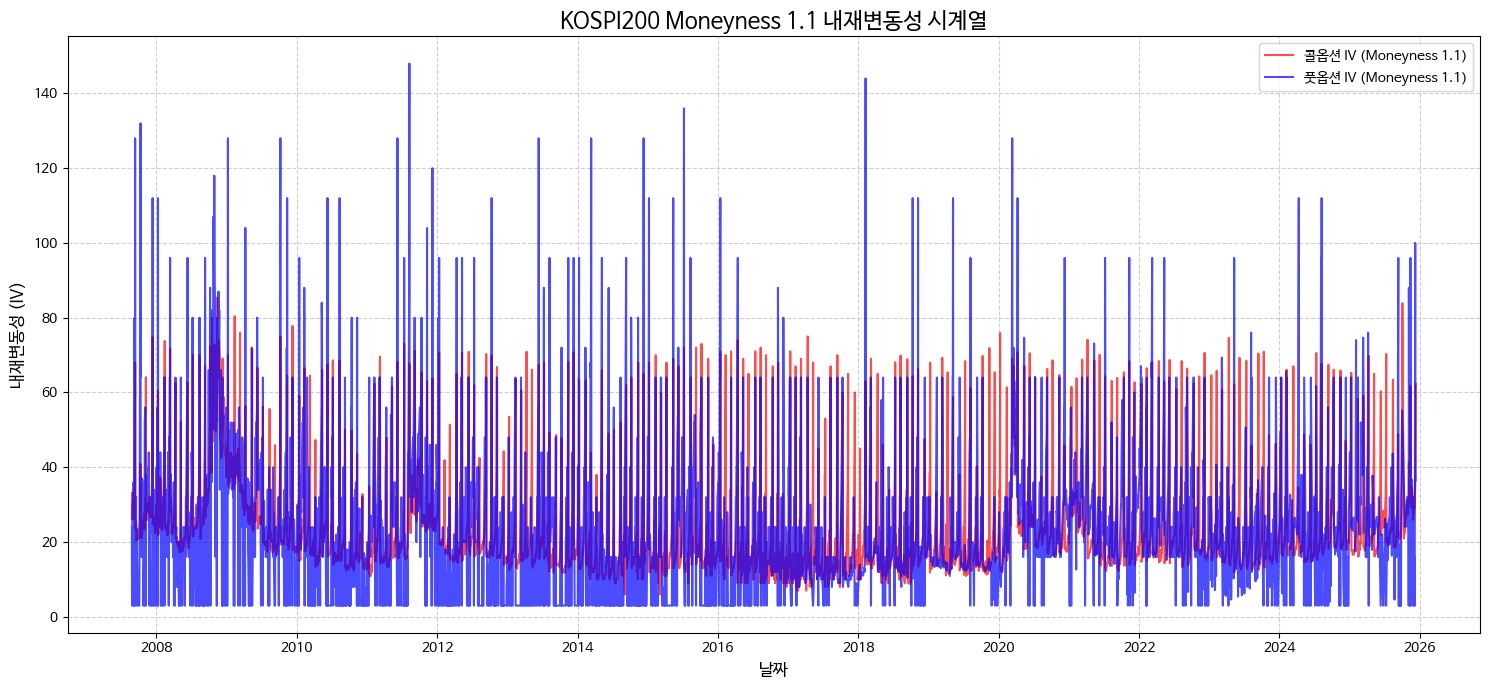

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import pandas as pd
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Assuming final_ts_df is already loaded and available from previous steps
# If not, uncomment the following line:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

target_moneyness_values = [0.9, 1.0, 1.1]

for tm in target_moneyness_values:
    plt.figure(figsize=(15, 7))

    call_iv_col = f'C_{tm}_implied_volatility'
    put_iv_col = f'P_{tm}_implied_volatility'

    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=call_iv_col, label=f'콜옵션 IV (Moneyness {tm})', color='red', alpha=0.7)
    sns.lineplot(data=final_ts_df, x=final_ts_df.index, y=put_iv_col, label=f'풋옵션 IV (Moneyness {tm})', color='blue', alpha=0.7)

    plt.title(f'KOSPI200 Moneyness {tm} 내재변동성 시계열', fontsize=16)
    plt.xlabel('날짜', fontsize=12)
    plt.ylabel('내재변동성 (IV)', fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # Save the plot to a PNG file
    plot_filename = f'KOSPI200_Moneyness_{tm}_Implied_Volatility_TimeSeries.png'
    plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
    plt.show() # Display the plot

    # Download the generated plot
    files.download(plot_filename)

# Part 5. 기초 통계량 산출

In [ ]:
import pandas as pd
import dataframe_image as dfi
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from google.colab import files

# List of columns to calculate descriptive statistics for, based on the provided image names
columns_for_stats = [
    'C_0.9_price', 'P_0.9_price',
    'C_0.9_implied_volatility', 'P_0.9_implied_volatility',
    'C_0.9_volume', 'P_0.9_volume',
    'C_0.9_open_interest', 'P_0.9_open_interest',
    'C_1.0_price', 'P_1.0_price',
    'C_1.0_implied_volatility', 'P_1.0_implied_volatility',
    'C_1.0_volume', 'P_1.0_volume',
    'C_1.0_open_interest', 'P_1.0_open_interest',
    'C_1.1_price', 'P_1.1_price',
    'C_1.1_implied_volatility', 'P_1.1_implied_volatility',
    'C_1.1_volume', 'P_1.1_volume',
    'C_1.1_open_interest', 'P_1.1_open_interest',
    'Straddle_t'
]

# Ensure all specified columns exist in final_ts_df
existing_columns_for_stats = [col for col in columns_for_stats if col in final_ts_df.columns]

if not existing_columns_for_stats:
    print("Error: None of the specified columns for statistics were found in final_ts_df.")
else:
    # Calculate descriptive statistics using .describe()
    stats_df = final_ts_df[existing_columns_for_stats].describe(percentiles=[.25, .5, .75]).T

    # Add skewness and kurtosis separately as .describe() does not include them by default
    stats_df['skewness'] = final_ts_df[existing_columns_for_stats].skew()
    stats_df['kurtosis'] = final_ts_df[existing_columns_for_stats].kurtosis()

    # Rename columns for clarity as per user request
    stats_df = stats_df.rename(columns={
        'count': 'Obs',
        'mean': '평균',
        'std': '표준편차',
        'min': '최소값',
        'max': '최대값',
        '50%': '중앙값',
        '25%': '1사분위수',
        '75%': '3사분위수'
    })

    # Reorder columns as requested (Obs, mean, std, skewness, kurtosis, min, max, median, 1사분위수, 3사분위수)
    final_stats_order = ['Obs', '평균', '표준편차', 'skewness', 'kurtosis', '최소값', '최대값', '중앙값', '1사분위수', '3사분위수']
    stats_df = stats_df[final_stats_order]

    print("--- KOSPI200 옵션 시계열 기초 통계량 ---")
    print(stats_df.to_string())

    # --- Install and configure Korean font for matplotlib to fix text issues ---
    # Update apt-get package list silently
    !sudo apt-get update -qq
    # Install Nanum fonts (a common set of Korean fonts)
    !sudo apt-get install -y fonts-nanum
    # Rebuild matplotlib's font cache
    !fc-cache -fv

    # Add the installed font to Matplotlib's font manager
    # Using NanumBarunGothic, but other Nanum fonts can be used as well.
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
    # Set the default font family for matplotlib
    plt.rcParams['font.family'] = 'NanumBarunGothic'
    # Ensure minus signs are displayed correctly with the new font
    plt.rcParams['axes.unicode_minus'] = False

    # Export the DataFrame as a PNG image
    output_png_file_name = 'KOSPI200_time_series_descriptive_statistics.png'
    dfi.export(stats_df.style.set_caption("KOSPI200 옵션 시계열 기초 통계량"), output_png_file_name, table_conversion="matplotlib", dpi=300)
    print(f"\nDescriptive statistics table (PNG) saved to {output_png_file_name}")
    files.download(output_png_file_name)

    # Optionally, save the statistics to a CSV file
    output_csv_file_name = 'KOSPI200_time_series_descriptive_statistics.csv'
    stats_df.to_csv(output_csv_file_name, encoding='utf-8-sig')
    print(f"Descriptive statistics saved to {output_csv_file_name}")
    files.download(output_csv_file_name)

--- KOSPI200 옵션 시계열 기초 통계량 ---
                             Obs             평균           표준편차   skewness     kurtosis    최소값         최대값        중앙값      1사분위수        3사분위수
C_0.9_price               3048.0      26.064058       6.734645   1.361959     4.302192   6.45       62.45     25.300     22.400      28.5000
P_0.9_price               4467.0       0.336286       0.794020   5.932672    48.216419   0.01       11.45      0.080      0.020       0.3000
C_0.9_implied_volatility  4199.0      24.520495      21.624061   1.814836     5.311103   2.99      176.00     20.000      8.205      32.0000
P_0.9_implied_volatility  4499.0      31.703292      14.482181   1.731651     2.939578   9.90      106.00     26.800     22.000      36.9000
C_0.9_volume              4199.0     154.382948    3013.990199  55.751808  3363.279383   0.00   184689.00      3.000      0.000      25.0000
P_0.9_volume              4499.0  119178.838631  309611.119261   5.898408    49.610801   0.00  5145222.00  18918.000   6588

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descriptive statistics saved to KOSPI200_time_series_descriptive_statistics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

표본분표와 추정분포 그리고 해당 정규분포

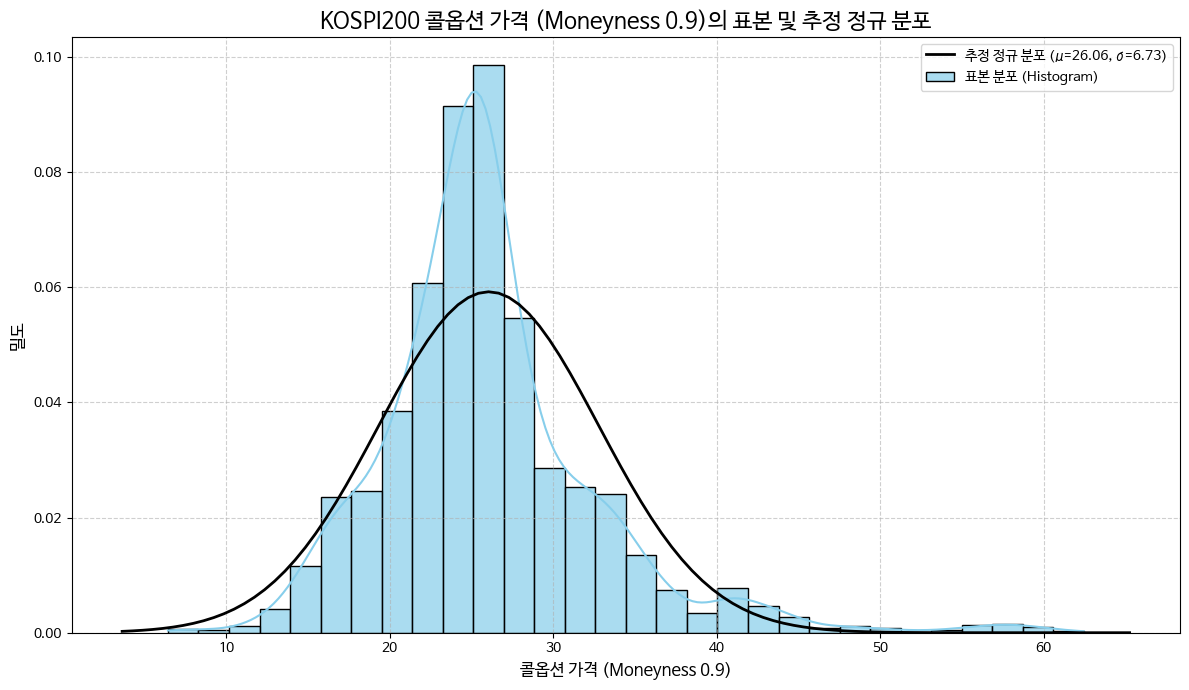

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

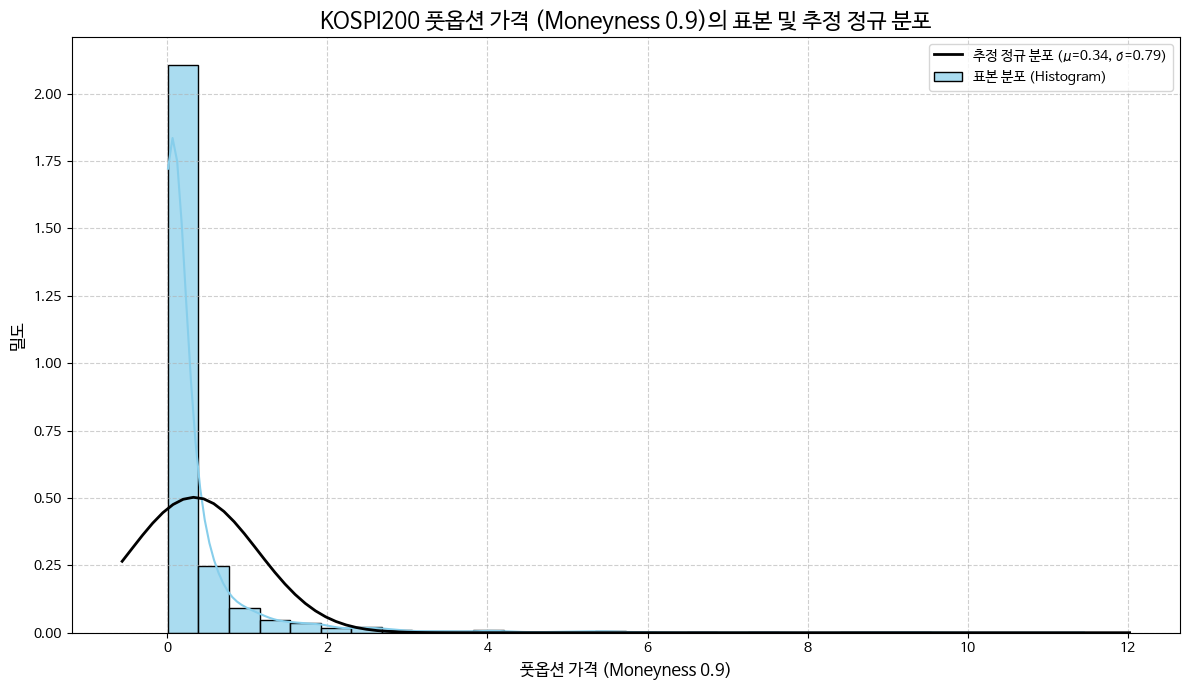

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

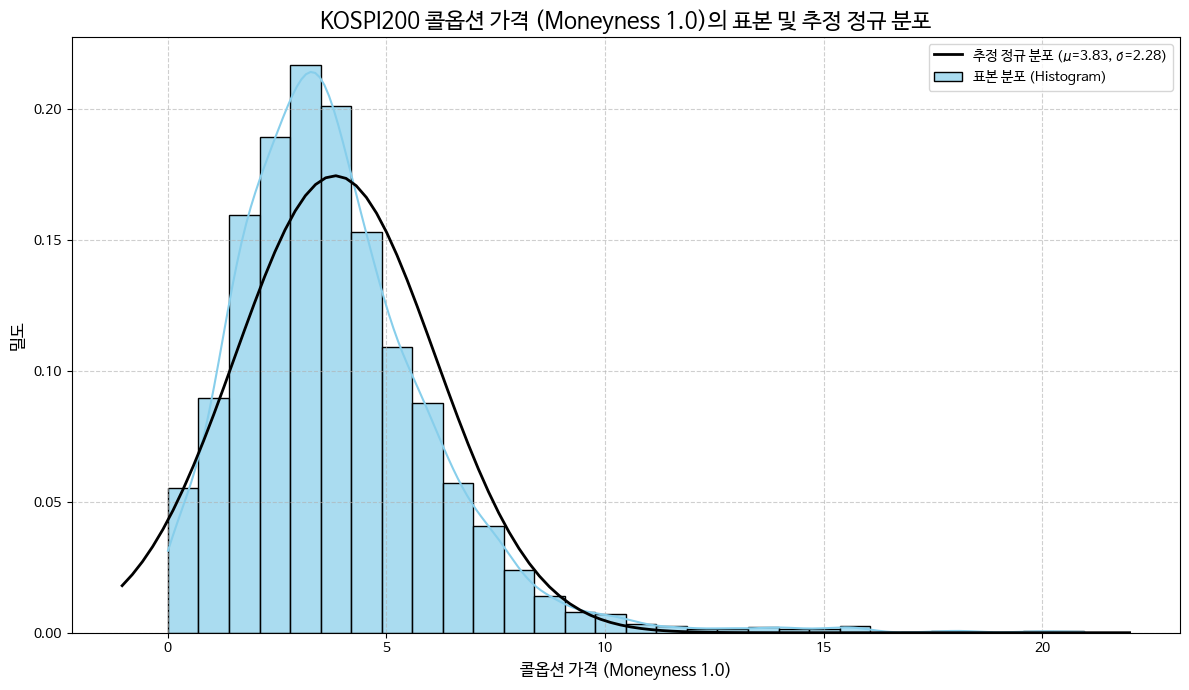

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

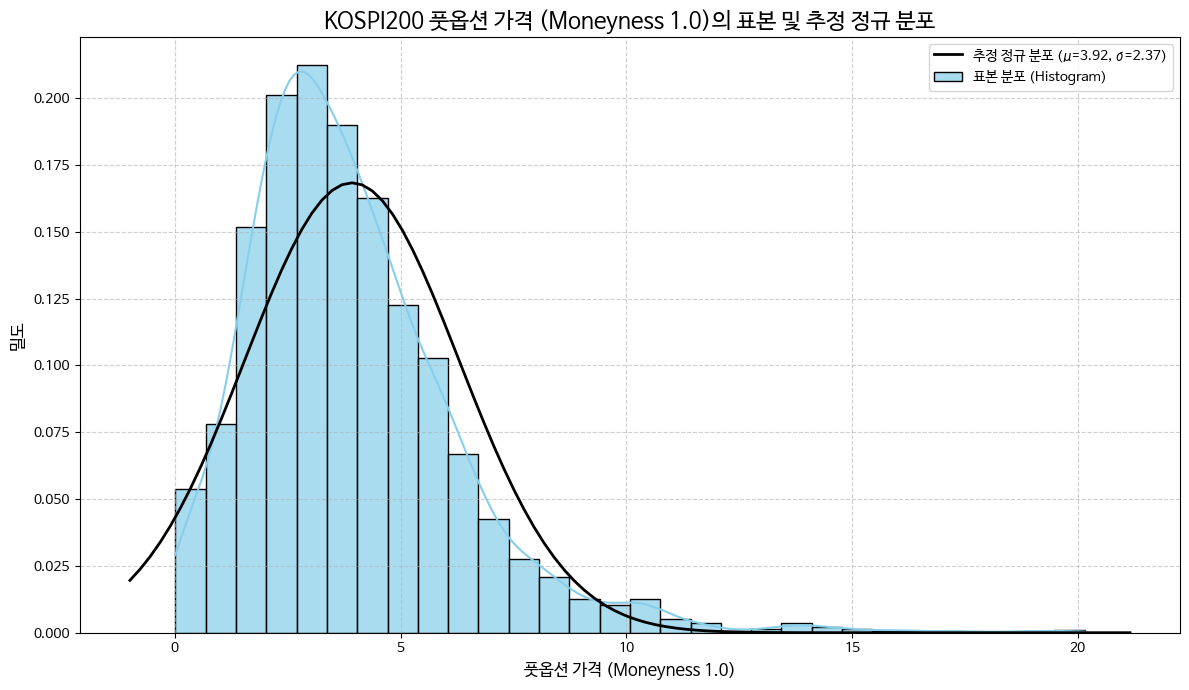

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

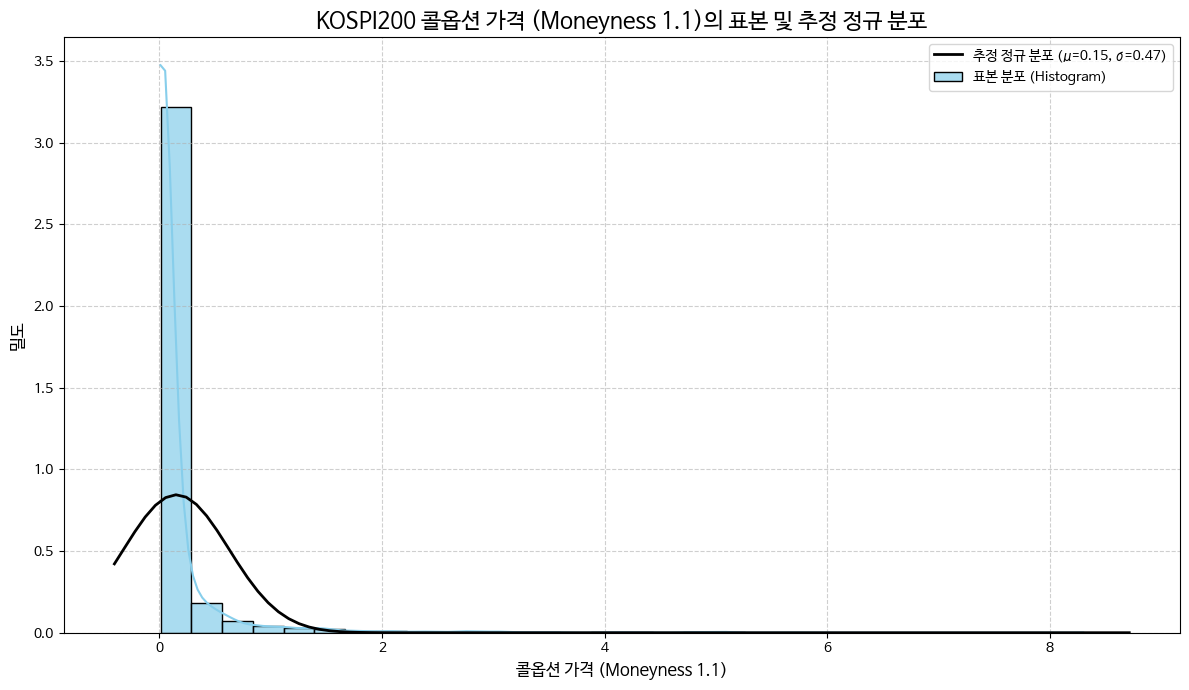

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

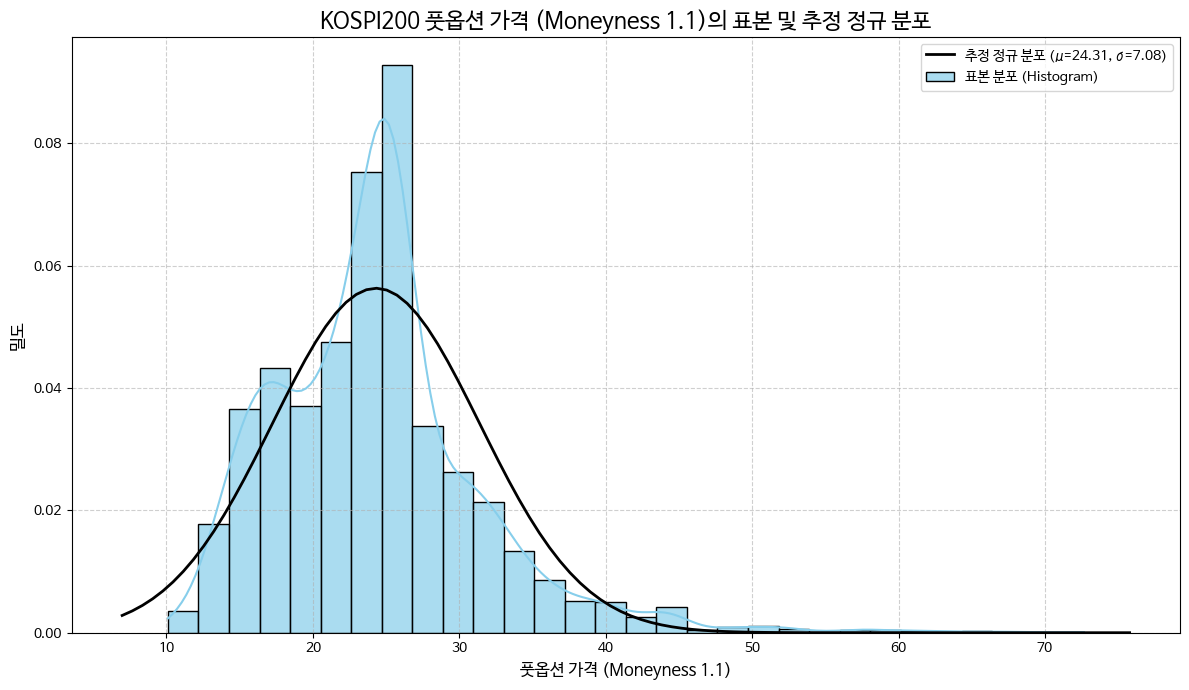

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

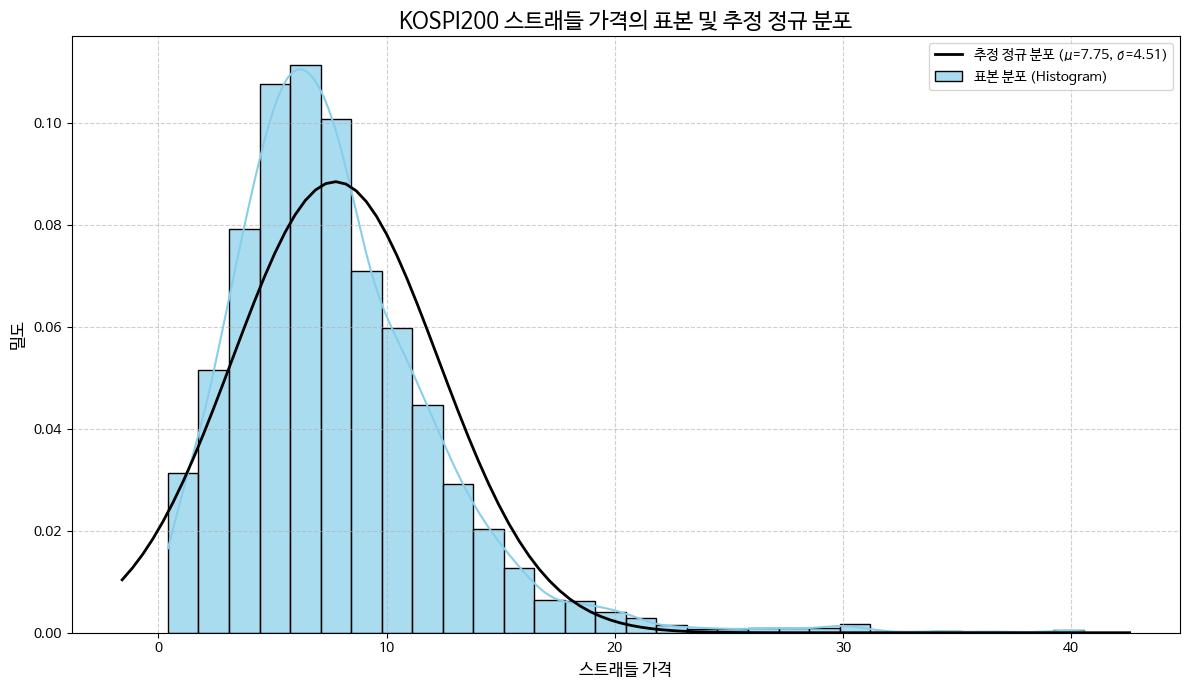

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

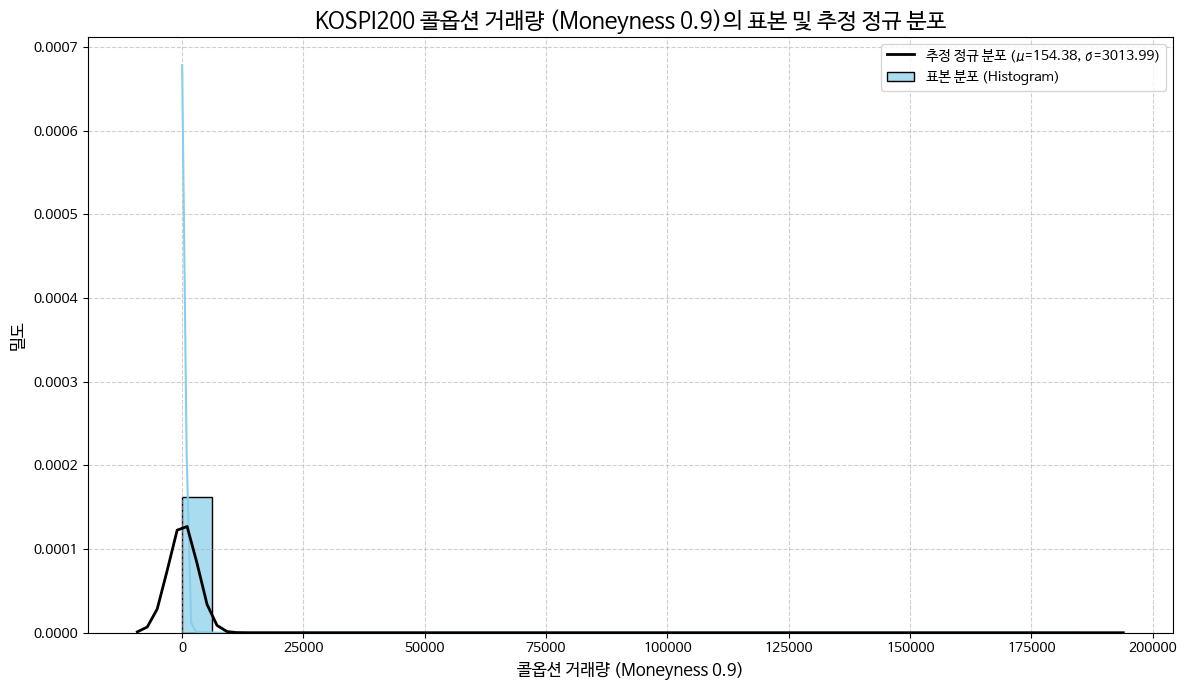

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

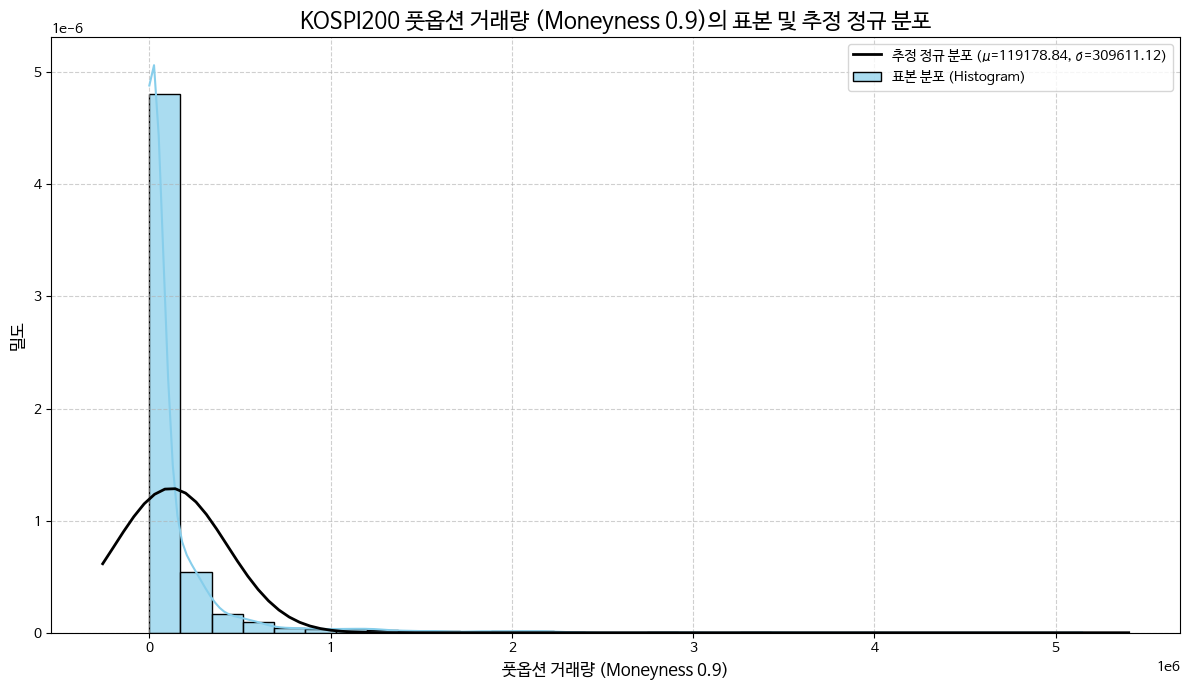

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

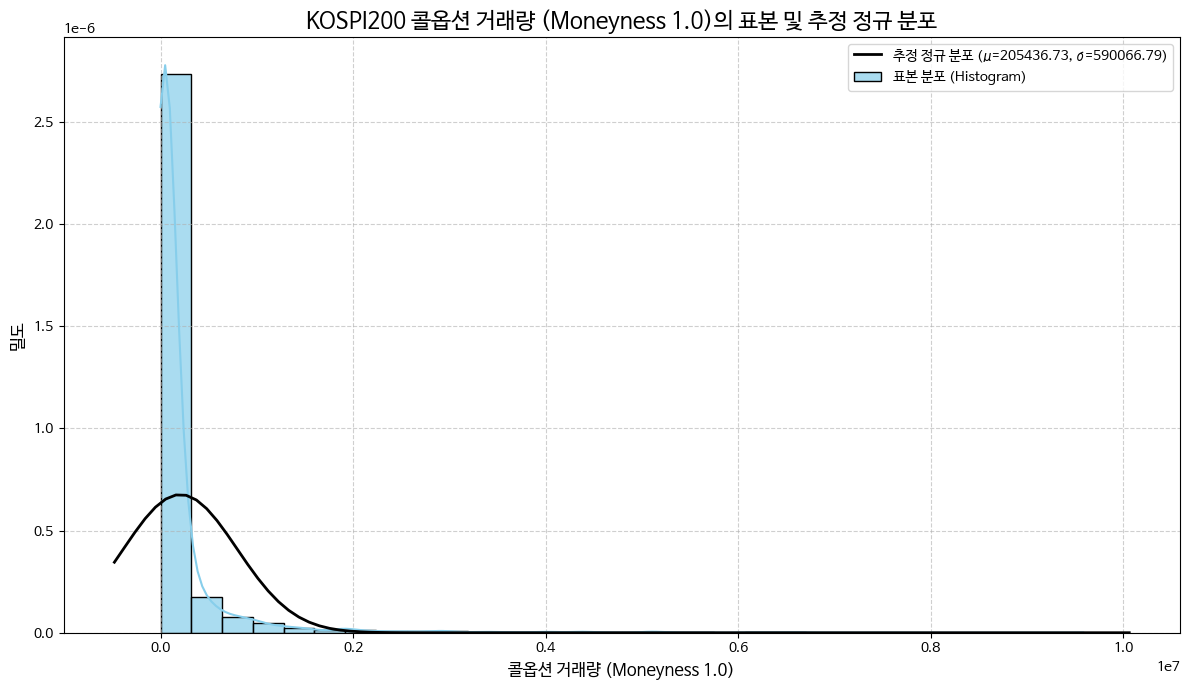

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

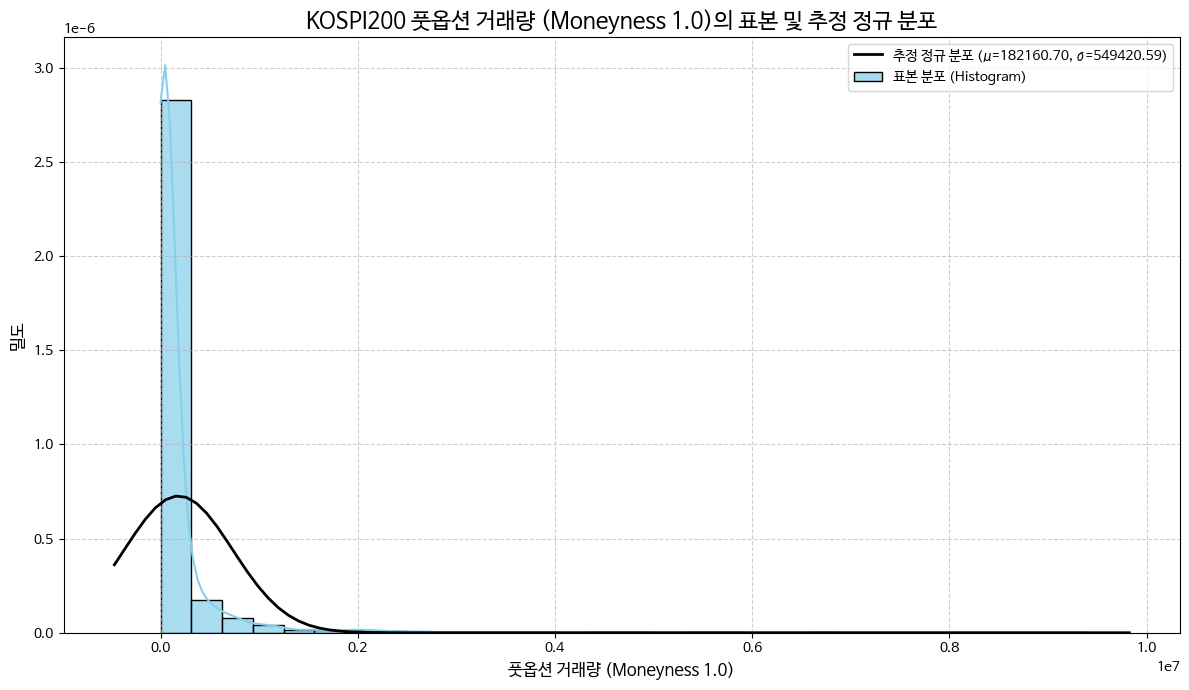

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

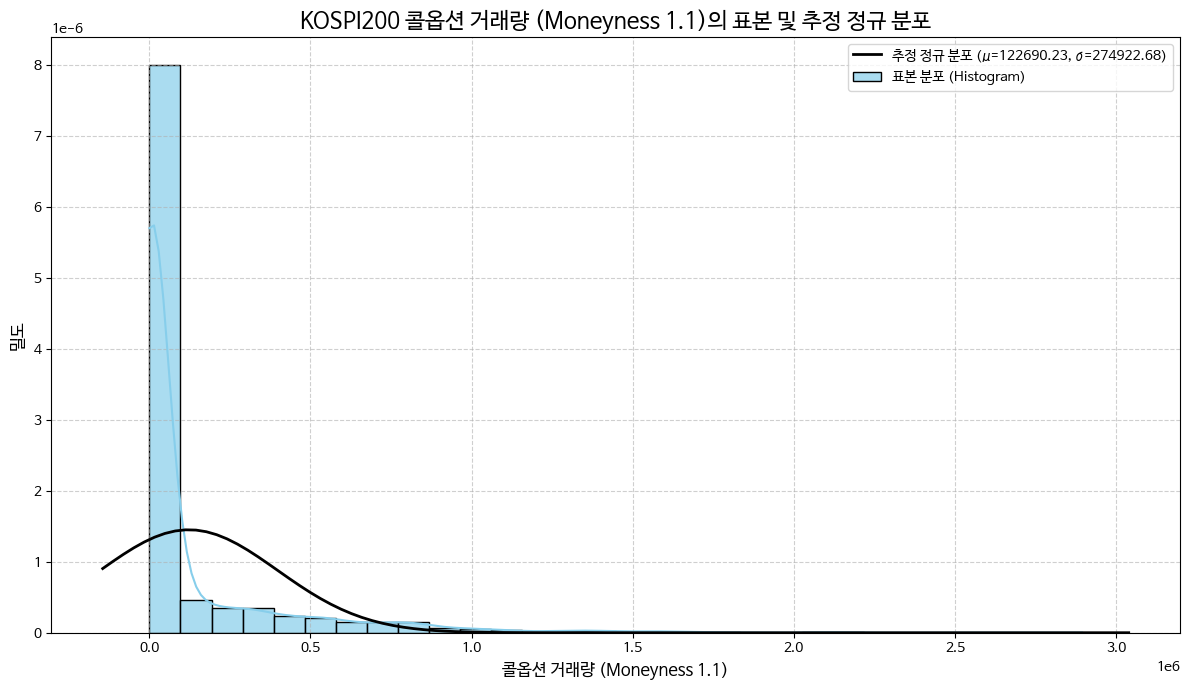

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

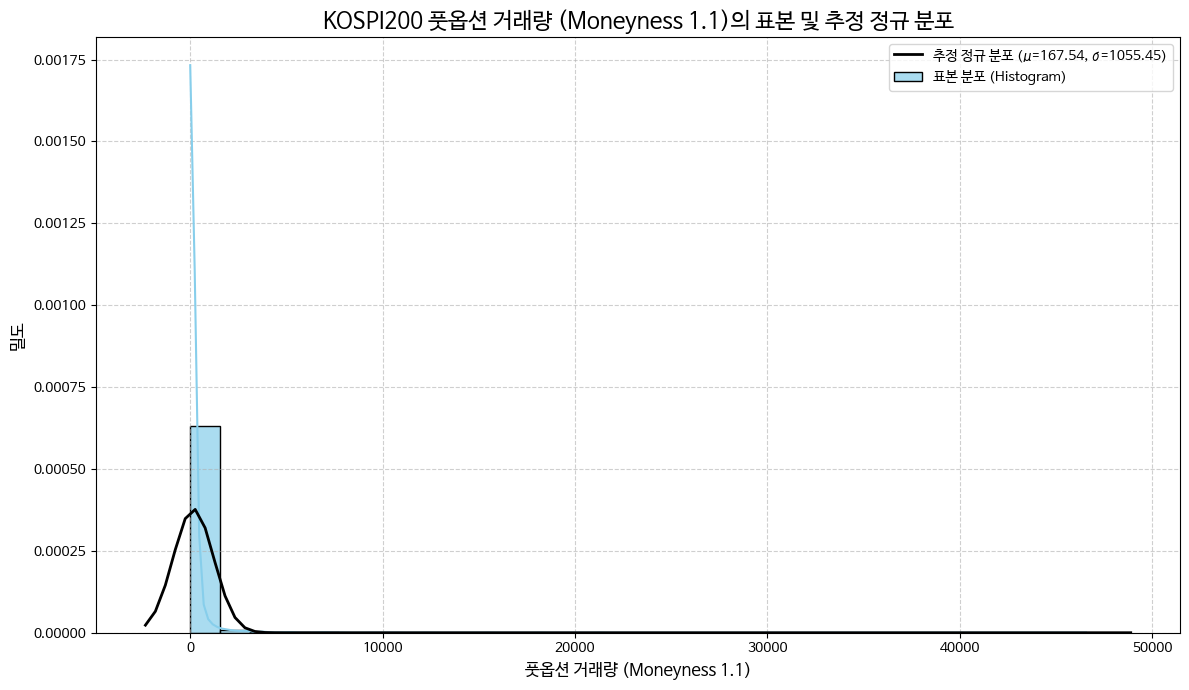

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

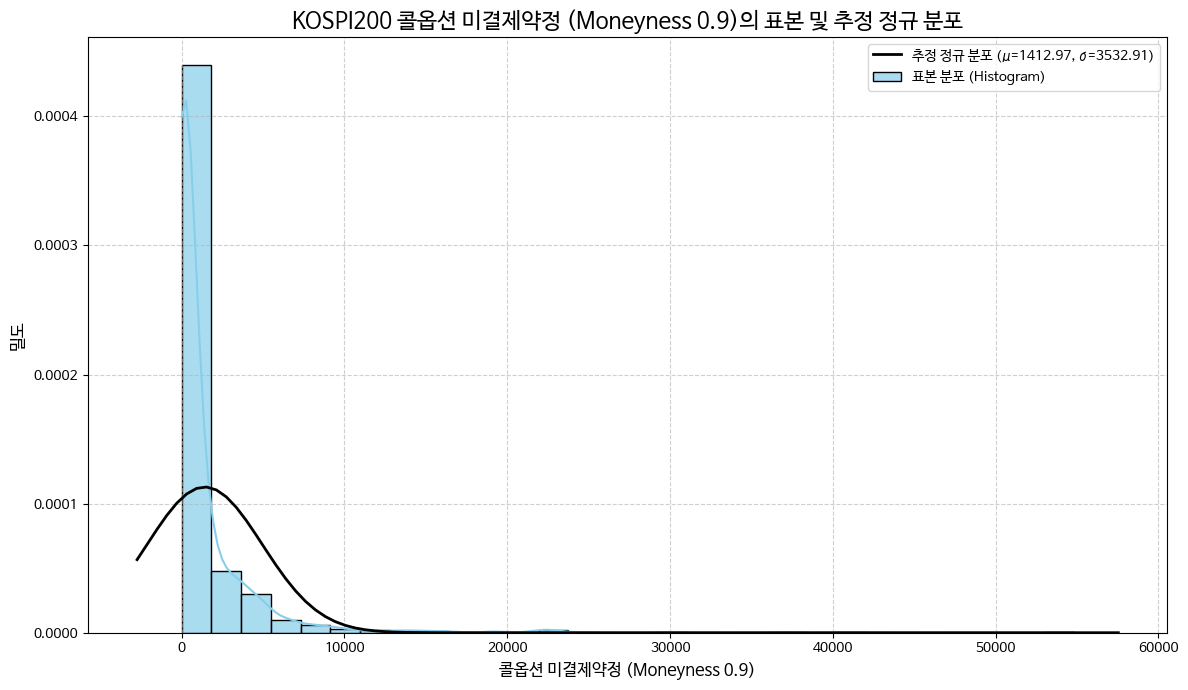

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

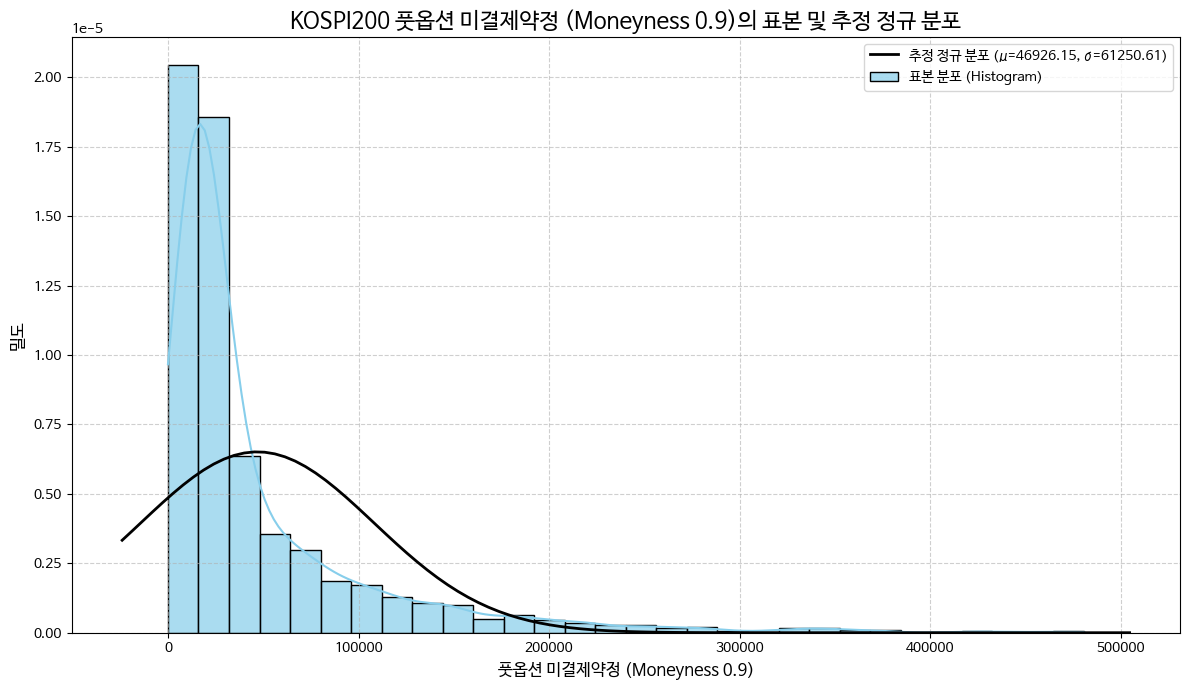

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

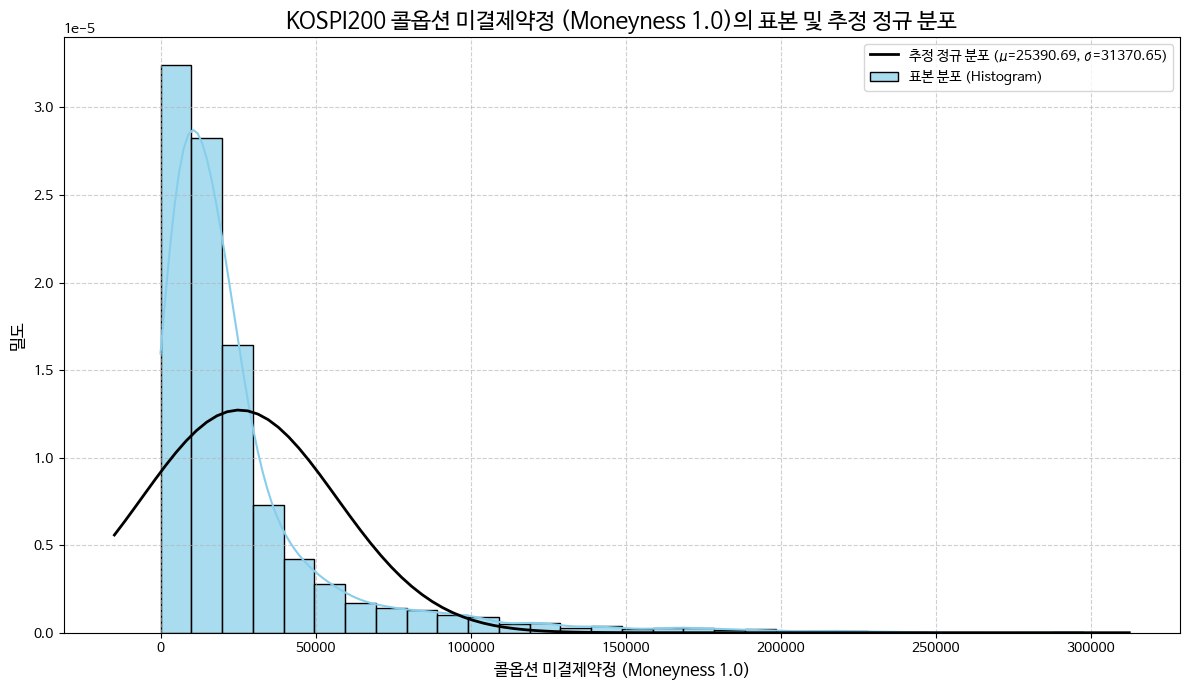

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

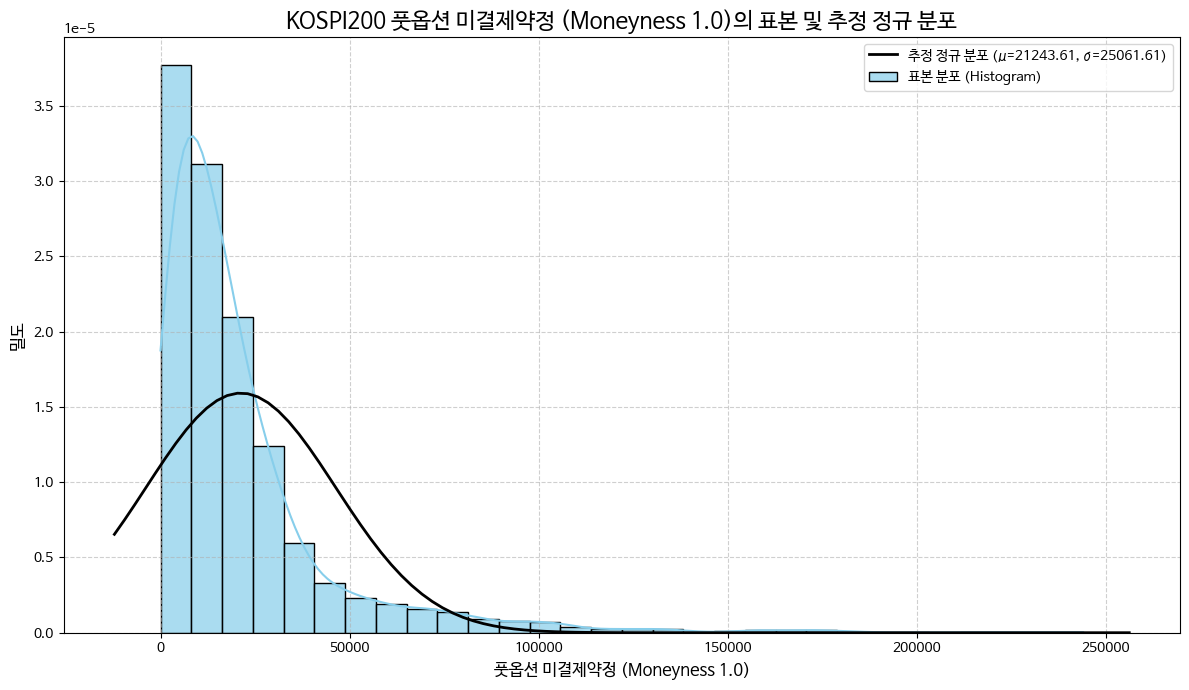

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

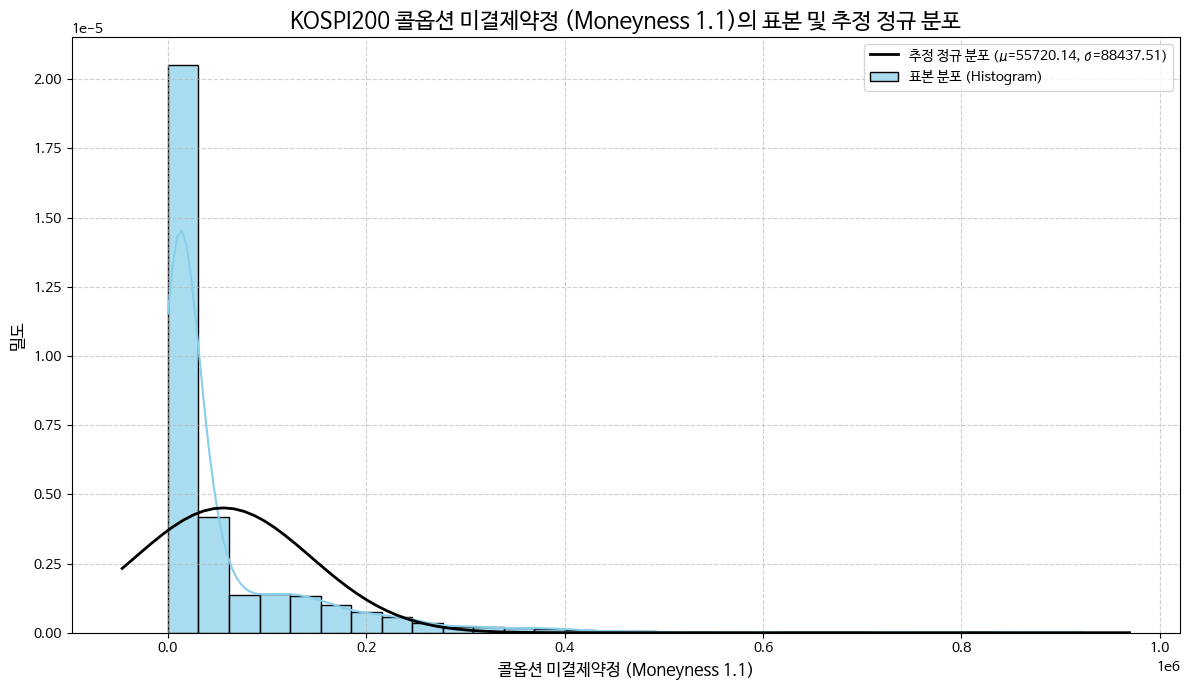

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

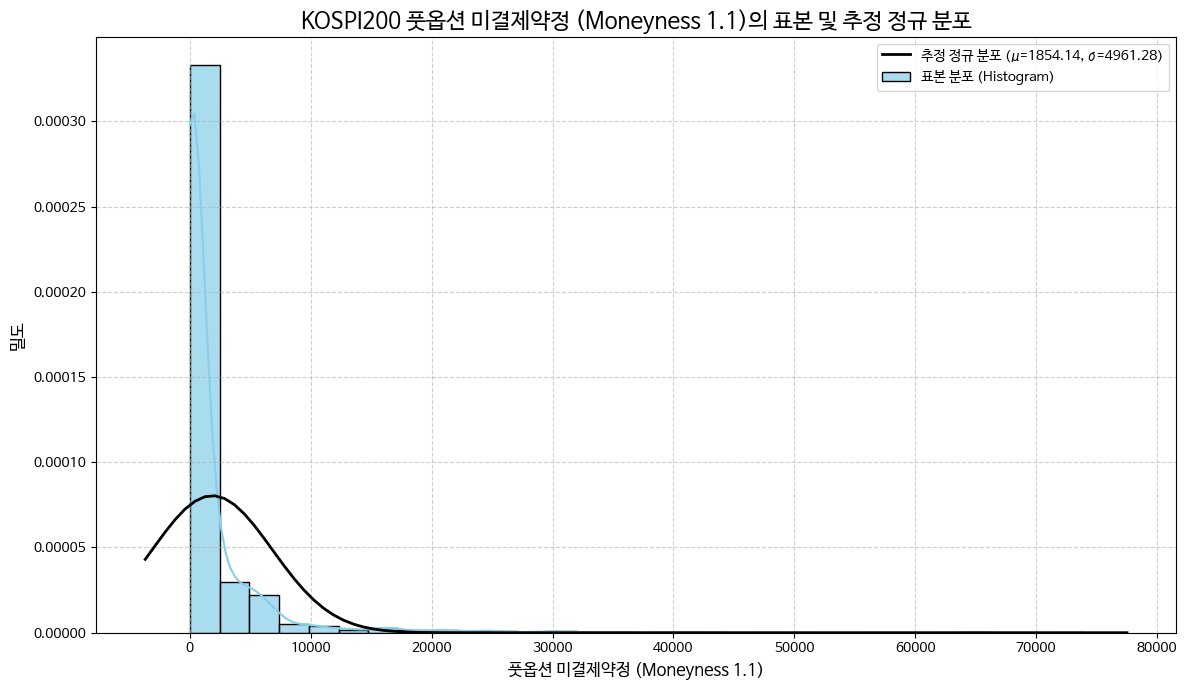

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

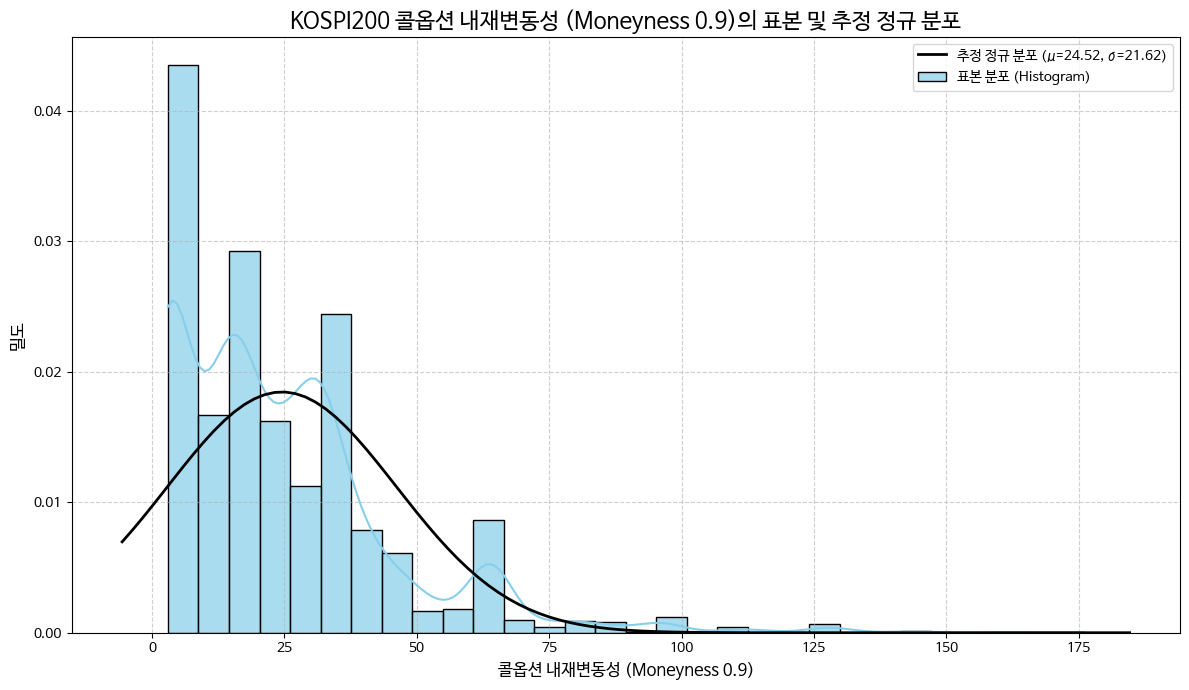

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

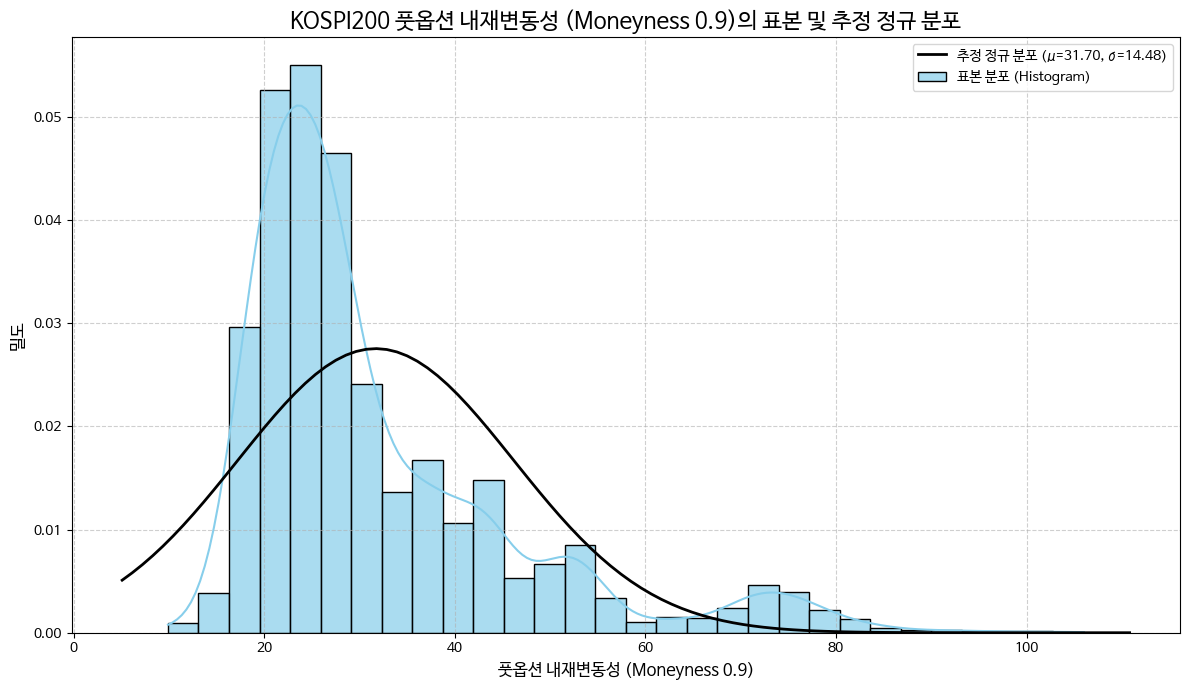

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

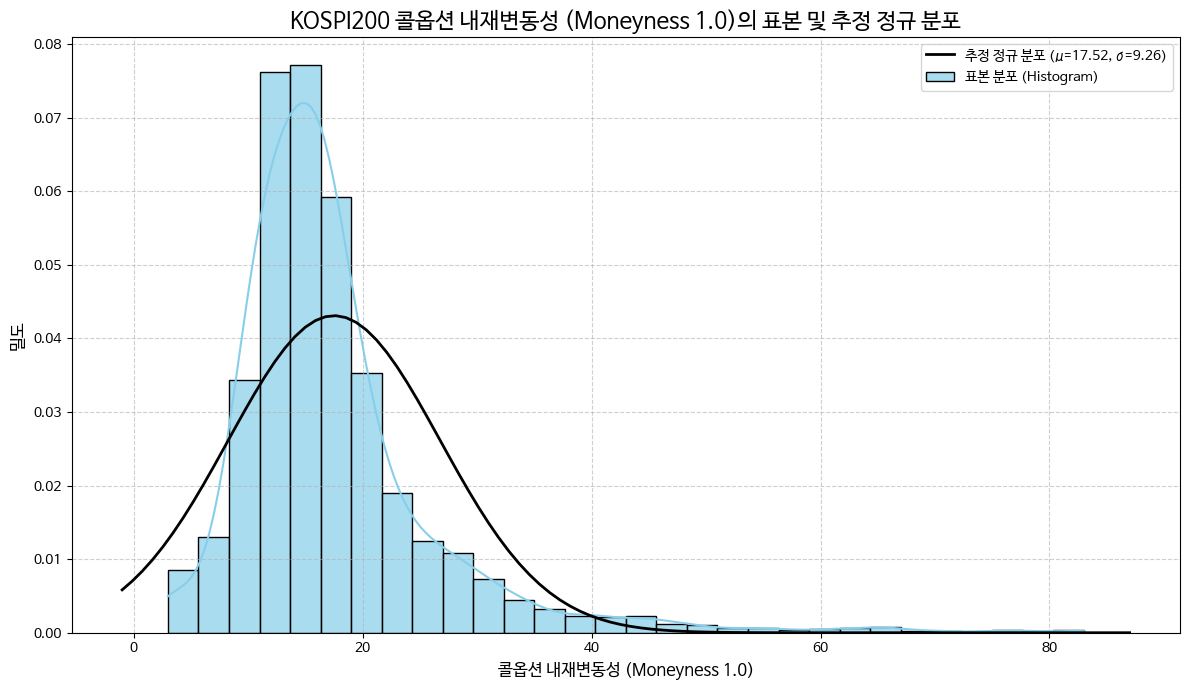

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

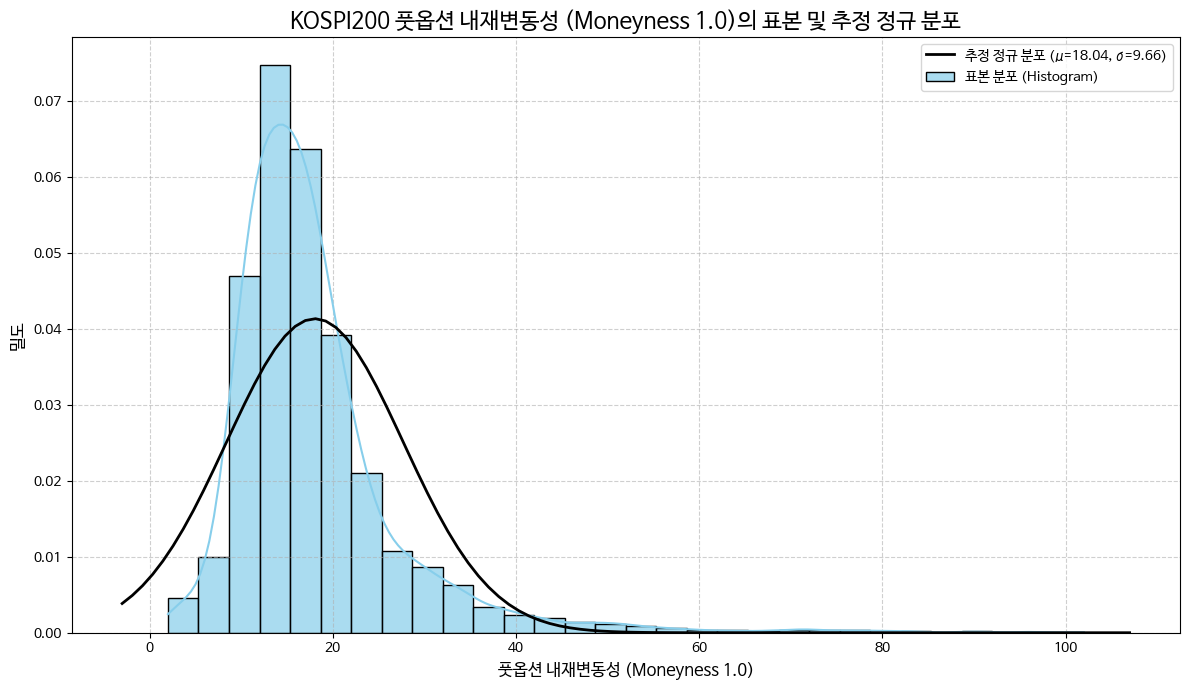

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

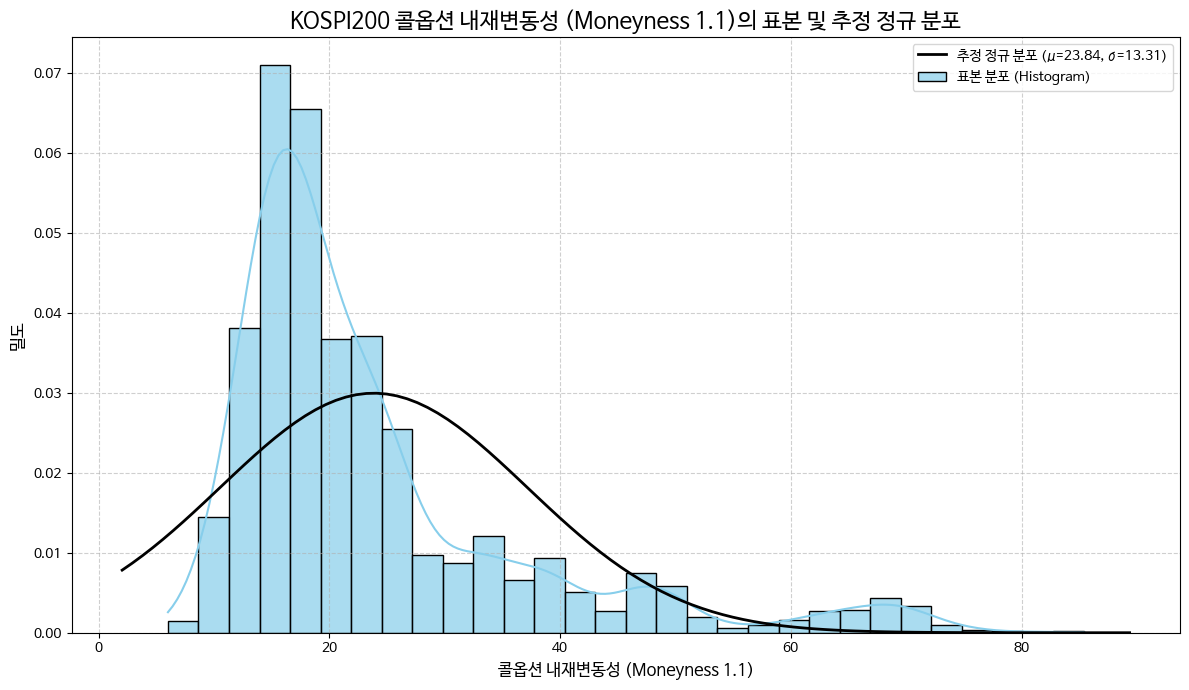

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

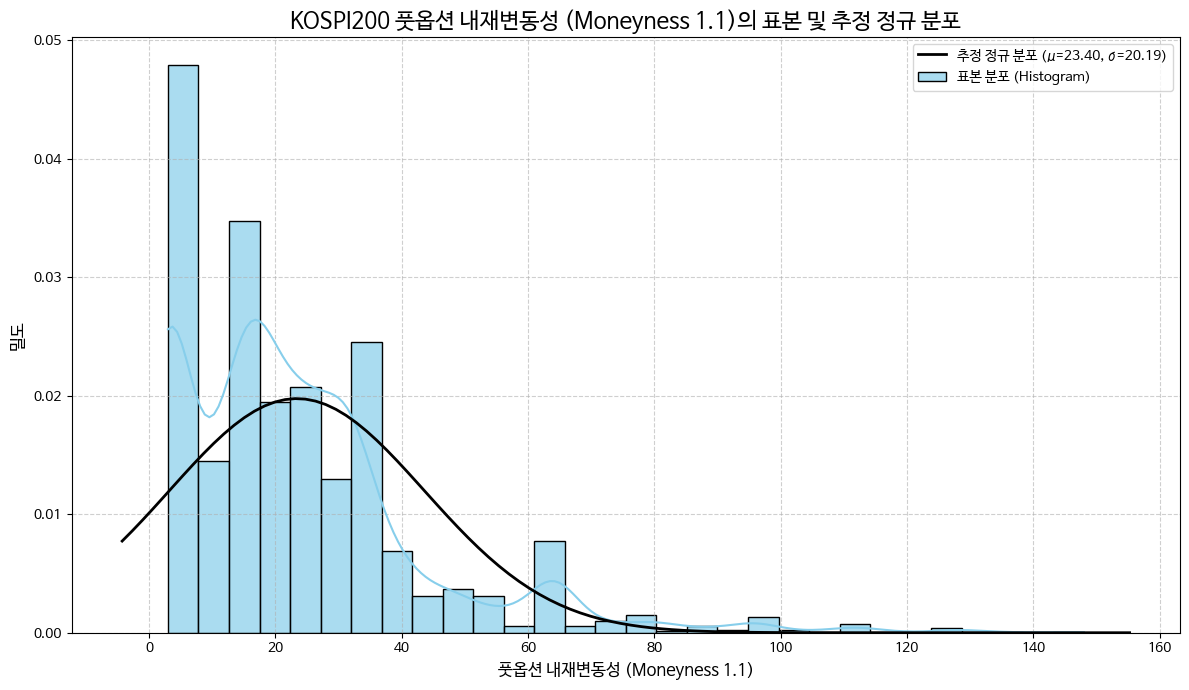

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


All distribution plots generated and downloaded.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.font_manager as fm
from google.colab import files
import pandas as pd

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Load the time series data if final_ts_df is not already in memory
# Assuming final_ts_df is already loaded from previous steps as KOSPI200_fixed_moneyness_time_series.csv
if 'final_ts_df' not in locals():
    try:
        final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)
        print("Loaded KOSPI200_fixed_moneyness_time_series.csv into final_ts_df.")
    except FileNotFoundError:
        print("Error: KOSPI200_fixed_moneyness_time_series.csv not found. Please ensure it has been created.")
        # Exit or handle error appropriately
        exit()

# Define the variables to plot and their Korean display names
plot_variables = {
    'C_0.9_price': "콜옵션 가격 (Moneyness 0.9)",
    'P_0.9_price': "풋옵션 가격 (Moneyness 0.9)",
    'C_1.0_price': "콜옵션 가격 (Moneyness 1.0)",
    'P_1.0_price': "풋옵션 가격 (Moneyness 1.0)",
    'C_1.1_price': "콜옵션 가격 (Moneyness 1.1)",
    'P_1.1_price': "풋옵션 가격 (Moneyness 1.1)",
    'Straddle_t': "스트래들 가격",

    'C_0.9_volume': "콜옵션 거래량 (Moneyness 0.9)",
    'P_0.9_volume': "풋옵션 거래량 (Moneyness 0.9)",
    'C_1.0_volume': "콜옵션 거래량 (Moneyness 1.0)",
    'P_1.0_volume': "풋옵션 거래량 (Moneyness 1.0)",
    'C_1.1_volume': "콜옵션 거래량 (Moneyness 1.1)",
    'P_1.1_volume': "풋옵션 거래량 (Moneyness 1.1)",

    'C_0.9_open_interest': "콜옵션 미결제약정 (Moneyness 0.9)",
    'P_0.9_open_interest': "풋옵션 미결제약정 (Moneyness 0.9)",
    'C_1.0_open_interest': "콜옵션 미결제약정 (Moneyness 1.0)",
    'P_1.0_open_interest': "풋옵션 미결제약정 (Moneyness 1.0)",
    'C_1.1_open_interest': "콜옵션 미결제약정 (Moneyness 1.1)",
    'P_1.1_open_interest': "풋옵션 미결제약정 (Moneyness 1.1)",

    'C_0.9_implied_volatility': "콜옵션 내재변동성 (Moneyness 0.9)",
    'P_0.9_implied_volatility': "풋옵션 내재변동성 (Moneyness 0.9)",
    'C_1.0_implied_volatility': "콜옵션 내재변동성 (Moneyness 1.0)",
    'P_1.0_implied_volatility': "풋옵션 내재변동성 (Moneyness 1.0)",
    'C_1.1_implied_volatility': "콜옵션 내재변동성 (Moneyness 1.1)",
    'P_1.1_implied_volatility': "풋옵션 내재변동성 (Moneyness 1.1)"
}

generated_plot_filenames = []

for variable_col, display_name in plot_variables.items():
    if variable_col not in final_ts_df.columns:
        print(f"Warning: Column '{variable_col}' not found in final_ts_df. Skipping plot for this variable.")
        continue

    # Drop NaN values from the selected variable for accurate distribution calculation
    data_for_distribution = final_ts_df[variable_col].dropna()

    if data_for_distribution.empty:
        print(f"Error: '{variable_col}' column is empty after dropping NaN values. Cannot plot distribution.")
        continue

    # Calculate mean and standard deviation for the normal distribution
    mu, sigma = data_for_distribution.mean(), data_for_distribution.std()

    plt.figure(figsize=(12, 7))

    # Plot histogram (sample distribution)
    sns.histplot(data_for_distribution, bins=30, kde=True, stat="density",
                 label="표본 분포 (Histogram)", color='skyblue', alpha=0.7)

    # Plot theoretical normal distribution
    xmin, xmax = plt.xlim()
    # Adjust xmin/xmax to be at least +/- 2 std dev if range is too small, or handle sigma=0
    if sigma > 0:
        if xmax - xmin < 4 * sigma:
            x_buffer = 2 * sigma
            xmin = min(xmin, mu - x_buffer)
            xmax = max(xmax, mu + x_buffer)
    else: # Handle cases where std dev is 0 (all values are the same)
        xmin = mu - 1 # Create a small range around mu
        xmax = mu + 1

    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mu, sigma)
    plt.plot(x, p, 'k', linewidth=2, label=f'추정 정규 분포 (μ={mu:.2f}, σ={sigma:.2f})')

    plt.title(f'KOSPI200 {display_name}의 표본 및 추정 정규 분포', fontsize=16)
    plt.xlabel(display_name, fontsize=12)
    plt.ylabel('밀도', fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    # Save the plot to a PNG file
    # Sanitize filename by replacing problematic characters
    safe_variable_name = variable_col.replace('.', '_').replace('/', '_')
    plot_filename = f'KOSPI200_{safe_variable_name}_Distribution.png'
    plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # Save with high resolution and tight layout
    plt.show() # Display the plot
    generated_plot_filenames.append(plot_filename)

    # Download the generated plot
    files.download(plot_filename)

print("\nAll distribution plots generated and downloaded.")

 하위기간에 대해서
분석

In [ ]:
import pandas as pd
from google.colab import files

# Assuming final_ts_df is already loaded and available from previous steps
# If not, uncomment the following line:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

# Ensure the index is datetime for filtering by year
if not isinstance(final_ts_df.index, pd.DatetimeIndex):
    final_ts_df.index = pd.to_datetime(final_ts_df.index)

# Define the sub-periods as requested
sub_periods = [
    {'name': '1997-2002', 'start_year': 1997, 'end_year': 2002},
    {'name': '2003-2008', 'start_year': 2003, 'end_year': 2008},
    {'name': '2009-2015', 'start_year': 2009, 'end_year': 2015},
    {'name': '2016-2025', 'start_year': 2016, 'end_year': 2025}
]

# List of columns to calculate descriptive statistics for
# Reusing the list from the previous statistics cell
columns_for_stats = [
    'C_0.9_price', 'P_0.9_price',
    'C_0.9_implied_volatility', 'P_0.9_implied_volatility',
    'C_0.9_volume', 'P_0.9_volume',
    'C_0.9_open_interest', 'P_0.9_open_interest',
    'C_1.0_price', 'P_1.0_price',
    'C_1.0_implied_volatility', 'P_1.0_implied_volatility',
    'C_1.0_volume', 'P_1.0_volume',
    'C_1.0_open_interest', 'P_1.0_open_interest',
    'C_1.1_price', 'P_1.1_price',
    'C_1.1_implied_volatility', 'P_1.1_implied_volatility',
    'C_1.1_volume', 'P_1.1_volume',
    'C_1.1_open_interest', 'P_1.1_open_interest',
    'Straddle_t'
]

# Filter for existing columns to avoid errors if some were not generated
existing_columns_for_stats = [col for col in columns_for_stats if col in final_ts_df.columns]

# Iterate through each sub-period and calculate statistics
sub_period_stats_files = []
for period in sub_periods:
    start_date = f"{period['start_year']}-01-01"
    end_date = f"{period['end_year']}-12-31"

    # Filter data for the current period
    period_df = final_ts_df.loc[start_date:end_date]

    print(f"\n--- 분석 기간: {period['name']} ({start_date} ~ {end_date}) ---")

    if period_df.empty:
        print(f"경고: {period['name']} 기간에 해당하는 데이터가 없습니다. (데이터 시작일: {final_ts_df.index.min().strftime('%Y-%m-%d')})\n")
        continue

    # Calculate descriptive statistics
    stats_df_period = period_df[existing_columns_for_stats].describe(percentiles=[.25, .5, .75]).T

    # Add skewness and kurtosis
    stats_df_period['skewness'] = period_df[existing_columns_for_stats].skew()
    stats_df_period['kurtosis'] = period_df[existing_columns_for_stats].kurtosis()

    # Rename columns for clarity
    stats_df_period = stats_df_period.rename(columns={
        'count': 'Obs',
        'mean': '평균',
        'std': '표준편차',
        'min': '최소값',
        'max': '최대값',
        '50%': '중앙값',
        '25%': '1사분위수',
        '75%': '3사분위수'
    })

    # Reorder columns as requested
    final_stats_order = ['Obs', '평균', '표준편차', 'skewness', 'kurtosis', '최소값', '최대값', '중앙값', '1사분위수', '3사분위수']
    stats_df_period = stats_df_period[final_stats_order]

    print(stats_df_period.to_string())

    # Save statistics to a CSV file
    output_stats_file_name = f"KOSPI200_time_series_descriptive_statistics_{period['name']}.csv"
    stats_df_period.to_csv(output_stats_file_name, encoding='utf-8-sig')
    sub_period_stats_files.append(output_stats_file_name)
    print(f"\n기술 통계량이 {output_stats_file_name} 파일로 저장되었습니다.")

print("\n--- 모든 기간에 대한 기술 통계량 분석 완료 ---")
print("생성된 통계 파일:")
for filename in sub_period_stats_files:
    print(f"- {filename}")
    files.download(filename)



--- 분석 기간: 1997-2002 (1997-01-01 ~ 2002-12-31) ---
경고: 1997-2002 기간에 해당하는 데이터가 없습니다. (데이터 시작일: 2007-08-27)


--- 분석 기간: 2003-2008 (2003-01-01 ~ 2008-12-31) ---
                            Obs             평균           표준편차   skewness    kurtosis       최소값         최대값         중앙값        1사분위수        3사분위수
C_0.9_price               305.0      20.592131       4.179078  -0.473123   -0.089830      6.45       29.80      21.100      17.7000      23.7000
P_0.9_price               332.0       1.076416       1.697118   2.829075    9.382577      0.01       11.45       0.480       0.1000       1.1650
C_0.9_implied_volatility  332.0      39.026807      25.999717   1.085184    1.605314      3.00      144.00      34.000      24.0000      48.0000
P_0.9_implied_volatility  332.0      43.574096      17.769905   1.333173    1.096382     23.80      106.00      38.250      30.1750      50.9250
C_0.9_volume              332.0     504.015060    1809.263063   6.993359   53.210741      0.00    17779.00      85

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

- KOSPI200_time_series_descriptive_statistics_2009-2015.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

- KOSPI200_time_series_descriptive_statistics_2016-2025.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Part 6: 추가 분석


Put-Call parity deviation

Calculating Put-Call Parity Deviation...
PCP Deviation calculation complete.


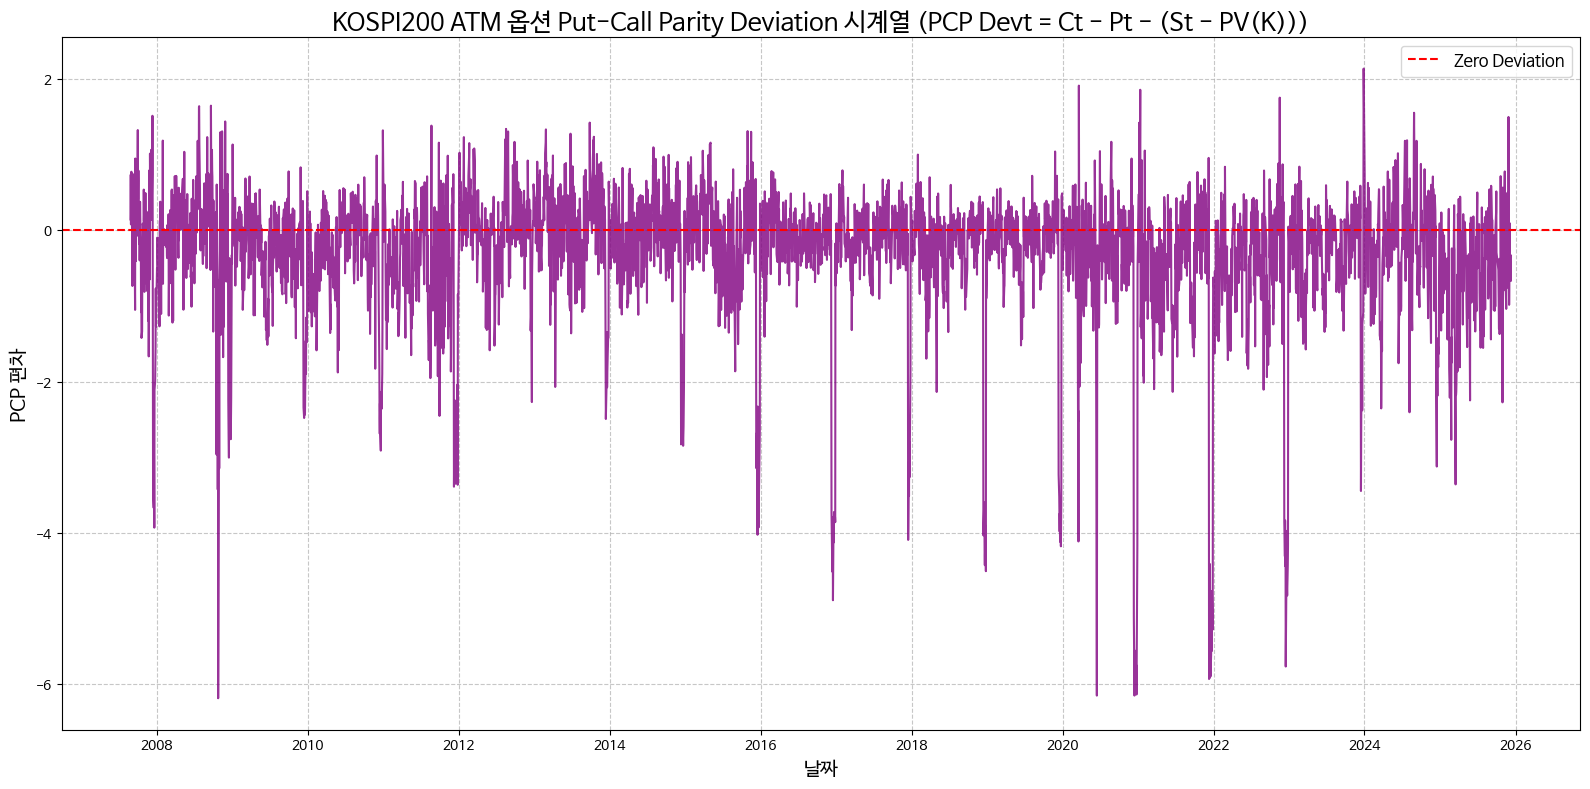

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


--- PCP Deviation 기술 통계량 ---
             Obs        평균      표준편차  skewness   kurtosis       최소값       최대값       중앙값     1사분위수     3사분위수
PCP_Devt  4292.0 -0.294296  0.877961 -2.618036  11.230036 -6.183837  2.135562 -0.137904 -0.549448  0.179708


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


--- 분석 요약 ---
Put-Call Parity (PCP)는 이론적으로 Call 옵션, Put 옵션, 기초자산 현물, 무위험 이자율, 만기일 사이의 관계를 나타냅니다.

PCP Devt = Ct - Pt - (St - PV(K)) 공식에 따라, 이론적으로 이 값은 0이어야 합니다. 시장의 비효율성이나 거래 비용 등으로 인해 0에서 벗어날 수 있습니다.

그래프를 통해 PCP 편차의 시계열을 확인할 수 있으며, 붉은색 점선은 이론적인 0 편차를 나타냅니다.

PCP 편차가 0보다 크다면, 콜옵션이 상대적으로 고평가되었거나 풋옵션이 저평가되었음을 의미할 수 있습니다. 반대로 0보다 작다면 그 반대입니다.

기술 통계량은 편차의 전반적인 특성(평균, 변동성, 왜도, 첨도)을 제공하여 체계적인 편향이 있었는지 파악하는 데 도움을 줍니다.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Assuming final_ts_df is already loaded and available from previous steps
# If not, load it:
# final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)

# Assuming kospi200_final_with_ltd_df is also available for S_t and rf
# If not, it needs to be loaded or reconstructed from its last saved state.

print("Calculating Put-Call Parity Deviation...")

# 1. Prepare data for PCP calculation
# Ensure final_ts_df index is datetime for merging
if not isinstance(final_ts_df.index, pd.DatetimeIndex):
    final_ts_df.index = pd.to_datetime(final_ts_df.index)

# Extract S_t and rf from kospi200_final_with_ltd_df
# Ensure '일자_datetime' in kospi200_final_with_ltd_df is datetime
kospi200_final_with_ltd_df['일자_datetime'] = pd.to_datetime(kospi200_final_with_ltd_df['일자_datetime'])

# Create a unique daily S_t and rf dataframe
daily_market_data = kospi200_final_with_ltd_df[[
    '일자_datetime', 'S_t', 'rf'
]].drop_duplicates(subset=['일자_datetime']).set_index('일자_datetime')

# Merge S_t and rf into final_ts_df
final_ts_df = final_ts_df.merge(
    daily_market_data,
    left_index=True,
    right_index=True,
    how='left'
)

# Handle missing risk-free rates: forward-fill and then drop any remaining NaNs
# This assumes that previous days' rates are the best estimate for missing ones.
final_ts_df['rf'] = final_ts_df['rf'].ffill()
# Drop rows where critical data for PCP calculation is still missing after ffill
# This includes S_t (underlying price), K (strike), Ct/Pt (option prices), rf, TTM
required_cols = [
    'C_1.0_price', 'P_1.0_price', 'C_1.0_strike_price', 'C_1.0_TTM_years', 'S_t', 'rf'
]
final_ts_df.dropna(subset=required_cols, inplace=True)

# Ensure TTM_years is positive (options must have time to maturity)
final_ts_df = final_ts_df[final_ts_df['C_1.0_TTM_years'] > 0]

# 2. Calculate PCP Deviation for ATM options (Moneyness 1.0)
Ct = final_ts_df['C_1.0_price']
Pt = final_ts_df['P_1.0_price']
St = final_ts_df['S_t']
K = final_ts_df['C_1.0_strike_price'] # Assuming strike prices are the same for call and put pairs
TTM_years = final_ts_df['C_1.0_TTM_years']
rf = final_ts_df['rf'] / 100 # Convert percentage to decimal

# Calculate Present Value of Strike (PV(K))
PV_K = K * np.exp(-rf * TTM_years)

# Calculate PCP Deviation
final_ts_df['PCP_Devt'] = Ct - Pt - (St - PV_K)

print("PCP Deviation calculation complete.")

# 3. Time Series Plot of PCP Deviation
plt.figure(figsize=(16, 8))
sns.lineplot(data=final_ts_df, x=final_ts_df.index, y='PCP_Devt', color='purple', alpha=0.8)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Deviation')

plt.title('KOSPI200 ATM 옵션 Put-Call Parity Deviation 시계열 (PCP Devt = Ct - Pt - (St - PV(K)))', fontsize=18)
plt.xlabel('날짜', fontsize=14)
plt.ylabel('PCP 편차', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plot_filename_ts = 'KOSPI200_PCP_Deviation_TimeSeries.png'
plt.savefig(plot_filename_ts, dpi=300, bbox_inches='tight')
plt.show()
files.download(plot_filename_ts)

# 4. Descriptive Statistics for PCP Deviation
print("\n--- PCP Deviation 기술 통계량 ---")
pcp_devt_stats = final_ts_df['PCP_Devt'].describe(percentiles=[.25, .5, .75]).to_frame().T
# Add skewness and kurtosis
pcp_devt_stats['skewness'] = final_ts_df['PCP_Devt'].skew()
pcp_devt_stats['kurtosis'] = final_ts_df['PCP_Devt'].kurtosis()

pcp_devt_stats = pcp_devt_stats.rename(columns={
    'count': 'Obs',
    'mean': '평균',
    'std': '표준편차',
    'min': '최소값',
    'max': '최대값',
    '50%': '중앙값',
    '25%': '1사분위수',
    '75%': '3사분위수'
})

final_stats_order = ['Obs', '평균', '표준편차', 'skewness', 'kurtosis', '최소값', '최대값', '중앙값', '1사분위수', '3사분위수']
pcp_devt_stats = pcp_devt_stats[final_stats_order]

print(pcp_devt_stats.to_string())

output_stats_filename = 'KOSPI200_PCP_Deviation_Statistics.csv'
pcp_devt_stats.to_csv(output_stats_filename, encoding='utf-8-sig')
files.download(output_stats_filename)

print("\n--- 분석 요약 ---")
print("Put-Call Parity (PCP)는 이론적으로 Call 옵션, Put 옵션, 기초자산 현물, 무위험 이자율, 만기일 사이의 관계를 나타냅니다.\n")
print("PCP Devt = Ct - Pt - (St - PV(K)) 공식에 따라, 이론적으로 이 값은 0이어야 합니다. 시장의 비효율성이나 거래 비용 등으로 인해 0에서 벗어날 수 있습니다.\n")
print("그래프를 통해 PCP 편차의 시계열을 확인할 수 있으며, 붉은색 점선은 이론적인 0 편차를 나타냅니다.\n")
print("PCP 편차가 0보다 크다면, 콜옵션이 상대적으로 고평가되었거나 풋옵션이 저평가되었음을 의미할 수 있습니다. 반대로 0보다 작다면 그 반대입니다.\n")
print("기술 통계량은 편차의 전반적인 특성(평균, 변동성, 왜도, 첨도)을 제공하여 체계적인 편향이 있었는지 파악하는 데 도움을 줍니다.")


Volatility skew

Calculating Volatility Skew (Skewt = IV0.9,t - IV1.0,t)...
Volatility Skew calculation complete.


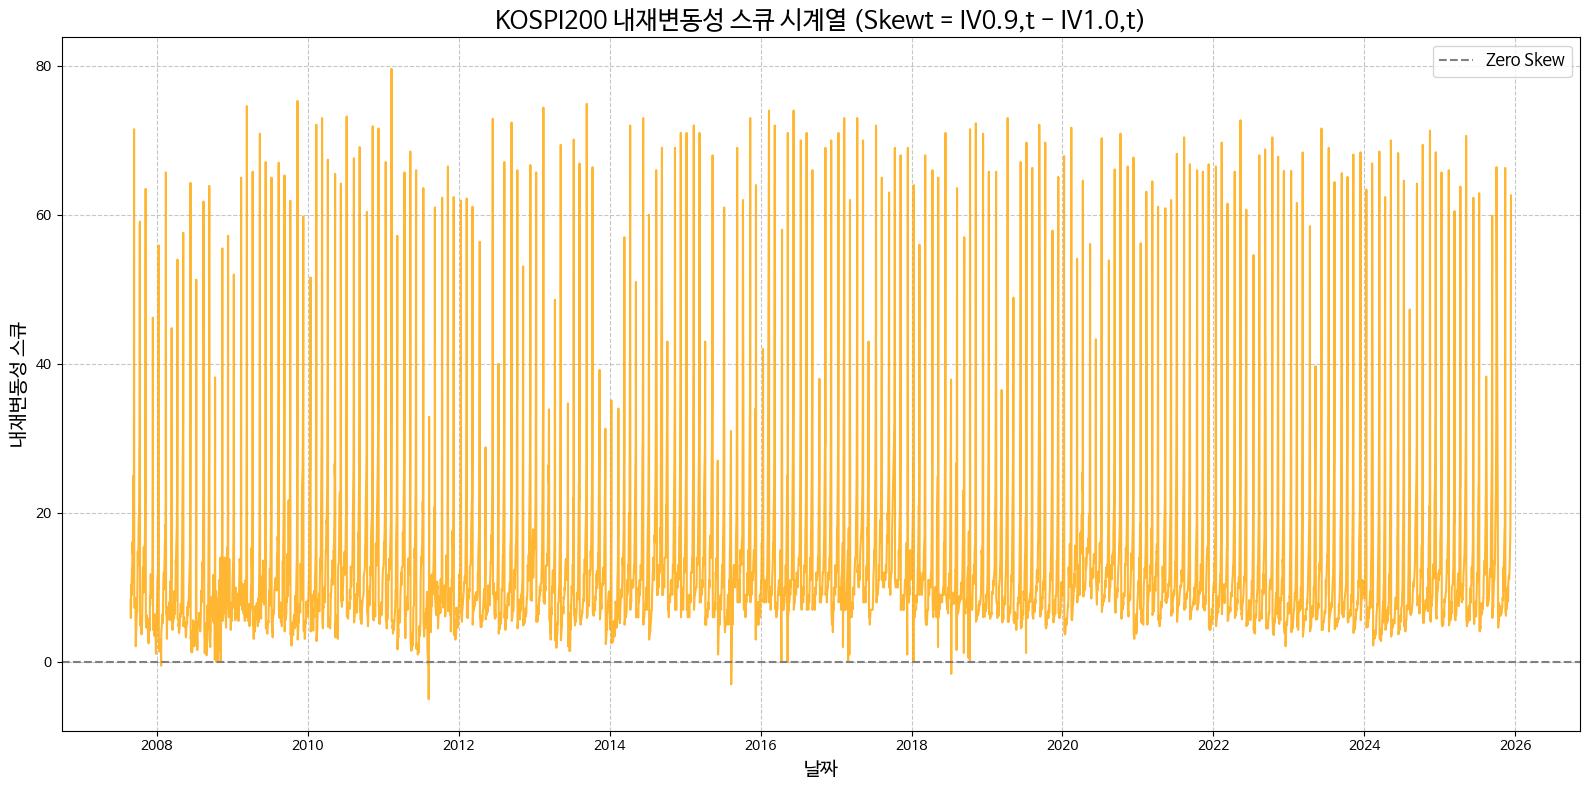

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


--- Volatility Skew 기술 통계량 ---
                    Obs         평균       표준편차  skewness  kurtosis  최소값   최대값  중앙값  1사분위수  3사분위수
Volatility_Skew  4499.0  13.631254  13.475337  2.781923  7.891595 -5.0  79.6  9.1    6.7   13.8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


--- 내재변동성 스큐 (Volatility Skew) 분석 요약 ---
내재변동성 스큐는 동일한 기초자산과 만기를 가지는 옵션들 중에서 행사가격(K)에 따라 내재변동성(Implied Volatility, IV)이 달라지는 현상을 의미합니다.
일반적으로 주식시장에서는 '음의 스큐(Negative Skew)' 또는 '스마일(Skew/Smirk)' 현상이 관찰됩니다.
이는 외가격(OTM) 풋옵션(Moneyness < 1.0 또는 Skewt > 0)의 내재변동성이 등가격(ATM) 옵션(Moneyness = 1.0)보다 높은 경향을 보이며,
이는 투자자들이 주가 하락 위험(꼬리 위험)에 대해 더 높은 보험료를 지불할 의사가 있음을 나타냅니다.
계산된 Skewt = IV0.9,t - IV1.0,t는 ATM(Moneyness 1.0) 대비 OTM(Moneyness 0.9) 풋옵션의 내재변동성 차이를 나타냅니다.
만약 Skewt 값이 양수이면 OTM 풋옵션의 IV가 ATM 옵션의 IV보다 높다는 의미이며, 이는 시장이 하방 위험을 더 높게 평가하고 있음을 시사합니다.
시계열 그래프와 기술 통계량을 통해 KOSPI200 옵션 시장의 변동성 스큐 특성과 변화를 이해할 수 있습니다.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
from google.colab import files

# Ensure Korean font is set up
if 'NanumBarunGothic' not in plt.rcParams['font.family']:
    try:
        !sudo apt-get update -qq
        !sudo apt-get install -y fonts-nanum
        !fc-cache -fv
        fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf')
        plt.rcParams['font.family'] = 'NanumBarunGothic'
        plt.rcParams['axes.unicode_minus'] = False # For correct minus sign display
        print("NanumBarunGothic font applied.")
    except Exception as e:
        print(f"Error applying font: {e}. Plotting may show garbled text.")

# Assuming final_ts_df is already loaded and available from previous steps
# If not, load it:
if 'final_ts_df' not in locals():
    try:
        final_ts_df = pd.read_csv('KOSPI200_fixed_moneyness_time_series.csv', index_col='date', parse_dates=True)
        print("Loaded KOSPI200_fixed_moneyness_time_series.csv into final_ts_df.")
    except FileNotFoundError:
        print("Error: KOSPI200_fixed_moneyness_time_series.csv not found. Please ensure it has been created.")
        # Exit or handle error appropriately
        exit()

print("Calculating Volatility Skew (Skewt = IV0.9,t - IV1.0,t)...")

# Ensure the implied volatility columns exist and are numeric
required_iv_cols = ['P_0.9_implied_volatility', 'P_1.0_implied_volatility']
for col in required_iv_cols:
    if col not in final_ts_df.columns:
        print(f"Error: Required column '{col}' not found in final_ts_df. Cannot calculate Volatility Skew.")
        exit()
    # Convert to numeric, coercing errors to NaN
    final_ts_df[col] = pd.to_numeric(final_ts_df[col], errors='coerce')

# Calculate Volatility Skew for Put options
final_ts_df['Volatility_Skew'] = final_ts_df['P_0.9_implied_volatility'] - final_ts_df['P_1.0_implied_volatility']

print("Volatility Skew calculation complete.")

# --- 1. Time Series Plot of Volatility Skew ---
plt.figure(figsize=(16, 8))
sns.lineplot(data=final_ts_df, x=final_ts_df.index, y='Volatility_Skew', color='orange', alpha=0.8)
plt.axhline(0, color='gray', linestyle='--', linewidth=1.5, label='Zero Skew')

plt.title('KOSPI200 내재변동성 스큐 시계열 (Skewt = IV0.9,t - IV1.0,t)', fontsize=18)
plt.xlabel('날짜', fontsize=14)
plt.ylabel('내재변동성 스큐', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plot_filename_skew = 'KOSPI200_Volatility_Skew_TimeSeries.png'
plt.savefig(plot_filename_skew, dpi=300, bbox_inches='tight')
plt.show()
files.download(plot_filename_skew)

# --- 2. Descriptive Statistics for Volatility Skew ---
print("\n--- Volatility Skew 기술 통계량 ---")
skew_stats = final_ts_df['Volatility_Skew'].describe(percentiles=[.25, .5, .75]).to_frame().T
# Add skewness and kurtosis
skew_stats['skewness'] = final_ts_df['Volatility_Skew'].skew()
skew_stats['kurtosis'] = final_ts_df['Volatility_Skew'].kurtosis()

skew_stats = skew_stats.rename(columns={
    'count': 'Obs',
    'mean': '평균',
    'std': '표준편차',
    'min': '최소값',
    'max': '최대값',
    '50%': '중앙값',
    '25%': '1사분위수',
    '75%': '3사분위수'
})

final_stats_order = ['Obs', '평균', '표준편차', 'skewness', 'kurtosis', '최소값', '최대값', '중앙값', '1사분위수', '3사분위수']
skew_stats = skew_stats[final_stats_order]

print(skew_stats.to_string())

output_stats_filename_skew = 'KOSPI200_Volatility_Skew_Statistics.csv'
skew_stats.to_csv(output_stats_filename_skew, encoding='utf-8-sig')
files.download(output_stats_filename_skew)

# --- 3. Brief Interpretation of Volatility Skew ---
print("\n--- 내재변동성 스큐 (Volatility Skew) 분석 요약 ---")
print("내재변동성 스큐는 동일한 기초자산과 만기를 가지는 옵션들 중에서 행사가격(K)에 따라 내재변동성(Implied Volatility, IV)이 달라지는 현상을 의미합니다.")
print("일반적으로 주식시장에서는 '음의 스큐(Negative Skew)' 또는 '스마일(Skew/Smirk)' 현상이 관찰됩니다.")
print("이는 외가격(OTM) 풋옵션(Moneyness < 1.0 또는 Skewt > 0)의 내재변동성이 등가격(ATM) 옵션(Moneyness = 1.0)보다 높은 경향을 보이며,")
print("이는 투자자들이 주가 하락 위험(꼬리 위험)에 대해 더 높은 보험료를 지불할 의사가 있음을 나타냅니다.")
print("계산된 Skewt = IV0.9,t - IV1.0,t는 ATM(Moneyness 1.0) 대비 OTM(Moneyness 0.9) 풋옵션의 내재변동성 차이를 나타냅니다.")
print("만약 Skewt 값이 양수이면 OTM 풋옵션의 IV가 ATM 옵션의 IV보다 높다는 의미이며, 이는 시장이 하방 위험을 더 높게 평가하고 있음을 시사합니다.")
print("시계열 그래프와 기술 통계량을 통해 KOSPI200 옵션 시장의 변동성 스큐 특성과 변화를 이해할 수 있습니다.")
